In [ ]:
# ============================================================
# CELL 1 — ENVIRONMENT SETUP
# Prepare Python runtime, install dependencies, mount Drive,
# initialize Spark, and scaffold project directory structure.
# ============================================================

# ------------------------------------------------------------
# 1. Install required libraries
# ------------------------------------------------------------

!pip install -q pyspark networkx seaborn scikit-learn statsmodels

# ------------------------------------------------------------
# 2. Standard library imports
# ------------------------------------------------------------

import os
import json
import pickle
import random

# ------------------------------------------------------------
# 3. Third-party imports
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from pyspark.sql import SparkSession

# ------------------------------------------------------------
# 4. Reproducibility seeds
# ------------------------------------------------------------

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# ------------------------------------------------------------
# 5. Visualization defaults
# ------------------------------------------------------------

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"]  = 14
plt.rcParams["axes.labelsize"]  = 12
sns.set_style("whitegrid")

# ------------------------------------------------------------
# 6. Mount Google Drive
#    All paths must live under DRIVE_ROOT — never mix with
#    ephemeral /tmp or /content paths or checkpoints will be
#    lost when the Colab runtime restarts.
# ------------------------------------------------------------

from google.colab import drive

# FIX: Ensure mount point is empty before mounting
if os.path.exists('/content/drive') and os.path.isdir('/content/drive'):
    if os.listdir('/content/drive'):
        print("Clearing non-empty /content/drive before mount...")
        !rm -rf /content/drive/*

drive.mount("/content/drive", force_remount=True)

# ------------------------------------------------------------
# 7. Project directory constants
#    Single source of truth — import these in every cell.
#    Never hard-code paths elsewhere in the notebook.
# ------------------------------------------------------------

DRIVE_ROOT    = "/content/drive/MyDrive"
PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")

# Sub-directories
RAW_DATA_DIR        = os.path.join(PROJECT_ROOT, "raw_data")
PROCESSED_DATA_DIR  = os.path.join(PROJECT_ROOT, "processed_data")
CHECKPOINTS_DIR     = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
MODELS_DIR          = os.path.join(PROJECT_ROOT, "models")
OUTPUTS_DIR         = os.path.join(PROJECT_ROOT, "outputs")
EXPERIMENTS_DIR     = os.path.join(PROJECT_ROOT, "experiments")
METRICS_DIR         = os.path.join(PROJECT_ROOT, "metrics")
VISUALIZATIONS_DIR  = os.path.join(PROJECT_ROOT, "visualizations")
REGISTRY_DIR        = os.path.join(PROJECT_ROOT, "registry")
COUNTRY_FEATURES_DIR= os.path.join(PROJECT_ROOT, "country_features")

ALL_DIRS = [
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    CHECKPOINTS_DIR,
    MODELS_DIR,
    OUTPUTS_DIR,
    EXPERIMENTS_DIR,
    METRICS_DIR,
    VISUALIZATIONS_DIR,
    REGISTRY_DIR,
    COUNTRY_FEATURES_DIR,
]

for path in ALL_DIRS:
    os.makedirs(path, exist_ok=True)

print(" Project directories ready:")
for path in ALL_DIRS:
    print(f"   {path}")

# ------------------------------------------------------------
# 8. Spark session
#    - checkpointDir points to Drive so partial results
#      survive runtime crashes and restarts.
#    - executor.memory and driver.memory set conservatively
#      for Colab's ~12 GB RAM; raise if you upgrade hardware.
#    - Adaptive Query Execution (AQE) enabled for automatic
#      join/shuffle optimisation.
# ------------------------------------------------------------

spark = (
    SparkSession.builder
    .appName("LPGSupplyAnalysis")
    .master("local[*]")                                      # use all available cores
    .config("spark.driver.memory",            "4g")
    .config("spark.executor.memory",          "4g")
    .config("spark.sql.adaptive.enabled",     "true")        # AQE: auto-optimise plans
    .config("spark.sql.shuffle.partitions",   "8")           # low default for single-node Colab
    .config("spark.ui.showConsoleProgress",   "false")       # keep output clean
    .config("spark.checkpoint.dir",           CHECKPOINTS_DIR)
    .getOrCreate()
)

# Set checkpoint directory so DataFrame.checkpoint() persists
# intermediate results to Drive rather than re-running upstream stages.
spark.sparkContext.setCheckpointDir(CHECKPOINTS_DIR)

# Surface key runtime info
print("\n Spark session started")
print(f"   Version  : {spark.version}")
print(f"   Master   : {spark.sparkContext.master}")
print(f"   App name : {spark.sparkContext.appName}")
print(f"   Checkpoint: {CHECKPOINTS_DIR}")

# ------------------------------------------------------------
# 9. Checkpoint helper
#    Use this wrapper around expensive DataFrame transforms.
#    If the checkpoint file already exists on Drive the
#    transformation is skipped entirely — no recomputation.
#
#    Usage:
#        df_clean = checkpoint_df(df_raw, "01_cleaned")
# ------------------------------------------------------------

import os
import shutil

def checkpoint_df(df, name, overwrite=True, verbose=True):
    path = os.path.join(CHECKPOINTS_DIR, name)

    if overwrite:
        # 🔥 Always remove old checkpoint to avoid stale loads
        if os.path.exists(path):
            shutil.rmtree(path)

        df.write.mode("overwrite").parquet(path)

        if verbose:
            print(f"✓ Checkpoint saved (overwrite): {name}")

    else:
        # Load if exists, else save
        if os.path.exists(path):
            if verbose:
                print(f"↩ Loading checkpoint: {name}")
            return spark.read.parquet(path)

        df.write.parquet(path)
        if verbose:
            print(f"✓ Checkpoint created: {name}")

    return spark.read.parquet(path)

# ------------------------------------------------------------
# 10. Sanity check
# ------------------------------------------------------------

_test = spark.createDataFrame([(1, "ok")], ["id", "status"])
assert _test.count() == 1, "Spark smoke-test failed"
print("\n Spark smoke-test passed — environment is ready.\n")

Mounted at /content/drive
 Project directories ready:
   /content/drive/MyDrive/LPGSupplyAnalysis/raw_data
   /content/drive/MyDrive/LPGSupplyAnalysis/processed_data
   /content/drive/MyDrive/LPGSupplyAnalysis/pipeline_checkpoints
   /content/drive/MyDrive/LPGSupplyAnalysis/models
   /content/drive/MyDrive/LPGSupplyAnalysis/outputs
   /content/drive/MyDrive/LPGSupplyAnalysis/experiments
   /content/drive/MyDrive/LPGSupplyAnalysis/metrics
   /content/drive/MyDrive/LPGSupplyAnalysis/visualizations
   /content/drive/MyDrive/LPGSupplyAnalysis/registry
   /content/drive/MyDrive/LPGSupplyAnalysis/country_features

 Spark session started
   Version  : 4.0.2
   Master   : local[*]
   App name : LPGSupplyAnalysis
   Checkpoint: /content/drive/MyDrive/LPGSupplyAnalysis/pipeline_checkpoints

 Spark smoke-test passed — environment is ready.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# CELL 2 — DATA INGESTION
# Upload dataset once → save to Drive → load from Drive every
# subsequent session. Validate schema, cast types, convert to
# Parquet for fast distributed processing.
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.types import IntegerType, DoubleType

# ------------------------------------------------------------
# Path constants (must match Cell 1)
# ------------------------------------------------------------

RAW_DATA_DIR   = os.path.join(PROJECT_ROOT, "raw_data")
CHECKPOINTS_DIR= os.path.join(PROJECT_ROOT, "pipeline_checkpoints")

# Canonical Drive paths — all future cells read from these
RAW_CSV_PATH    = os.path.join(RAW_DATA_DIR,    "lpg_dataset.csv")
RAW_PARQUET_PATH= os.path.join(CHECKPOINTS_DIR, "raw.parquet")

# ------------------------------------------------------------
# STEP 1 — Upload CSV once; persist to Drive for all sessions
#
#   • If lpg_dataset.csv already exists on Drive  → skip upload
#   • Otherwise prompt for file, save to Drive, never re-upload
# ------------------------------------------------------------

if os.path.exists(RAW_CSV_PATH):
    print(f" Dataset already on Drive → {RAW_CSV_PATH}")
    print("   Skipping upload.")
else:
    print("📤 Dataset not found on Drive. Uploading now (one-time only)…")
    from google.colab import files
    uploaded = files.upload()                          # opens file picker

    if not uploaded:
        raise FileNotFoundError("No file selected. Re-run this cell and choose your CSV.")

    upload_filename = list(uploaded.keys())[0]

    # Write raw bytes to the canonical Drive path
    with open(RAW_CSV_PATH, "wb") as f:
        f.write(uploaded[upload_filename])

    print(f"Saved to Drive → {RAW_CSV_PATH}")
    print("   You will NOT need to upload again in future sessions.")

# ------------------------------------------------------------
# STEP 2 — Load raw CSV into Spark
#           inferSchema=True gives us a baseline; we'll tighten
#           data types explicitly in Step 4.
# ------------------------------------------------------------

print("\n Loading CSV into Spark…")

df_raw = (
    spark.read
    .option("header",        "true")
    .option("inferSchema",   "true")
    .option("multiLine",     "true")   # handles embedded newlines in strings
    .option("escape",        '"')
    .option("delimiter",     ";")      # ADDED: Specify semicolon as delimiter
    .csv(RAW_CSV_PATH)
)

print("\n── Raw schema (as-loaded) ──────────────────────────────")
df_raw.printSchema()
print(f"Row count  : {df_raw.count():,}")
print(f"Column count: {len(df_raw.columns)}")

# ------------------------------------------------------------
# STEP 3 — Rename columns to clean, consistent names
#           Maps the IEA source column names → project names
# ------------------------------------------------------------

COLUMN_MAP = {
    "REF_AREA"   : "country",
    "COMMODITY"  : "product",
    "TRANSACTION": "indicator",
    "TIME_PERIOD": "year",
    "Periodicity": "Periodicity",
    "OBS_VALUE"  : "value",
    "UNIT_MEASURE": "unit"
}

# Validate all expected source columns are present
missing_cols = [c for c in COLUMN_MAP if c not in df_raw.columns]
if missing_cols:
    raise ValueError(
        f" Expected columns missing from CSV: {missing_cols}\n"
        f"   Found: {df_raw.columns}"
    )

df_renamed = df_raw.select(
    [F.col(src).alias(tgt) for src, tgt in COLUMN_MAP.items()]
)

# ------------------------------------------------------------
# STEP 4 — Enforce correct data types
#           inferSchema may guess wrong (e.g. year as string)
# ------------------------------------------------------------

df_typed = (
    df_renamed
    .withColumn("year",  F.col("year") .cast(IntegerType()))
    .withColumn("value", F.col("value").cast(DoubleType()))
)

print("\n── Parsed schema (after rename + cast) ─────────────────")
df_typed.printSchema()

# ------------------------------------------------------------
# STEP 5 — Preview
# ------------------------------------------------------------

print("\n── Parsed dataset preview ───────────────────────────────")
df_typed.show(5, truncate=True)

# ------------------------------------------------------------
# STEP 6 — Data quality checks
# ------------------------------------------------------------

print("\n── Missing value check ──────────────────────────────────")
df_typed.select(
    [F.count(F.col(c)).alias(c) for c in df_typed.columns]
).show()

null_values = df_typed.select(
    [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df_typed.columns]
)
print("Null counts per column:")
null_values.show()

dupe_count = df_typed.count() - df_typed.dropDuplicates().count()
print(f"Duplicate records: {dupe_count}")

# ------------------------------------------------------------
# STEP 7 — Exploratory distribution checks
# ------------------------------------------------------------

print("\n── Indicator distribution ───────────────────────────────")
(
    df_typed
    .groupBy("indicator")
    .count()
    .orderBy(F.desc("count"))
    .show(20, truncate=True)
)

country_count = df_typed.select("country").distinct().count()
print(f"Countries covered: {country_count}")

print("\n── Year range ───────────────────────────────────────────")
(
    df_typed
    .agg(
        F.min("year").alias("min_year"),
        F.max("year").alias("max_year")
    )
    .show()
)

# ------------------------------------------------------------
# STEP 8 — Save to Parquet checkpoint (skip if already exists)
#           Parquet is ~10x faster to read than CSV and
#           preserves data types across sessions.
# ------------------------------------------------------------

if os.path.exists(RAW_PARQUET_PATH):
    print(f"\n Parquet checkpoint already exists → {RAW_PARQUET_PATH}")
    print("   Loading from checkpoint (no rewrite).")
    df_parsed = spark.read.parquet(RAW_PARQUET_PATH)
else:
    print(f"\n Writing Parquet checkpoint → {RAW_PARQUET_PATH}")
    (
        df_typed
        .write
        .mode("overwrite")
        .parquet(RAW_PARQUET_PATH)
    )
    df_parsed = spark.read.parquet(RAW_PARQUET_PATH)
    print(" Parquet checkpoint saved.")

# ------------------------------------------------------------
# STEP 9 — Confirm final DataFrame is ready for downstream cells
# ------------------------------------------------------------

print(f"\n df_parsed ready  |  rows: {df_parsed.count():,}  |  cols: {len(df_parsed.columns)}")
print(f"   Source : {RAW_PARQUET_PATH}")
print("\nFuture sessions: Spark reads directly from Parquet — CSV upload never needed again.")


📤 Dataset not found on Drive. Uploading now (one-time only)…


Saving production-trade-and-supply-of-liquefied-petroleum-gases-lpg.csv to production-trade-and-supply-of-liquefied-petroleum-gases-lpg.csv
Saved to Drive → /content/drive/MyDrive/LPGSupplyAnalysis/raw_data/lpg_dataset.csv
   You will NOT need to upload again in future sessions.

 Loading CSV into Spark…

── Raw schema (as-loaded) ──────────────────────────────
root
 |-- REF_AREA: string (nullable = true)
 |-- COMMODITY: string (nullable = true)
 |-- TRANSACTION: string (nullable = true)
 |-- TIME_PERIOD: integer (nullable = true)
 |-- Periodicity: string (nullable = true)
 |-- OBS_VALUE: double (nullable = true)
 |-- UNIT_MEASURE: string (nullable = true)

Row count  : 96,842
Column count: 7

── Parsed schema (after rename + cast) ─────────────────
root
 |-- country: string (nullable = true)
 |-- product: string (nullable = true)
 |-- indicator: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- Periodicity: string (nullable = true)
 |-- value: double (nullable = true)

In [ ]:
# ============================================================
# CELL 3 — INITIAL DATA VALIDATION
# Completeness, duplicates, structural consistency checks.
# Saves a JSON validation report to Drive as checkpoint.
# ============================================================

import os
import json
from pyspark.sql import functions as F
from datetime import datetime

# ------------------------------------------------------------
# Path constants
# ------------------------------------------------------------

CHECKPOINTS_DIR     = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
VALIDATION_RPT_PATH = os.path.join(CHECKPOINTS_DIR, "data_validation_report")
RAW_PARQUET_PATH    = os.path.join(CHECKPOINTS_DIR, "raw.parquet")

# ------------------------------------------------------------
# STEP 1 — Load from Parquet checkpoint (never re-read CSV)
# ------------------------------------------------------------

print("📥 Loading df_parsed from Parquet checkpoint…")
df = spark.read.parquet(RAW_PARQUET_PATH)

EXPECTED_COLS = ["country", "product", "indicator", "year", "Periodicity", "value", "unit"]
missing_cols  = [c for c in EXPECTED_COLS if c not in df.columns]
if missing_cols:
    raise ValueError(f"❌ Schema mismatch — missing columns: {missing_cols}")

print(f"✅ Schema OK  |  rows: {df.count():,}  |  cols: {len(df.columns)}")

# ------------------------------------------------------------
# STEP 2 — Record count
# ------------------------------------------------------------

total_rows = df.count()
print(f"\n── Record count ─────────────────────────────────────────")
print(f"   Total rows : {total_rows:,}")

# ------------------------------------------------------------
# STEP 3 — Duplicate check
# ------------------------------------------------------------

deduped_count = df.dropDuplicates().count()
dupe_count    = total_rows - deduped_count

print(f"\n── Duplicate check ──────────────────────────────────────")
print(f"   Unique rows     : {deduped_count:,}")
print(f"   Duplicate rows  : {dupe_count}")

if dupe_count > 0:
    print("   ⚠️  Duplicates found — investigating keys…")
    key_cols = ["country", "indicator", "year", "product"]
    (
        df.groupBy(key_cols).count()
          .filter(F.col("count") > 1)
          .orderBy(F.desc("count"))
          .show(10, truncate=True)
    )
else:
    print("   ✅ No duplicates detected.")

# ------------------------------------------------------------
# STEP 4 — Missing / null value audit per column
# ------------------------------------------------------------

print(f"\n── Null value audit ─────────────────────────────────────")
null_counts = {
    c: df.filter(F.col(c).isNull()).count()
    for c in df.columns
}
null_df = spark.createDataFrame(
    [(col, cnt) for col, cnt in null_counts.items()],
    ["column", "null_count"]
)
null_df.show(truncate=False)

total_nulls = sum(null_counts.values())
print(f"   Total nulls across all columns : {total_nulls:,}")

# ------------------------------------------------------------
# STEP 5 — Non-null count confirmation (matches Cell 2 output)
# ------------------------------------------------------------

print(f"\n── Non-null counts per column ───────────────────────────")
df.select([F.count(F.col(c)).alias(c) for c in df.columns]).show()

# ------------------------------------------------------------
# STEP 6 — Data type consistency check
# ------------------------------------------------------------

print(f"\n── Data type audit ──────────────────────────────────────")
EXPECTED_DTYPES = {
    "country"    : "string",
    "product"    : "string",
    "indicator"  : "string",
    "year"       : "int",
    "Periodicity": "string",
    "value"      : "double",
    "unit"       : "string",
}

dtype_issues   = []
actual_dtypes  = dict(df.dtypes)

for col, expected in EXPECTED_DTYPES.items():
    actual = actual_dtypes.get(col, "MISSING")
    status = "✅" if actual == expected else "❌"
    if actual != expected:
        dtype_issues.append({"column": col, "expected": expected, "actual": actual})
    print(f"   {status}  {col:<14}  expected={expected:<8}  actual={actual}")

# ------------------------------------------------------------
# STEP 7 — Logical / value-range checks
#   "No missing values does NOT mean data is perfect"
# ------------------------------------------------------------

print(f"\n── Logical consistency checks ───────────────────────────")

neg_values  = df.filter(F.col("value") < 0).count()
zero_values = df.filter(F.col("value") == 0).count()
print(f"   Negative 'value' entries  : {neg_values:,}")
print(f"   Zero 'value' entries      : {zero_values:,}")

year_stats = df.agg(
    F.min("year").alias("min_year"),
    F.max("year").alias("max_year")
).collect()[0]
year_ok = 1990 <= year_stats["min_year"] and year_stats["max_year"] <= 2024
print(f"   Year range  : {year_stats['min_year']} – {year_stats['max_year']}  {'✅' if year_ok else '⚠️'}")

print(f"\n   Periodicity values:")
df.groupBy("Periodicity").count().orderBy(F.desc("count")).show(truncate=False)

print(f"   Unit values:")
df.groupBy("unit").count().orderBy(F.desc("count")).show(truncate=False)

# ------------------------------------------------------------
# STEP 8 — Column cardinality summary
# ------------------------------------------------------------

print(f"\n── Column cardinality ───────────────────────────────────")
for c in ["country", "product", "indicator", "year", "Periodicity", "unit"]:
    distinct = df.select(c).distinct().count()
    print(f"   {c:<14}  distinct values: {distinct:,}")

# ------------------------------------------------------------
# STEP 9 — Build validation report and save to Drive
# ------------------------------------------------------------

validation_report = {
    "generated_at"     : datetime.now().isoformat(),
    "total_rows"       : total_rows,
    "unique_rows"      : deduped_count,
    "duplicate_rows"   : dupe_count,
    "total_nulls"      : total_nulls,
    "null_per_column"  : null_counts,
    "dtype_issues"     : dtype_issues,
    "negative_values"  : neg_values,
    "zero_values"      : zero_values,
    "year_min"         : int(year_stats["min_year"]),
    "year_max"         : int(year_stats["max_year"]),
    "year_range_ok"    : bool(year_ok),
    "validation_passed": (dupe_count == 0 and total_nulls == 0 and not dtype_issues),
}

os.makedirs(VALIDATION_RPT_PATH, exist_ok=True)
report_file = os.path.join(VALIDATION_RPT_PATH, "summary.json")

with open(report_file, "w") as f:
    json.dump(validation_report, f, indent=2)

print(f"\nValidation report saved → {report_file}")

# ------------------------------------------------------------
# STEP 10 — Final verdict
# ------------------------------------------------------------

print("\n── Validation verdict ───────────────────────────────────")
if validation_report["validation_passed"]:
    print("   PASSED  — no nulls, no duplicates, schema correct.")
else:
    print("     ISSUES FOUND — review items flagged above before proceeding.")
    if dupe_count  : print(f"      • {dupe_count} duplicate rows")
    if total_nulls : print(f"      • {total_nulls} null values")
    if dtype_issues: print(f"      • {len(dtype_issues)} dtype mismatches: {dtype_issues}")

print("\n  REMINDER: 'No missing values' does NOT mean data is correct.")
print("   Logical checks (negatives, zero values, year range) must also pass.")


📥 Loading df_parsed from Parquet checkpoint…
✅ Schema OK  |  rows: 96,842  |  cols: 7

── Record count ─────────────────────────────────────────
   Total rows : 96,842

── Duplicate check ──────────────────────────────────────
   Unique rows     : 96,842
   Duplicate rows  : 0
   ✅ No duplicates detected.

── Null value audit ─────────────────────────────────────
+-----------+----------+
|column     |null_count|
+-----------+----------+
|country    |0         |
|product    |0         |
|indicator  |0         |
|year       |0         |
|Periodicity|0         |
|value      |0         |
|unit       |0         |
+-----------+----------+

   Total nulls across all columns : 0

── Non-null counts per column ───────────────────────────
+-------+-------+---------+-----+-----------+-----+-----+
|country|product|indicator| year|Periodicity|value| unit|
+-------+-------+---------+-----+-----------+-----+-----+
|  96842|  96842|    96842|96842|      96842|96842|96842|
+-------+-------+---------+--

In [ ]:
# ============================================================
# CELL 4 — FINAL DATA CLEANING (STRICT, NO WHITELIST)
# ============================================================

import os
import shutil
from pyspark.sql import functions as F

CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
RAW_PARQUET_PATH = os.path.join(CHECKPOINTS_DIR, "raw.parquet")

# ------------------------------------------------------------
# CHECKPOINT FUNCTION
# ------------------------------------------------------------

def checkpoint_df(df, name):
    path = os.path.join(CHECKPOINTS_DIR, name)

    if os.path.exists(path):
        shutil.rmtree(path)  # 🔥 remove stale checkpoint

    df.write.mode("overwrite").parquet(path)
    print(f"✓ Checkpoint saved: {name}")

    return spark.read.parquet(path)


# ------------------------------------------------------------
# STEP 1 — LOAD
# ------------------------------------------------------------

df = spark.read.parquet(RAW_PARQUET_PATH)

print("Initial countries:", df.select("country").distinct().count())


# ------------------------------------------------------------
# STEP 2 — STANDARDIZE NAMES (FIRST)
# ------------------------------------------------------------

RENAME_MAP = {
    "Congo": "Republic of the Congo",
    "Cote dIvoire": "Côte d’Ivoire",
    "Viet Nam": "Vietnam",
    "TimorLeste": "Timor-Leste",
    "Lao Peoples Democratic Republic": "Laos",
    "Syrian Arab Republic": "Syria",
    "Iran Islamic Republic of": "Iran",
    "Republic of Korea": "South Korea",
    "United Republic of Tanzania": "Tanzania",
    "GuineaBissau": "Guinea-Bissau"
}

df = df.replace(RENAME_MAP, subset=["country"])

print("✓ Country names standardized")


# ------------------------------------------------------------
# STEP 3 — REMOVE INVALID (EXPANDED HARD LIST)
# ------------------------------------------------------------

REMOVE_EXACT = {
    # Historical / split
    "Union of Soviet Socialist Republics",
    "Czechoslovakia",
    "Yugoslavia",
    "Serbia and Montenegro",
    "German Democratic Republic",
    "Germany Federal Republic of",
    "Yemen Arab Republic",
    "Democratic Yemen",
    "Sudan up to 2011",
    "Ethiopia up to 1993",
    "Ethiopia from 1993",

    # Territories / dependencies
    "American Samoa","Anguilla","Aruba","Bermuda",
    "Bonaire Sint Eustatius and Saba","Curacao",
    "Cayman Islands","French Guiana","Guadeloupe",
    "Martinique","Reunion","Mayotte",
    "New Caledonia","French Polynesia",
    "Northern Mariana Islands",
    "Sint Maarten Dutch part",
    "Turks and Caicos Islands",
    "Montserrat","Wallis and Futuna Islands",
    "Falkland Islands Malvinas",
    "Greenland","Jersey","Niue",

    # Deprecated
    "Netherlands Antilles",

    # Aggregates
    "Other Asia","Pacific Islands Trust Territory",

    # SAR
    "China Hong Kong Special Administrative Region",
    "China Macao Special Administrative Region",

    # Bad merges
    "SwitzerlandLiechtenstein",
    "France incl Monaco",
    "Italy and San Marino",

    "Kosovo",
"Palestine"
}

df = df.filter(~F.col("country").isin(REMOVE_EXACT))


# ------------------------------------------------------------
# STEP 4 — PATTERN FILTER (STRICT)
# ------------------------------------------------------------

BAD_PATTERNS = [
    "former",
    "including",
    "up to",
    "from",
    "territory",
    "income",
    "group",
    "world",
    "union",
    "area",
    "zone"
]

pattern_expr = "|".join(BAD_PATTERNS)

df = df.filter(~F.lower(F.col("country")).rlike(pattern_expr))


# ------------------------------------------------------------
# STEP 5 — STRUCTURAL VALIDATION (VERY IMPORTANT)
# ------------------------------------------------------------

# Remove:
# - Very short names (noise)
# - Numbers inside names
# - Weird symbols

df = df.filter(F.length("country") > 3)

df = df.filter(~F.col("country").rlike(r"[0-9]"))

df = df.filter(F.col("country").rlike(r"^[A-Za-zÀ-ÖØ-öø-ÿ\-\s’]+$"))


# ------------------------------------------------------------
# STEP 6 — REMOVE WEAK COUNTRIES
# ------------------------------------------------------------

country_years = (
    df.groupBy("country")
      .agg(F.countDistinct("year").alias("year_count"))
)

df = df.join(
    country_years.filter(F.col("year_count") >= 10),
    on="country",
    how="inner"
).drop("year_count")


# ------------------------------------------------------------
# STEP 7 — FLAGS
# ------------------------------------------------------------

df = df.withColumn(
    "is_invalid_negative",
    (F.col("value") < 0) & (F.col("indicator") != "Stock changes")
)

df = df.withColumn(
    "is_suspicious_zero",
    F.col("value") == 0
)


# ------------------------------------------------------------
# STEP 8 — FINAL CHECK
# ------------------------------------------------------------

print("Final countries (before save):",
      df.select("country").distinct().count())

print("Final rows (before save):", df.count())

df.select("country").distinct().orderBy("country").show(50, False)


# ------------------------------------------------------------
# STEP 9 — SAVE
# ------------------------------------------------------------

df_clean = checkpoint_df(df, "01_cleaned")

print("df_clean rows:", df_clean.count())


# ------------------------------------------------------------
# STEP 10 — VERIFY
# ------------------------------------------------------------

countries = df_clean.select("country").distinct().orderBy("country")

countries.show(200, truncate=False)

print("Final countries (after save):", countries.count())


Initial countries: 226
✓ Country names standardized
Final countries (before save): 179
Final rows (before save): 85521
+------------------------+
|country                 |
+------------------------+
|Afghanistan             |
|Albania                 |
|Algeria                 |
|Andorra                 |
|Angola                  |
|Antigua and Barbuda     |
|Argentina               |
|Armenia                 |
|Australia               |
|Austria                 |
|Azerbaijan              |
|Bahamas                 |
|Bahrain                 |
|Bangladesh              |
|Barbados                |
|Belarus                 |
|Belgium                 |
|Belize                  |
|Benin                   |
|Bhutan                  |
|Bolivia                 |
|Bosnia and Herzegovina  |
|Botswana                |
|Brazil                  |
|Brunei Darussalam       |
|Bulgaria                |
|Burkina Faso            |
|Burundi                 |
|Cabo Verde              |
|Cambodia        

In [ ]:
# ============================================================
# CELL 5 — INDICATOR + DATA QUALITY FILTERING (FINAL)
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 1 — Load cleaned dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "01_cleaned")) # Removed .parquet extension

print(f"Loaded cleaned data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — COUNTRY QUALITY FILTER (CRITICAL)
# ------------------------------------------------------------

country_quality = (
    df.groupBy("country")
      .agg(
          F.countDistinct("year").alias("year_count"),
          F.sum(F.when(F.col("value") > 0, 1).otherwise(0)).alias("non_zero_count")
      )
)

valid_countries = country_quality.filter(
    (F.col("year_count") >= 20) &      # enough history
    (F.col("non_zero_count") >= 10)    # not mostly zeros
)

print("\n── Country quality summary ─────────────────────────")
valid_countries.select(
    F.count("*").alias("valid_country_count")
).show()

# Apply filter
df = df.join(valid_countries.select("country"), on="country", how="inner")

print(f"After country filtering | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 3 — INDICATOR FILTER (SUPPLY ONLY)
# ------------------------------------------------------------

important_indicators = [
    "Production",
    "Imports",
    "Exports",
    "Total energy supply"
]

df_filtered = df.filter(F.col("indicator").isin(important_indicators))

# ------------------------------------------------------------
# STEP 4 — VALIDATION
# ------------------------------------------------------------

print("\n── Indicator distribution ─────────────────────────")
(
    df_filtered
    .groupBy("indicator")
    .count()
    .orderBy(F.desc("count"))
    .show()
)

indicator_count = df_filtered.select("indicator").distinct().count()
country_count   = df_filtered.select("country").distinct().count()

print(f"Indicators retained: {indicator_count}")
print(f"Countries retained : {country_count}")

# ------------------------------------------------------------
# STEP 5 — SAVE CHECKPOINT
# ------------------------------------------------------------

df_final = checkpoint_df(df_filtered, "02_filtered_indicators")

print(f"\ndf_final ready | rows: {df_final.count():,}")


Loaded cleaned data | rows: 85,521

── Country quality summary ─────────────────────────
+-------------------+
|valid_country_count|
+-------------------+
|                172|
+-------------------+

After country filtering | rows: 84,326

── Indicator distribution ─────────────────────────
+-------------------+-----+
|          indicator|count|
+-------------------+-----+
|Total energy supply| 5790|
|            Imports| 5138|
|         Production| 3360|
|            Exports| 2580|
+-------------------+-----+

Indicators retained: 4
Countries retained : 172
✓ Checkpoint saved: 02_filtered_indicators

df_final ready | rows: 16,868


In [ ]:
# ============================================================
# CELL 6 — INITIAL EDA (DISTRIBUTION ANALYSIS)
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 1 — Load filtered dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "02_filtered_indicators"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — BASIC STATISTICS
# ------------------------------------------------------------

stats = df.select(
    F.min("value").alias("min"),
    F.max("value").alias("max"),
    F.mean("value").alias("mean"),
    F.stddev("value").alias("stddev")
).collect()[0]

print("\n── Basic statistics ─────────────────────────────")
for k in stats.asDict():
    print(f"{k:>6} : {stats[k]}")

# ------------------------------------------------------------
# STEP 3 — PERCENTILES (DISTRIBUTION SHAPE)
# ------------------------------------------------------------

percentiles = df.approxQuantile(
    "value",
    [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99],
    0.01
)

labels = ["p1", "p5", "p25", "median", "p75", "p95", "p99"]

print("\n── Percentiles ─────────────────────────────────")
for l, v in zip(labels, percentiles):
    print(f"{l:>7} : {v}")

# ------------------------------------------------------------
# STEP 4 — SKEWNESS
# ------------------------------------------------------------

skewness = df.select(F.skewness("value")).collect()[0][0]
print(f"\nSkewness: {skewness}")

# ------------------------------------------------------------
# STEP 5 — EXTREME VALUE COUNTS
# ------------------------------------------------------------

p1, p99 = percentiles[0], percentiles[-1]

high_outliers = df.filter(F.col("value") > p99).count()
low_outliers  = df.filter(F.col("value") < p1).count()

print("\n── Extreme values ───────────────────────────────")
print(f"High-end outliers (>p99): {high_outliers}")
print(f"Low-end outliers (<p1):  {low_outliers}")

# ------------------------------------------------------------
# STEP 6 — NEGATIVE + ZERO ANALYSIS
# ------------------------------------------------------------

neg_count  = df.filter(F.col("value") < 0).count()
zero_count = df.filter(F.col("value") == 0).count()

print(f"\nNegative values: {neg_count}")
print(f"Zero values: {zero_count}")

# ------------------------------------------------------------
# STEP 7 — INDICATOR-WISE STATS
# ------------------------------------------------------------

print("\n── Indicator-wise stats ─────────────────────────")

(
    df.groupBy("indicator")
      .agg(
          F.min("value").alias("min"),
          F.max("value").alias("max"),
          F.mean("value").alias("mean")
      )
      .orderBy("indicator")
      .show(truncate=False)
)

# ------------------------------------------------------------
# STEP 8 — SAVE SUMMARY (CHECKPOINT)
# ------------------------------------------------------------

summary_path = os.path.join(CHECKPOINTS_DIR, "eda_summary_1")

(
    df.select("value")
      .write
      .mode("overwrite")
      .parquet(summary_path)
)

print(f"\nEDA summary saved → {summary_path}")

Loaded data | rows: 16,868

── Basic statistics ─────────────────────────────
   min : -165.43298100000004
   max : 98106.768
  mean : 1162.0773408049874
stddev : 4539.244173658368

── Percentiles ─────────────────────────────────
     p1 : -165.43298100000004
     p5 : 0.297
    p25 : 8.4
 median : 81.0
    p75 : 481.0
    p95 : 4078.0
    p99 : 98106.768

Skewness: 9.108432608558202

── Extreme values ───────────────────────────────
High-end outliers (>p99): 0
Low-end outliers (<p1):  0

Negative values: 4
Zero values: 551

── Indicator-wise stats ─────────────────────────
+-------------------+-------------------+---------+------------------+
|indicator          |min                |max      |mean              |
+-------------------+-------------------+---------+------------------+
|Exports            |0.0                |69078.14 |904.7997834059047 |
|Imports            |0.0                |32675.83 |474.20367007074117|
|Production         |0.0                |98106.768|2191.3480879

In [ ]:
# ============================================================
# CELL 7 — TEMPORAL ANALYSIS
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 1 — Load dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "02_filtered_indicators"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — YEAR RANGE
# ------------------------------------------------------------

year_stats = df.agg(
    F.min("year").alias("min_year"),
    F.max("year").alias("max_year")
).collect()[0]

print("\n── Year range ───────────────────────────────")
print(f"Min year: {year_stats['min_year']}")
print(f"Max year: {year_stats['max_year']}")

# ------------------------------------------------------------
# STEP 3 — RECORDS PER YEAR
# ------------------------------------------------------------

print("\n── Records per year ─────────────────────────")

year_counts = (
    df.groupBy("year")
      .count()
      .orderBy("year")
)

year_counts.show(50)

# ------------------------------------------------------------
# STEP 4 — CHECK MISSING YEARS
# ------------------------------------------------------------

years_present = [r[0] for r in df.select("year").distinct().collect()]
years_expected = list(range(year_stats["min_year"], year_stats["max_year"] + 1))

missing_years = sorted(set(years_expected) - set(years_present))

print(f"\nMissing years: {missing_years}")

# ------------------------------------------------------------
# STEP 5 — COUNTRY COVERAGE CONSISTENCY
# ------------------------------------------------------------

print("\n── Country coverage consistency ──────────────")

country_years = (
    df.groupBy("country")
      .agg(F.countDistinct("year").alias("year_count"))
)

country_years.orderBy("year_count").show(10)

min_years = country_years.agg(F.min("year_count")).collect()[0][0]
max_years = country_years.agg(F.max("year_count")).collect()[0][0]

print(f"Min years per country: {min_years}")
print(f"Max years per country: {max_years}")

# ------------------------------------------------------------
# STEP 6 — INDICATOR vs YEAR DISTRIBUTION
# ------------------------------------------------------------

print("\n── Indicator vs Year distribution ───────────")

(
    df.groupBy("indicator", "year")
      .count()
      .orderBy("indicator", "year")
      .show(50)
)

# ------------------------------------------------------------
# STEP 7 — DETECT WEAK COUNTRIES (OPTIONAL FLAG)
# ------------------------------------------------------------

weak_countries = country_years.filter(F.col("year_count") < 15)

weak_count = weak_countries.count()

print(f"\nWeak countries (<15 years of data): {weak_count}")

# ------------------------------------------------------------
# STEP 8 — SAVE CHECKPOINT
# ------------------------------------------------------------

time_path = os.path.join(CHECKPOINTS_DIR, "time_analysis")

df.write.mode("overwrite").parquet(time_path)

print(f"\nTime analysis saved → {time_path}")

Loaded data | rows: 16,868

── Year range ───────────────────────────────
Min year: 1990
Max year: 2024

── Records per year ─────────────────────────
+----+-----+
|year|count|
+----+-----+
|1990|  406|
|1991|  415|
|1992|  471|
|1993|  470|
|1994|  474|
|1995|  481|
|1996|  478|
|1997|  478|
|1998|  482|
|1999|  483|
|2000|  491|
|2001|  491|
|2002|  493|
|2003|  493|
|2004|  496|
|2005|  498|
|2006|  500|
|2007|  498|
|2008|  497|
|2009|  499|
|2010|  505|
|2011|  502|
|2012|  498|
|2013|  499|
|2014|  502|
|2015|  503|
|2016|  502|
|2017|  496|
|2018|  497|
|2019|  500|
|2020|  500|
|2021|  490|
|2022|  491|
|2023|  491|
|2024|  298|
+----+-----+


Missing years: []

── Country coverage consistency ──────────────
+--------------------+----------+
|             country|year_count|
+--------------------+----------+
|               Niger|        20|
|          Montenegro|        20|
|            Maldives|        21|
|Bosnia and Herzeg...|        24|
|Sao Tome and Prin...|        25|
|C

In [ ]:
# ============================================================
# CELL 8 — DATA TRANSFORMATION (PIVOT)
# Convert long format → wide format
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 1 — Load filtered dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "02_filtered_indicators"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — Pivot indicators into columns
# ------------------------------------------------------------

df_pivot = (
    df.groupBy("country", "year")
      .pivot("indicator", [
          "Production",
          "Imports",
          "Exports",
          "Total energy supply"
      ])
      .agg(F.first("value"))
)

# ------------------------------------------------------------
# STEP 3 — Rename columns (clean + consistent)
# ------------------------------------------------------------

df_pivot = (
    df_pivot
    .withColumnRenamed("Production", "production")
    .withColumnRenamed("Imports", "imports")
    .withColumnRenamed("Exports", "exports")
    .withColumnRenamed("Total energy supply", "total_supply")
)

# ------------------------------------------------------------
# STEP 4 — Validation checks
# ------------------------------------------------------------

print("\n── Pivoted structure ─────────────────────────────")
df_pivot.show(5, truncate=False)

row_count = df_pivot.count()
country_count = df_pivot.select("country").distinct().count()

print(f"\nRows after pivot: {row_count:,}")
print(f"Countries: {country_count}")

# Check missing values (IMPORTANT)
print("\n── Missing values check ─────────────────────────")
df_pivot.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in ["production", "imports", "exports", "total_supply"]
]).show()

# ------------------------------------------------------------
# STEP 5 — DO NOT fill missing blindly
# ------------------------------------------------------------

print("\nNOTE:")
print("NULL values are preserved (correct behavior)")
print("Zero ≠ missing → do NOT replace blindly")

# Optional (ONLY if needed later):
# from pyspark.sql.window import Window
# window = Window.partitionBy("country").orderBy("year")
# df_pivot = df_pivot.withColumn(
#     "total_supply",
#     F.last("total_supply", ignorenulls=True).over(window)
# )

# ------------------------------------------------------------
# STEP 6 — Save checkpoint
# ------------------------------------------------------------

df_pivoted = checkpoint_df(df_pivot, "03_pivoted")

print(f"\n df_pivoted ready | rows: {df_pivoted.count():,}")

Loaded data | rows: 16,868

── Pivoted structure ─────────────────────────────
+-------------------+----+----------+-------+-------+------------+
|country            |year|production|imports|exports|total_supply|
+-------------------+----+----------+-------+-------+------------+
|Antigua and Barbuda|1990|0.0       |2.0    |0.0    |2.0         |
|Antigua and Barbuda|2017|NULL      |6.4    |NULL   |6.4         |
|Azerbaijan         |2023|249.6     |18.4   |NULL   |265.1       |
|Argentina          |2010|2907.0    |NULL   |1214.0 |1627.0      |
|Australia          |2000|2501.0    |265.0  |NULL   |2784.0      |
+-------------------+----+----------+-------+-------+------------+
only showing top 5 rows

Rows after pivot: 5,790
Countries: 172

── Missing values check ─────────────────────────
+----------+-------+-------+------------+
|production|imports|exports|total_supply|
+----------+-------+-------+------------+
|      2430|    652|   3210|           0|
+----------+-------+-------+-------

In [ ]:
# ============================================================
# CELL 9 — FEATURE ENGINEERING (FINAL CORRECTED)
# Clean + interpretable + model-ready features
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# ------------------------------------------------------------
# STEP 1 — Load pivoted dataset
# ------------------------------------------------------------

df = spark.read.parquet(
    os.path.join(CHECKPOINTS_DIR, "03_pivoted")
)

print(f"Loaded pivoted data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — HANDLE MISSING TRADE DATA (CRITICAL FIX)
# ------------------------------------------------------------

# Flag rows where trade data is incomplete
df = df.withColumn(
    "trade_data_missing_flag",
    F.when(
        F.col("imports").isNull() | F.col("exports").isNull(),
        1
    ).otherwise(0)
)

# Safe values for computation
imports_safe = F.coalesce(F.col("imports"), F.lit(0))
exports_safe = F.coalesce(F.col("exports"), F.lit(0))

# ------------------------------------------------------------
# STEP 3 — CORE STRUCTURAL FEATURES
# ------------------------------------------------------------

# Net Trade = Imports - Exports
df = df.withColumn(
    "net_trade",
    imports_safe - exports_safe
)

# Trade imbalance (magnitude)
df = df.withColumn(
    "trade_imbalance",
    F.abs(F.col("net_trade"))
)

# Import dependency
df = df.withColumn(
    "import_dependency",
    F.when(
        F.col("total_supply") > 0,
        imports_safe / F.col("total_supply")
    )
)

# ------------------------------------------------------------
# STEP 4 — TIME-BASED FEATURES
# ------------------------------------------------------------

window = Window.partitionBy("country").orderBy("year")

# Lag
df = df.withColumn(
    "supply_lag",
    F.lag("total_supply").over(window)
)

# YoY change
df = df.withColumn(
    "yoy_supply_change",
    F.col("total_supply") - F.col("supply_lag")
)

# Growth rate (KEEP NULL for first year — correct)
df = df.withColumn(
    "supply_growth_rate",
    F.when(
        F.col("supply_lag") > 0,
        F.col("yoy_supply_change") / F.col("supply_lag")
    )
)

# Shock intensity (absolute)
df = df.withColumn(
    "shock_intensity",
    F.abs(F.col("yoy_supply_change"))
)

# ------------------------------------------------------------
# STEP 5 — VOLATILITY (STRUCTURAL FEATURE)
# ------------------------------------------------------------

volatility_df = (
    df.groupBy("country")
      .agg(
          (F.stddev("total_supply") / F.mean("total_supply"))
          .alias("supply_volatility")
      )
)

df = df.join(volatility_df, on="country", how="left")

# ------------------------------------------------------------
# STEP 6 — CLEANUP
# ------------------------------------------------------------

df = df.drop("supply_lag")

# ------------------------------------------------------------
# STEP 7 — VALIDATION
# ------------------------------------------------------------

print("\n── Feature sample ─────────────────────────────")

df.select(
    "country", "year",
    "total_supply",
    "net_trade",
    "import_dependency",
    "supply_growth_rate",
    "shock_intensity",
    "supply_volatility",
    "trade_data_missing_flag"
).show(5, truncate=False)

print("\n── NULL check ───────────────────────────────")

df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in [
        "net_trade",
        "import_dependency",
        "supply_growth_rate",
        "shock_intensity",
        "supply_volatility"
    ]
]).show()

# ------------------------------------------------------------
# STEP 8 — SAVE CHECKPOINT
# ------------------------------------------------------------

df_features = checkpoint_df(df, "04_features")

print(f"\n df_features ready | rows: {df_features.count():,}")

Loaded pivoted data | rows: 5,790

── Feature sample ─────────────────────────────
+-----------+----+------------+---------+-----------------+--------------------+---------------+-----------------+-----------------------+
|country    |year|total_supply|net_trade|import_dependency|supply_growth_rate  |shock_intensity|supply_volatility|trade_data_missing_flag|
+-----------+----+------------+---------+-----------------+--------------------+---------------+-----------------+-----------------------+
|Afghanistan|1990|31.0        |31.0     |1.0              |NULL                |NULL           |1.130776626242647|1                      |
|Afghanistan|1991|33.0        |33.0     |1.0              |0.06451612903225806 |2.0            |1.130776626242647|1                      |
|Afghanistan|1992|34.0        |34.0     |1.0              |0.030303030303030304|1.0            |1.130776626242647|1                      |
|Afghanistan|1993|36.0        |36.0     |1.0              |0.058823529411764705|2.0

In [ ]:
import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 1 — Load feature dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "04_features"))

print(f"Loaded features | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — STANDARD DEVIATION (VARIANCE CHECK)
# ------------------------------------------------------------

print("\n── Feature variability (std dev) ─────────────────────")

df.select(
    F.stddev("net_trade").alias("net_trade_std"),
    F.stddev("import_dependency").alias("import_dependency_std"),
    F.stddev("supply_growth_rate").alias("growth_rate_std"),
    F.stddev("shock_intensity").alias("shock_intensity_std"),
    F.stddev("supply_volatility").alias("volatility_std")
).show(truncate=False)

# ------------------------------------------------------------
# STEP 3 — LOW VARIANCE DETECTION
# ------------------------------------------------------------

print("\n── Low variance check (approx) ─────────────────────")

low_variance = df.select(
    (F.stddev("net_trade") < 1e-3).alias("net_trade_low_var"),
    (F.stddev("import_dependency") < 1e-3).alias("import_dep_low_var"),
    (F.stddev("supply_volatility") < 1e-3).alias("volatility_low_var")
)

low_variance.show()

# ------------------------------------------------------------
# STEP 4 — CORRELATION ANALYSIS
# ------------------------------------------------------------

print("\n── Correlation matrix ─────────────────────────────")

features = [
    "total_supply",
    "net_trade",
    "import_dependency",
    "shock_intensity",
    "supply_volatility"
]

for f1 in features:
    for f2 in features:
        if f1 != f2:
            corr = df.stat.corr(f1, f2)
            print(f"{f1} vs {f2} : {corr:.3f}")

# ------------------------------------------------------------
# STEP 5 — DATA LEAKAGE CHECK
# ------------------------------------------------------------

print("\n── Data leakage warning ───────────────────────────")

print("""
Avoid using:
- total_supply WITH production/imports/exports together

Reason:
total_supply is derived → causes leakage
""")

# ------------------------------------------------------------
# STEP 6 — SAVE VALIDATION OUTPUT
# ------------------------------------------------------------

df_valid = checkpoint_df(df, "feature_validation")

print(f"\n✓ Feature validation saved")
print(f"df_valid ready | rows: {df_valid.count():,}")

Loaded features | rows: 5,790

── Feature variability (std dev) ─────────────────────
+------------------+---------------------+------------------+-------------------+-------------------+
|net_trade_std     |import_dependency_std|growth_rate_std   |shock_intensity_std|volatility_std     |
+------------------+---------------------+------------------+-------------------+-------------------+
|2827.7259379610705|0.46599982944964324  |35.856463717075314|518.22429267822    |0.35432578308720125|
+------------------+---------------------+------------------+-------------------+-------------------+


── Low variance check (approx) ─────────────────────
+-----------------+------------------+------------------+
|net_trade_low_var|import_dep_low_var|volatility_low_var|
+-----------------+------------------+------------------+
|            false|             false|             false|
+-----------------+------------------+------------------+


── Correlation matrix ─────────────────────────────
total

In [ ]:
# ============================================================
# CELL 11 — TIME-SERIES FEATURE ENGINEERING (ROBUST)
# Builds stable temporal + shock-sensitive features
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql import SparkSession # Added SparkSession import

# --- START FIX: Ensure SparkSession and CHECKPOINTS_DIR are available ---
try:
    spark
except NameError:
    # Re-define constants needed for spark session if spark is not defined
    DRIVE_ROOT    = "/content/drive/MyDrive"
    PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
    CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")

    spark = (
        SparkSession.builder
        .appName("LPGSupplyAnalysis")
        .master("local[*]")
        .config("spark.driver.memory",            "4g")
        .config("spark.executor.memory",          "4g")
        .config("spark.sql.adaptive.enabled",     "true")
        .config("spark.sql.shuffle.partitions",   "8")
        .config("spark.ui.showConsoleProgress",   "false")
        .config("spark.checkpoint.dir",           CHECKPOINTS_DIR)
        .getOrCreate()
    )
    print("Spark session re-initialized in Cell 11.")
else:
    # If spark is defined, ensure CHECKPOINTS_DIR is also defined
    try:
        CHECKPOINTS_DIR
    except NameError:
        DRIVE_ROOT    = "/content/drive/MyDrive"
        PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
        CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
        print("CHECKPOINTS_DIR re-defined in Cell 11.")
# --- END FIX ---

# ------------------------------------------------------------
# STEP 1 — Load dataset
# ------------------------------------------------------------

try:
    df = spark.read.parquet(
        os.path.join(CHECKPOINTS_DIR, "feature_validation")
    )
    print(f"Loaded validated data from 'feature_validation' | rows: {df.count():,}")
except Exception as e:
    print(f"Warning: Could not load 'feature_validation' checkpoint ({e}). Attempting to load '04_features' instead.")
    df = spark.read.parquet(
        os.path.join(CHECKPOINTS_DIR, "04_features")
    )
    print(f"Loaded data from '04_features' | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — Define window (strict ordering)
# ------------------------------------------------------------

w = Window.partitionBy("country").orderBy("year")

# ------------------------------------------------------------
# STEP 3 — Lag features (NULL-safe base)
# ------------------------------------------------------------

df = (
    df
    .withColumn("prod_lag", F.lag("production").over(w))
    .withColumn("imp_lag", F.lag("imports").over(w))
    .withColumn("exp_lag", F.lag("exports").over(w))
    .withColumn("supply_lag", F.lag("total_supply").over(w))
)

# ------------------------------------------------------------
# STEP 4 — YoY changes (STRUCTURAL SIGNALS)
# ------------------------------------------------------------

df = (
    df
    .withColumn(
        "yoy_production_change",
        F.when(F.col("prod_lag").isNotNull(),
               F.col("production") - F.col("prod_lag"))
    )
    .withColumn(
        "yoy_imports_change",
        F.when(F.col("imp_lag").isNotNull(),
               F.col("imports") - F.col("imp_lag"))
    )
    .withColumn(
        "yoy_exports_change",
        F.when(F.col("exp_lag").isNotNull(),
               F.col("exports") - F.col("exp_lag"))
    )
    .withColumn(
        "yoy_supply_change",
        F.when(F.col("supply_lag").isNotNull(),
               F.col("total_supply") - F.col("supply_lag"))
    )
)

# ------------------------------------------------------------
# STEP 5 — Growth rates (scale-independent signal)
# ------------------------------------------------------------

df = df.withColumn(
    "supply_growth_rate_ts",
    F.when(
        F.col("supply_lag") > 0,
        F.col("yoy_supply_change") / F.col("supply_lag")
    )
)

# ------------------------------------------------------------
# STEP 6 — Rolling statistics (WINDOW = 3 years)
# More stable with min periods handling
# ------------------------------------------------------------

rolling_w = Window.partitionBy("country").orderBy("year").rowsBetween(-2, 0)

df = (
    df
    .withColumn("rolling_mean_supply", F.avg("total_supply").over(rolling_w))
    .withColumn("rolling_std_supply", F.stddev("total_supply").over(rolling_w))
)

# ------------------------------------------------------------
# STEP 7 — Shock signals (CORE ANOMALY FEATURES)
# ------------------------------------------------------------

# Absolute deviation (robust fallback)
df = df.withColumn(
    "abs_deviation",
    F.abs(F.col("total_supply") - F.col("rolling_mean_supply"))
)

# Directional deviation
df = df.withColumn(
    "moving_deviation",
    F.col("total_supply") - F.col("rolling_mean_supply")
)

# Normalized deviation (z-score style)
df = df.withColumn(
    "normalized_deviation",
    F.when(
        F.col("rolling_std_supply") > 0,
        F.col("moving_deviation") / F.col("rolling_std_supply")
    )
)

# ------------------------------------------------------------
# STEP 8 — Shock indicator (interpretable binary)
# ------------------------------------------------------------

df = df.withColumn(
    "shock_flag",
    F.when(
        F.abs(F.col("normalized_deviation")) > 1.5,
        1
    ).otherwise(0)
)

# ------------------------------------------------------------
# STEP 9 — Cleanup helper columns
# ------------------------------------------------------------

df = df.drop("prod_lag", "imp_lag", "exp_lag", "supply_lag")

# ------------------------------------------------------------
# STEP 10 — Validation
# ------------------------------------------------------------

print("\n── Time-series feature sample ─────────────────────")

df.select(
    "country", "year",
    "yoy_supply_change",
    "supply_growth_rate_ts",
    "rolling_mean_supply",
    "rolling_std_supply",
    "normalized_deviation",
    "shock_flag"
).show(5, truncate=False)

# ------------------------------------------------------------
# STEP 11 — NULL diagnostics
# ------------------------------------------------------------

print("\n── NULL check (expected early years) ─────────")

df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in [
        "yoy_supply_change",
        "rolling_mean_supply",
        "rolling_std_supply",
        "normalized_deviation"
    ]
]).show()

# ------------------------------------------------------------
# STEP 12 — Save checkpoint
# ------------------------------------------------------------

df_ts = checkpoint_df(df, "features_timeseries")

print(f"\n✓ df_ts ready | rows: {df_ts.count():,}")


Loaded validated data from 'feature_validation' | rows: 5,790

── Time-series feature sample ─────────────────────
+-----------+----+-----------------+---------------------+-------------------+------------------+--------------------+----------+
|country    |year|yoy_supply_change|supply_growth_rate_ts|rolling_mean_supply|rolling_std_supply|normalized_deviation|shock_flag|
+-----------+----+-----------------+---------------------+-------------------+------------------+--------------------+----------+
|Afghanistan|1990|NULL             |NULL                 |31.0               |NULL              |NULL                |0         |
|Afghanistan|1991|2.0              |0.06451612903225806  |32.0               |1.4142135623730951|0.7071067811865475  |0         |
|Afghanistan|1992|1.0              |0.030303030303030304 |32.666666666666664 |1.5275252316519468|0.872871560943971   |0         |
|Afghanistan|1993|2.0              |0.058823529411764705 |34.333333333333336 |1.5275252316519465|1.091089

In [ ]:
# ============================================================
# CELL 12 — IQR ANOMALY DETECTION (ROBUST VERSION)
# Per-country distribution-based anomaly detection
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 1 — Load dataset
# ------------------------------------------------------------

df = spark.read.parquet(
    os.path.join(CHECKPOINTS_DIR, "features_timeseries")
)

print(f"Loaded time-series data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — Features for IQR analysis
# (Use meaningful + stable features only)
# ------------------------------------------------------------

features_iqr = [
    "total_supply",
    "imports",
    "exports",
    "yoy_supply_change"
]

# ------------------------------------------------------------
# STEP 3 — Compute IQR bounds (ALL FEATURES AT ONCE)
# Avoid repeated joins (performance optimization)
# ------------------------------------------------------------

agg_exprs = []

for col_name in features_iqr:
    agg_exprs.extend([
        F.expr(f"percentile_approx({col_name}, 0.25)").alias(f"{col_name}_q1"),
        F.expr(f"percentile_approx({col_name}, 0.75)").alias(f"{col_name}_q3")
    ])

iqr_bounds = df.groupBy("country").agg(*agg_exprs)

# ------------------------------------------------------------
# STEP 4 — Compute lower/upper bounds
# ------------------------------------------------------------

for col_name in features_iqr:
    iqr_bounds = (
        iqr_bounds
        .withColumn(f"{col_name}_iqr",
            F.col(f"{col_name}_q3") - F.col(f"{col_name}_q1")
        )
        .withColumn(f"{col_name}_lower",
            F.col(f"{col_name}_q1") - 1.5 * F.col(f"{col_name}_iqr")
        )
        .withColumn(f"{col_name}_upper",
            F.col(f"{col_name}_q3") + 1.5 * F.col(f"{col_name}_iqr")
        )
    )

# ------------------------------------------------------------
# STEP 5 — Join bounds back
# ------------------------------------------------------------

df = df.join(iqr_bounds, on="country", how="left")

# ------------------------------------------------------------
# STEP 6 — Flag anomalies per feature
# ------------------------------------------------------------

for col_name in features_iqr:
    df = df.withColumn(
        f"{col_name}_iqr_anomaly",
        F.when(
            (F.col(col_name).isNotNull()) & (
                (F.col(col_name) < F.col(f"{col_name}_lower")) |
                (F.col(col_name) > F.col(f"{col_name}_upper"))
            ),
            1
        ).otherwise(0)
    )

# ------------------------------------------------------------
# STEP 7 — Combined anomaly score
# ------------------------------------------------------------

iqr_flag_cols = [f"{c}_iqr_anomaly" for c in features_iqr]

df = df.withColumn(
    "iqr_anomaly_score",
    sum([F.col(c) for c in iqr_flag_cols])
)

# ------------------------------------------------------------
# STEP 8 — Validation
# ------------------------------------------------------------

print("\n── IQR anomaly distribution ─────────────────────")

df.groupBy("iqr_anomaly_score") \
  .count() \
  .orderBy("iqr_anomaly_score") \
  .show()

# ------------------------------------------------------------
# STEP 9 — Inspect strongest anomalies
# ------------------------------------------------------------

print("\n── Top anomalies (score ≥ 2) ─────────────────────")

df.filter(F.col("iqr_anomaly_score") >= 2) \
  .select("country", "year", "iqr_anomaly_score") \
  .orderBy(F.desc("iqr_anomaly_score")) \
  .show(20, truncate=False)

# ------------------------------------------------------------
# STEP 10 — Save checkpoint
# ------------------------------------------------------------

df_iqr = checkpoint_df(df, "anomaly_iqr")

print(f"\n✓ df_iqr ready | rows: {df_iqr.count():,}")

Loaded time-series data | rows: 5,790

── IQR anomaly distribution ─────────────────────
+-----------------+-----+
|iqr_anomaly_score|count|
+-----------------+-----+
|                0| 4886|
|                1|  724|
|                2|  120|
|                3|   60|
+-----------------+-----+


── Top anomalies (score ≥ 2) ─────────────────────
+------------------------+----+-----------------+
|country                 |year|iqr_anomaly_score|
+------------------------+----+-----------------+
|Benin                   |2018|3                |
|Kyrgyzstan              |2023|3                |
|Benin                   |2022|3                |
|El Salvador             |2018|3                |
|El Salvador             |2019|3                |
|Armenia                 |2019|3                |
|El Salvador             |2020|3                |
|Armenia                 |2021|3                |
|Estonia                 |2024|3                |
|Armenia                 |2023|3                |


In [ ]:
# ============================================================
# CELL 13 — MOVING AVG ANOMALY (ROBUST + SCALE-INVARIANT)
# Fixes:
#   • Removes scale bias
#   • Uses statistical thresholds
#   • Handles NULLs properly
#   • Improves persistence logic
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — VALID ROWS ONLY (avoid fake anomalies)
# ------------------------------------------------------------

df = df.filter(
    (F.col("rolling_mean_supply").isNotNull()) &
    (F.col("total_supply").isNotNull())
)

# ------------------------------------------------------------
# STEP 2 — NORMALIZED DEVIATION (SAFE + EXPLICIT)
# ------------------------------------------------------------

df = df.withColumn(
    "norm_dev",
    F.try_divide(F.col("total_supply") - F.col("rolling_mean_supply"), F.col("rolling_mean_supply")) # Changed to try_divide
)

# Absolute normalized deviation
df = df.withColumn(
    "abs_norm_dev",
    F.abs(F.col("norm_dev"))
)

# ------------------------------------------------------------
# STEP 3 — COUNTRY-SPECIFIC THRESHOLD (KEY UPGRADE)
# ------------------------------------------------------------

# Compute std deviation of normalized deviation per country
dev_stats = (
    df.groupBy("country")
      .agg(F.stddev("norm_dev").alias("dev_std"))
)

df = df.join(dev_stats, on="country", how="left")

# ------------------------------------------------------------
# STEP 4 — ANOMALY DETECTION (STATISTICAL)
# ------------------------------------------------------------

df = df.withColumn(
    "ma_anomaly_flag",
    F.when(
        F.col("abs_norm_dev").isNotNull() & F.col("dev_std").isNotNull() & (F.col("dev_std") > 0) & # Add checks for non-null and non-zero std
        (F.col("abs_norm_dev") > (1.5 * F.col("dev_std"))),
        1
    ).otherwise(0)
)

# ------------------------------------------------------------
# STEP 5 — DIRECTION OF ANOMALY (NEW)
# ------------------------------------------------------------

df = df.withColumn(
    "anomaly_direction",
    F.when(F.col("norm_dev") > 0, "Positive Shock")
     .when(F.col("norm_dev") < 0, "Negative Shock")
     .otherwise("None")
)

# ------------------------------------------------------------
# STEP 6 — SHOCK PERSISTENCE (IMPROVED)
# ------------------------------------------------------------

window_3yr = Window.partitionBy("country").orderBy("year").rowsBetween(-2, 0)

df = df.withColumn(
    "shock_persistence",
    F.sum("ma_anomaly_flag").over(window_3yr)
)

# Persistent shock flag
df = df.withColumn(
    "persistent_shock",
    F.when(F.col("shock_persistence") >= 2, 1).otherwise(0)
)

# ------------------------------------------------------------
# STEP 7 — SEVERITY CLASSIFICATION (NEW)
# ------------------------------------------------------------

df = df.withColumn(
    "ma_severity",
    F.when(
        F.col("abs_norm_dev").isNotNull() & F.col("dev_std").isNotNull() & (F.col("dev_std") > 0) & # Add checks for non-null and non-zero std
        (F.col("abs_norm_dev") > 2.5 * F.col("dev_std")), "Extreme")
     .when(
        F.col("abs_norm_dev").isNotNull() & F.col("dev_std").isNotNull() & (F.col("dev_std") > 0) & # Add checks for non-null and non-zero std
        (F.col("abs_norm_dev") > 1.5 * F.col("dev_std")), "High")
     .when(F.col("ma_anomaly_flag") == 1, "Moderate") # ma_anomaly_flag is 1 if it passed the threshold
     .otherwise("Normal")
)

# ------------------------------------------------------------
# STEP 8 — VALIDATION
# ------------------------------------------------------------

print("\n── Moving average anomaly distribution ─────────")
df.groupBy("ma_anomaly_flag").count().show()

print("\n── Severity distribution ─────────")
df.groupBy("ma_severity").count().orderBy("count", ascending=False).show()

print("\n── Persistence distribution ─────────")
df.groupBy("shock_persistence").count().orderBy("shock_persistence").show()

# ------------------------------------------------------------
# STEP 9 — SAMPLE OUTPUT (IMPORTANT FOR INTERPRETATION)
# ------------------------------------------------------------

print("\n── Sample anomalies ─────────")

df.filter(F.col("ma_anomaly_flag") == 1) \
  .select("country", "year", "total_supply", "rolling_mean_supply",
          "norm_dev", "ma_severity", "anomaly_direction") \
  .show(20, truncate=False)

# ------------------------------------------------------------
# STEP 10 — SAVE
# ------------------------------------------------------------

df_ma = checkpoint_df(df, "anomaly_moving_avg_robust")

print(f"\n✓ df_ma ready | rows: {df_ma.count():,}")

Loaded data | rows: 5,790

── Moving average anomaly distribution ─────────
+---------------+-----+
|ma_anomaly_flag|count|
+---------------+-----+
|              1|  902|
|              0| 4888|
+---------------+-----+


── Severity distribution ─────────
+-----------+-----+
|ma_severity|count|
+-----------+-----+
|     Normal| 4888|
|       High|  666|
|    Extreme|  236|
+-----------+-----+


── Persistence distribution ─────────
+-----------------+-----+
|shock_persistence|count|
+-----------------+-----+
|                0| 3960|
|                1| 1146|
|                2|  548|
|                3|  136|
+-----------------+-----+


── Sample anomalies ─────────
+-----------+----+------------------+-------------------+-------------------+-----------+-----------------+
|country    |year|total_supply      |rolling_mean_supply|norm_dev           |ma_severity|anomaly_direction|
+-----------+----+------------------+-------------------+-------------------+-----------+-----------------+

In [ ]:
# ============================================================
# CELL 14 — ROBUST PERCENTILE ANOMALY DETECTION (UPGRADED)
# Country-relative anomaly detection with direction + reliability
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 0 — Load data
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — Ensure sufficient data per country
# (Prevents unstable percentiles)
# ------------------------------------------------------------

country_counts = (
    df.groupBy("country")
      .agg(F.count("*").alias("n_years"))
)

df = df.join(country_counts, on="country")

df = df.filter(F.col("n_years") >= 10)  # threshold for stability

print(f"After filtering small samples | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — Compute robust percentiles
# ------------------------------------------------------------

percentiles = (
    df.groupBy("country")
      .agg(
          F.expr("percentile_approx(total_supply, 0.05)").alias("p5_supply"),
          F.expr("percentile_approx(total_supply, 0.95)").alias("p95_supply"),

          F.expr("percentile_approx(shock_intensity, 0.05)").alias("p5_shock"),
          F.expr("percentile_approx(shock_intensity, 0.95)").alias("p95_shock"),

          F.expr("percentile_approx(supply_growth_rate, 0.05)").alias("p5_growth"),
          F.expr("percentile_approx(supply_growth_rate, 0.95)").alias("p95_growth")
      )
)

# ------------------------------------------------------------
# STEP 3 — Join percentiles
# ------------------------------------------------------------

df = df.join(percentiles, on="country", how="left")

# ------------------------------------------------------------
# STEP 4 — Directional anomaly flags (IMPORTANT UPGRADE)
# ------------------------------------------------------------

# Supply anomalies
df = df.withColumn(
    "anomaly_supply_low",
    F.when(F.col("total_supply") < F.col("p5_supply"), 1).otherwise(0)
)

df = df.withColumn(
    "anomaly_supply_high",
    F.when(F.col("total_supply") > F.col("p95_supply"), 1).otherwise(0)
)

# Shock anomalies
df = df.withColumn(
    "anomaly_shock_high",
    F.when(F.col("shock_intensity") > F.col("p95_shock"), 1).otherwise(0)
)

# Growth anomalies
df = df.withColumn(
    "anomaly_growth_low",
    F.when(F.col("supply_growth_rate") < F.col("p5_growth"), 1).otherwise(0)
)

df = df.withColumn(
    "anomaly_growth_high",
    F.when(F.col("supply_growth_rate") > F.col("p95_growth"), 1).otherwise(0)
)

# ------------------------------------------------------------
# STEP 5 — Combined anomaly score (refined)
# ------------------------------------------------------------

df = df.withColumn(
    "pct_anomaly_score",
    F.col("anomaly_supply_low") +
    F.col("anomaly_supply_high") +
    F.col("anomaly_shock_high") +
    F.col("anomaly_growth_low") +
    F.col("anomaly_growth_high")
)

# ------------------------------------------------------------
# STEP 6 — Severity classification (NEW)
# ------------------------------------------------------------

df = df.withColumn(
    "anomaly_severity",
    F.when(F.col("pct_anomaly_score") >= 3, "Extreme")
     .when(F.col("pct_anomaly_score") == 2, "High")
     .when(F.col("pct_anomaly_score") == 1, "Moderate")
     .otherwise("Normal")
)

# ------------------------------------------------------------
# STEP 7 — Validation
# ------------------------------------------------------------

print("\n── Anomaly severity distribution ─────────")

df.groupBy("anomaly_severity").count() \
  .orderBy("count", ascending=False) \
  .show()

# ------------------------------------------------------------
# STEP 8 — Example anomalies (for interpretation)
# ------------------------------------------------------------

print("\n── Sample extreme anomalies ─────────")

df.filter(F.col("anomaly_severity") == "Extreme") \
  .select("country", "year", "total_supply", "shock_intensity", "supply_growth_rate") \
  .show(20, truncate=False)

# ------------------------------------------------------------
# STEP 9 — Save checkpoint
# ------------------------------------------------------------

df_pct = checkpoint_df(df, "anomaly_percentile")

print(f"\n✓ Checkpoint saved: anomaly_percentile")
print(f"df_pct ready | rows: {df_pct.count():,}")

Loaded data | rows: 5,790
After filtering small samples | rows: 5,790

── Anomaly severity distribution ─────────
+----------------+-----+
|anomaly_severity|count|
+----------------+-----+
|          Normal| 5163|
|        Moderate|  477|
|            High|  134|
|         Extreme|   16|
+----------------+-----+


── Sample extreme anomalies ─────────
+---------------------+----+------------------+------------------+--------------------+
|country              |year|total_supply      |shock_intensity   |supply_growth_rate  |
+---------------------+----+------------------+------------------+--------------------+
|Andorra              |2002|3.35              |0.4500000000000002|0.1551724137931035  |
|Benin                |2018|48.4              |30.699999999999996|1.7344632768361576  |
|Estonia              |2024|51.2              |24.050000000000004|0.8858195211786374  |
|Gabon                |2017|76.55000000000001 |39.55000000000001 |1.0689189189189192  |
|Gambia               |2009|3.

In [ ]:
# ============================================================
# CELL 15 — COUNTRY CLUSTERING (CLEAN + INTERPRETABLE)
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans

# ------------------------------------------------------------
# STEP 0 — Load dataset
# ------------------------------------------------------------

df = spark.read.parquet(
    os.path.join(CHECKPOINTS_DIR, "04_features")
)

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — FILTER ONLY VALID COUNTRIES (CRITICAL FIX)
#
# The `valid_countries` list was empty, causing all rows to be filtered out.
# This step is redundant as `df_features` already contains valid countries.
# ------------------------------------------------------------

# valid_countries = [
#     # 👉 paste your final cleaned 186-country list here
# ]

# df = df.filter(F.col("country").isin(valid_countries))

print(f"After filtering | countries: {df.select('country').distinct().count()}")

# ------------------------------------------------------------
# STEP 2 — Aggregate to country-level behavior
# ------------------------------------------------------------

country_features = (
    df.groupBy("country")
      .agg(
          F.avg("total_supply").alias("avg_supply"),
          F.avg("import_dependency").alias("avg_import_dep"),
          F.avg("supply_volatility").alias("avg_volatility"),
          F.avg("supply_growth_rate").alias("avg_growth"),
          F.avg("shock_intensity").alias("avg_shock"),
          F.avg(
              F.when(F.col("shock_intensity") > 0, 1).otherwise(0)
          ).alias("shock_freq")
      )
      # Drop weak rows (important for stability)
      .dropna(subset=["avg_supply", "avg_import_dep", "avg_volatility"])
)

print(f"Country feature rows: {country_features.count()}")

# ------------------------------------------------------------
# STEP 3 — Feature vector
# ------------------------------------------------------------

feature_cols = [
    "avg_supply",
    "avg_import_dep",
    "avg_volatility",
    "avg_growth",
    "shock_freq"
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

df_vec = assembler.transform(country_features)

# ------------------------------------------------------------
# STEP 4 — Scaling (MANDATORY for KMeans)
# ------------------------------------------------------------

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=True
)

scaler_model = scaler.fit(df_vec)
df_scaled = scaler_model.transform(df_vec)

# ------------------------------------------------------------
# STEP 5 — KMeans Clustering
# ------------------------------------------------------------

kmeans = KMeans(
    k=3,
    seed=42,
    featuresCol="features"
)

model = kmeans.fit(df_scaled)
df_clustered = model.transform(df_scaled)

# ------------------------------------------------------------
# STEP 6 — Cluster Distribution
# ------------------------------------------------------------

print("\n── Cluster distribution ─────────")
df_clustered.groupBy("prediction").count().show()

# ------------------------------------------------------------
# STEP 7 — Cluster Profiles (VERY IMPORTANT)
# ------------------------------------------------------------

print("\n── Cluster behavior summary ─────────")

cluster_summary = (
    df_clustered.groupBy("prediction")
    .agg(
        F.avg("avg_supply").alias("supply"),
        F.avg("avg_import_dep").alias("import_dep"),
        F.avg("avg_volatility").alias("volatility"),
        F.avg("avg_growth").alias("growth"),
        F.avg("shock_freq").alias("shock_freq")
    )
)

cluster_summary.show(truncate=False)

# ------------------------------------------------------------
# STEP 8 — Assign Meaningful Labels
# ------------------------------------------------------------

df_clustered = df_clustered.withColumn(
    "cluster_label",
    F.when(F.col("prediction") == 0, "Stable / Developed")
     .when(F.col("prediction") == 1, "Import Dependent")
     .otherwise("Volatile / Shock-Prone")
)

# ------------------------------------------------------------
# STEP 9 — View countries per cluster
# ------------------------------------------------------------

print("\n── Sample countries per cluster ─────────")

for i in range(3):
    print(f"\nCluster {i}")
    df_clustered.filter(F.col("prediction") == i) \
        .select("country") \
        .show(20, truncate=False)

# ------------------------------------------------------------
# STEP 10 — Save
# ------------------------------------------------------------

df_clusters = checkpoint_df(df_clustered, "clusters")

print(f"\n✓ Checkpoint saved: clusters")
print(f"df_clusters ready | rows: {df_clusters.count():,}")

Loaded data | rows: 5,790
After filtering | countries: 172
Country feature rows: 172

── Cluster distribution ─────────
+----------+-----+
|prediction|count|
+----------+-----+
|         1|    1|
|         2|   38|
|         0|  133|
+----------+-----+


── Cluster behavior summary ─────────
+----------+------------------+------------------+-------------------+-------------------+------------------+
|prediction|supply            |import_dep        |volatility         |growth             |shock_freq        |
+----------+------------------+------------------+-------------------+-------------------+------------------+
|1         |0.7525442857142858|1.0               |0.7631865001990016 |81.45094526256045  |0.6285714285714286|
|2         |213.73256467910667|0.7659910237924876|1.095747295357717  |0.6983295791955989 |0.8329867114976408|
|0         |1572.0104199863206|0.6346152043881144|0.38778052592719053|0.06395817735287469|0.8862762992572807|
+----------+------------------+----------------

In [ ]:
# ============================================================
# CELL 16 — DBSCAN (WORKING VERSION USING SKLEARN)
# Detect structural outlier countries using density clustering
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler

from sklearn.cluster import DBSCAN

# ------------------------------------------------------------
# STEP 0 — Load dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "04_features"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — AGGREGATE TO COUNTRY LEVEL
# ------------------------------------------------------------

country_df = (
    df.groupBy("country")
      .agg(
          F.avg("import_dependency").alias("import_dep"),
          F.avg("supply_volatility").alias("volatility"),
          F.avg("shock_intensity").alias("avg_shock"),
          F.avg("supply_growth_rate").alias("avg_growth")
      )
      .dropna()
)

print(f"Country-level rows: {country_df.count()}")

# ------------------------------------------------------------
# STEP 2 — Assemble + Scale
# ------------------------------------------------------------

feature_cols = ["import_dep", "volatility", "avg_shock", "avg_growth"]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

df_vec = assembler.transform(country_df)

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=True
)

scaler_model = scaler.fit(df_vec)
df_scaled = scaler_model.transform(df_vec)

# ------------------------------------------------------------
# STEP 3 — Convert to Pandas (SMALL DATA → SAFE)
#          Ensure all relevant columns are passed to Pandas
# ------------------------------------------------------------

pdf_all_features = df_scaled.select("country", *feature_cols, "features").toPandas()

# Convert vector → array for DBSCAN input
X = pd.DataFrame(pdf_all_features["features"].tolist(), columns=feature_cols)

# ------------------------------------------------------------
# STEP 4 — Apply DBSCAN
# ------------------------------------------------------------

db = DBSCAN(
    eps=1.2,
    min_samples=4
)

pdf_all_features["dbscan_cluster"] = db.fit_predict(X)

# ------------------------------------------------------------
# STEP 5 — Back to Spark
# ------------------------------------------------------------

df_dbscan = spark.createDataFrame(pdf_all_features)

# ------------------------------------------------------------
# STEP 6 — Distribution
# ------------------------------------------------------------

print("\n── DBSCAN cluster distribution ─────────")
df_dbscan.groupBy("dbscan_cluster").count().show()

# ------------------------------------------------------------
# STEP 7 — Noise points (anomalies)
# ------------------------------------------------------------

df_noise = df_dbscan.filter(F.col("dbscan_cluster") == -1)

print("\n── Detected anomalous countries ─────────")
df_noise.select(
    "country",
    "import_dep",
    "volatility",
    "avg_shock",
    "avg_growth"
).orderBy(F.desc("volatility")).show(truncate=False)

# ------------------------------------------------------------
# STEP 8 — SAVE
# ------------------------------------------------------------

df_dbscan_final = checkpoint_df(df_dbscan, "dbscan_results")

print(f"\n✓ df_dbscan ready | rows: {df_dbscan_final.count():,}")

Loaded data | rows: 5,790
Country-level rows: 172

── DBSCAN cluster distribution ─────────
+--------------+-----+
|dbscan_cluster|count|
+--------------+-----+
|            -1|    9|
|             0|  163|
+--------------+-----+


── Detected anomalous countries ─────────
+------------------+--------------------+-------------------+-------------------+---------------------+
|country           |import_dep          |volatility         |avg_shock          |avg_growth           |
+------------------+--------------------+-------------------+-------------------+---------------------+
|Honduras          |2.076238183268721   |0.9845167631882966 |21.405317647058837 |0.16701876046769568  |
|China             |0.25659267551202747 |0.813361559090322  |2592.041818181818  |0.11590238110543366  |
|Guinea-Bissau     |1.0                 |0.7631865001990016 |0.16620176470588235|81.45094526256045    |
|India             |0.31274936100607303 |0.6998357497251757 |1003.7272727272727 |0.08396833604031097  

In [ ]:
# ============================================================
# CELL 17 — LOCAL OUTLIER FACTOR (LOF)
# Detect local (density-based) anomalies at country level
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler

from sklearn.neighbors import LocalOutlierFactor

# ------------------------------------------------------------
# STEP 0 — Load dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "04_features"))

print(f"Loaded data | rows: {df.count():,}")

# STEP 1 — Aggregate (IMPROVED)

country_df = (
    df.groupBy("country")
      .agg(
          F.avg("total_supply").alias("avg_supply"),
          F.avg("import_dependency").alias("import_dep"),
          F.avg("supply_volatility").alias("volatility"),
          F.avg(F.when(F.col("shock_intensity") > 0, 1).otherwise(0)).alias("shock_freq")
      )
      .dropna()
)

# Add log scaling
country_df = country_df.withColumn(
    "log_supply",
    F.log1p(F.col("avg_supply"))
)

# STEP 2 — Features
feature_cols = ["log_supply", "import_dep", "volatility", "shock_freq"]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

df_vec = assembler.transform(country_df)

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=True
)

scaler_model = scaler.fit(df_vec)
df_scaled = scaler_model.transform(df_vec)

# ------------------------------------------------------------
# STEP 3 — Convert to Pandas
# ------------------------------------------------------------

pdf = df_scaled.select("country", "features").toPandas()
X = pd.DataFrame(pdf["features"].tolist(), columns=feature_cols)

# ------------------------------------------------------------
# STEP 4 — Apply LOF
# ------------------------------------------------------------

lof = LocalOutlierFactor(
    n_neighbors=10,      # key parameter
    contamination=0.08   # ~8% anomalies
)

pdf["lof_flag"] = lof.fit_predict(X)          # -1 = anomaly
pdf["lof_score"] = -lof.negative_outlier_factor_

# ------------------------------------------------------------
# STEP 5 — Back to Spark
# ------------------------------------------------------------

df_lof = spark.createDataFrame(pdf)

# ------------------------------------------------------------
# STEP 6 — Distribution
# ------------------------------------------------------------

print("\n── LOF anomaly distribution ─────────")
df_lof.groupBy("lof_flag").count().show()

# ------------------------------------------------------------
# STEP 7 — Top anomalies (ranked)
# ------------------------------------------------------------

print("\n── Top LOF anomalies ─────────")

df_lof.filter(F.col("lof_flag") == -1) \
      .orderBy(F.desc("lof_score")) \
      .select("country", "lof_score") \
      .show(20, truncate=False)

# ------------------------------------------------------------
# STEP 8 — SAVE
# ------------------------------------------------------------

df_lof_final = checkpoint_df(df_lof, "anomaly_lof")

print(f"\n✓ df_lof ready | rows: {df_lof_final.count():,}")

Loaded data | rows: 5,790

── LOF anomaly distribution ─────────
+--------+-----+
|lof_flag|count|
+--------+-----+
|      -1|   14|
|       1|  158|
+--------+-----+


── Top LOF anomalies ─────────
+---------------------+------------------+
|country              |lof_score         |
+---------------------+------------------+
|Latvia               |2.7812793473444435|
|Honduras             |2.3644604799925757|
|Brunei Darussalam    |1.8329990589034277|
|Marshall Islands     |1.57569806834269  |
|Bangladesh           |1.573128540463846 |
|Bahrain              |1.556087029079348 |
|United States        |1.5065630813052293|
|China                |1.4855020761090254|
|Republic of the Congo|1.4049697787912625|
|Equatorial Guinea    |1.3552600429544663|
|Solomon Islands      |1.3420722526551891|
|Cyprus               |1.3339436077426696|
|Guyana               |1.3273938450655975|
|Japan                |1.3227565571575022|
+---------------------+------------------+

✓ Checkpoint saved: anoma

In [ ]:
# ============================================================
# CELL 18 — ONE-CLASS SVM
# Learn boundary of normal behavior and detect anomalies
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler

from sklearn.svm import OneClassSVM

# ------------------------------------------------------------
# STEP 0 — Load dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "04_features"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — Aggregate to country level
# ------------------------------------------------------------

country_df = (
    df.groupBy("country")
      .agg(
          F.avg("import_dependency").alias("import_dep"),
          F.avg("supply_volatility").alias("volatility"),
          F.avg("shock_intensity").alias("avg_shock"),
          F.avg("supply_growth_rate").alias("avg_growth")
      )
      .dropna()
)

print(f"Country-level rows: {country_df.count()}")

# ------------------------------------------------------------
# STEP 2 — Assemble + Scale (MANDATORY)
# ------------------------------------------------------------

feature_cols = ["import_dep", "volatility", "avg_shock", "avg_growth"]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

df_vec = assembler.transform(country_df)

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=True
)

scaler_model = scaler.fit(df_vec)
df_scaled = scaler_model.transform(df_vec)

# ------------------------------------------------------------
# STEP 3 — Convert to Pandas
# ------------------------------------------------------------

pdf = df_scaled.select("country", "features").toPandas()
X = pd.DataFrame(pdf["features"].tolist(), columns=feature_cols)

# ------------------------------------------------------------
# STEP 4 — Train One-Class SVM
# ------------------------------------------------------------

ocsvm = OneClassSVM(
    kernel="rbf",   # non-linear boundary
    nu=0.08,        # expected anomaly fraction (~8%)
    gamma="scale"
)

pdf["ocsvm_flag"] = ocsvm.fit_predict(X)   # -1 = anomaly
pdf["ocsvm_score"] = ocsvm.decision_function(X)

# ------------------------------------------------------------
# STEP 5 — Back to Spark
# ------------------------------------------------------------

df_ocsvm = spark.createDataFrame(pdf)

# ------------------------------------------------------------
# STEP 6 — Distribution
# ------------------------------------------------------------

print("\n── One-Class SVM distribution ─────────")
df_ocsvm.groupBy("ocsvm_flag").count().show()

# ------------------------------------------------------------
# STEP 7 — Top anomalies
# ------------------------------------------------------------

print("\n── Top OCSVM anomalies ─────────")

df_ocsvm.filter(F.col("ocsvm_flag") == -1) \
        .orderBy(F.asc("ocsvm_score")) \
        .select("country", "ocsvm_score") \
        .show(20, truncate=False)

# ------------------------------------------------------------
# STEP 8 — SAVE CHECKPOINT
# ------------------------------------------------------------

df_ocsvm_final = checkpoint_df(df_ocsvm, "anomaly_ocsvm")

print(f"\n✓ df_ocsvm ready | rows: {df_ocsvm_final.count():,}")

Loaded data | rows: 5,790
Country-level rows: 172

── One-Class SVM distribution ─────────
+----------+-----+
|ocsvm_flag|count|
+----------+-----+
|        -1|   16|
|         1|  156|
+----------+-----+


── Top OCSVM anomalies ─────────
+------------------+----------------------+
|country           |ocsvm_score           |
+------------------+----------------------+
|Guinea-Bissau     |-0.7638327537325202   |
|United States     |-0.2222765739212489   |
|Burundi           |-0.19654642421458868  |
|Honduras          |-0.16669594305473545  |
|China             |-0.11654801218989097  |
|Armenia           |-0.07494670527509784  |
|Saudi Arabia      |-0.06588759597090488  |
|Latvia            |-0.046170724780236094 |
|Brunei Darussalam |-0.03497440952973241  |
|Kuwait            |-3.169122745765307E-4 |
|Uzbekistan        |-2.101294756977623E-4 |
|Montenegro        |-1.8645324776933592E-4|
|India             |-8.93990913253262E-5  |
|Benin             |-6.454279592960077E-5 |
|Japan      

In [ ]:
# Install ruptures library if not already installed
!pip install -q ruptures

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 16.2 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 19 — CHANGE POINT DETECTION (COUNTRY-LEVEL SUPPLY)
# Detect structural breaks in total supply using PELT + RBF
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType
import ruptures as rpt  # change point detection

# ------------------------------------------------------------
# STEP 0 — Load time-series dataset
# ------------------------------------------------------------
df_ts = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))
print(f"Loaded time-series data | rows: {df_ts.count():,}")

# ------------------------------------------------------------
# STEP 1 — Get list of countries
# ------------------------------------------------------------
country_list = [row.country for row in df_ts.select("country").distinct().collect()]

# Container for change point results
change_points = []

# ------------------------------------------------------------
# STEP 2 — Detect structural breaks per country
# ------------------------------------------------------------
for country in country_list:
    # Select country-level rolling mean supply
    pdf = (
        df_ts.filter(F.col("country") == country)
             .orderBy("year")
             .select("year", "rolling_mean_supply")
             .toPandas()
    )

    # Fill missing values (linear interpolation)
    pdf["rolling_mean_supply"] = pdf["rolling_mean_supply"].interpolate(method="linear").bfill().ffill()

    # Minimum points check
    if len(pdf) > 3:
        signal = pdf["rolling_mean_supply"].values

        # PELT algorithm with RBF kernel (captures variance + mean shifts)
        model = rpt.Pelt(model="rbf").fit(signal)

        # Tunable penalty for sensitivity
        bkpts = model.predict(pen=1)  # penalty can be adjusted per dataset

        # Store change points (exclude last point = end of series)
        for bp in bkpts[:-1]:
            change_points.append((country, int(pdf.iloc[bp-1]["year"])))

# ------------------------------------------------------------
# STEP 3 — Convert to Spark DataFrame
# ------------------------------------------------------------
schema = StructType([
    StructField("country", StringType(), True),
    StructField("year_change_point", IntegerType(), True)
])
df_cp = spark.createDataFrame(change_points, schema=schema)

# ------------------------------------------------------------
# STEP 4 — Distribution of change points over years
# ------------------------------------------------------------
print("\n── Change point distribution ─────────")
df_cp.groupBy("year_change_point").count().orderBy("year_change_point").show(20)

# ------------------------------------------------------------
# STEP 5 — Countries with multiple change points
# ------------------------------------------------------------
print("\n── Countries with multiple structural breaks ─────────")
df_cp.groupBy("country").count().orderBy(F.desc("count")).show(20)

# ------------------------------------------------------------
# STEP 6 — Save checkpoint
# ------------------------------------------------------------
df_cp_final = checkpoint_df(df_cp, "change_points")
print(f"\n✓ df_cp ready | rows: {df_cp_final.count():,}")

Loaded time-series data | rows: 5,790

── Change point distribution ─────────
+-----------------+-----+
|year_change_point|count|
+-----------------+-----+
|             1994|   54|
|             1995|    2|
|             1996|   10|
|             1999|   78|
|             2000|    2|
|             2001|   13|
|             2003|    2|
|             2004|   78|
|             2005|    2|
|             2006|    7|
|             2007|    1|
|             2008|    3|
|             2009|   72|
|             2011|   12|
|             2013|    3|
|             2014|   89|
|             2015|    2|
|             2016|   15|
|             2017|    1|
|             2018|    4|
+-----------------+-----+
only showing top 20 rows

── Countries with multiple structural breaks ─────────
+------------------+-----+
|           country|count|
+------------------+-----+
|         Australia|    6|
|        Cabo Verde|    5|
|          Slovenia|    5|
|       Netherlands|    5|
|             Tonga|    5|
|

In [ ]:
# ============================================================
# CELL 20 — ANOMALY & STRUCTURAL BREAK DASHBOARD
# Consolidate multiple detection methods into country-level risk ranking
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 0 — Load method outputs (checkpoints)
# ------------------------------------------------------------
df_iqr      = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_iqr"))
df_pct      = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_percentile"))
df_ma       = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_moving_avg_robust"))
df_lof      = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_lof"))
df_ocsvm    = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ocsvm"))
df_cp       = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "change_points"))

# Optional: DBSCAN if available
try:
    df_dbscan = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "dbscan_results"))
    dbscan_available = True
except:
    dbscan_available = False

# ------------------------------------------------------------
# STEP 1 — Select country-level anomaly flags
# ------------------------------------------------------------

# Aggregate method outputs to country-level flags (1 = anomaly, 0 = normal)
df_iqr_flag   = df_iqr.groupBy("country").agg(F.max("iqr_anomaly_score").alias("iqr_flag"))
df_pct_flag   = df_pct.groupBy("country").agg(F.max("pct_anomaly_score").alias("pct_flag"))
df_ma_flag    = df_ma.groupBy("country").agg(F.max("ma_anomaly_flag").alias("ma_flag"))
df_lof_flag   = df_lof.select("country", F.when(F.col("lof_flag")==-1, 1).otherwise(0).alias("lof_flag"))
df_ocsvm_flag = df_ocsvm.select("country", F.when(F.col("ocsvm_flag")==-1,1).otherwise(0).alias("ocsvm_flag"))
df_cp_flag    = df_cp.groupBy("country").agg(F.count("year_change_point").alias("cp_count")) \
                     .withColumn("cp_flag", F.when(F.col("cp_count")>0, 1).otherwise(0))

# Correctly define df_db_flag once if DBSCAN results are available
if dbscan_available:
    df_db_flag = (
        df_dbscan
        .withColumn("db_flag_temp", F.when(F.col("dbscan_cluster") == -1, 1).otherwise(0))
        .groupBy("country")
        .agg(F.max("db_flag_temp").alias("db_flag"))
    )

# ------------------------------------------------------------
# STEP 2 — Join all flags into one dashboard
# ------------------------------------------------------------
df_dashboard = df_iqr_flag.join(df_pct_flag, "country", "outer") \
                          .join(df_ma_flag, "country", "outer") \
                          .join(df_lof_flag, "country", "outer") \
                          .join(df_ocsvm_flag, "country", "outer") \
                          .join(df_cp_flag.select("country","cp_flag"), "country", "outer")

if dbscan_available:
    df_dashboard = df_dashboard.join(df_db_flag, "country", "outer")
else:
    # Add a db_flag column with all zeros if DBSCAN results are not available
    # This ensures 'db_flag' is always present for 'flag_cols' and 'risk_score' calculation
    df_dashboard = df_dashboard.withColumn("db_flag", F.lit(0))

# Fill missing flags with 0
flag_cols = ["iqr_flag","pct_flag","ma_flag","lof_flag","ocsvm_flag","cp_flag","db_flag"]
df_dashboard = df_dashboard.fillna(0, subset=flag_cols)

# ------------------------------------------------------------
# STEP 3 — Compute aggregate risk score
# ------------------------------------------------------------
# Risk = sum of methods flagging anomaly
df_dashboard = df_dashboard.withColumn("risk_score", sum([F.col(c) for c in flag_cols]))

# ------------------------------------------------------------
# STEP 4 — Rank countries by risk
# ------------------------------------------------------------
df_dashboard = df_dashboard.orderBy(F.desc("risk_score"), F.desc("iqr_flag"))

# ------------------------------------------------------------
# STEP 5 — Display full dashboard (all 172 countries)
# ------------------------------------------------------------
print("\n── Anomaly & Structural Break Dashboard ─────────")
df_dashboard.show(172, truncate=False)

# ------------------------------------------------------------
# STEP 6 — Save consolidated checkpoint
# ------------------------------------------------------------
df_dashboard_final = checkpoint_df(df_dashboard, "anomaly_dashboard")
print(f"\n✓ df_dashboard ready | rows: {df_dashboard_final.count():,}")


── Anomaly & Structural Break Dashboard ─────────
+--------------------------------+--------+--------+-------+--------+----------+-------+-------+----------+
|country                         |iqr_flag|pct_flag|ma_flag|lof_flag|ocsvm_flag|cp_flag|db_flag|risk_score|
+--------------------------------+--------+--------+-------+--------+----------+-------+-------+----------+
|Latvia                          |2       |3       |1      |1       |1         |1      |1      |10        |
|Benin                           |3       |3       |1      |0       |1         |1      |0      |9         |
|Guinea-Bissau                   |3       |2       |1      |0       |1         |1      |1      |9         |
|Armenia                         |3       |2       |1      |0       |1         |1      |0      |8         |
|Estonia                         |3       |3       |1      |0       |0         |1      |0      |8         |
|Jamaica                         |3       |3       |1      |0       |0         |1    

In [ ]:
# ============================================================
# CELL 21 — COMPOSITE SHOCK SCORE (ADVANCED VERSION)
# Multi-method anomaly integration for unified shock severity
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window  # Added import for Window class

# ------------------------------------------------------------
# STEP 0 — Load individual anomaly checkpoints
# ------------------------------------------------------------

df_iqr     = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_iqr"))
df_pct     = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_percentile"))
df_ma      = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_moving_avg_robust"))
df_lof     = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_lof"))
df_ocsvm   = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ocsvm"))
df_cp      = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "change_points"))

# DBSCAN may be optional
try:
    df_dbscan = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "dbscan_results"))
    dbscan_available = True
except:
    dbscan_available = False

# ------------------------------------------------------------
# STEP 1 — Aggregate / normalize flags per country
# ------------------------------------------------------------

# IQR, Percentile, MA: already per record (time-series)
ts_methods = ["iqr_anomaly_score", "pct_anomaly_score", "ma_anomaly_flag"]

df_ts_flags = df_ma.select("country", "year", "ma_anomaly_flag") \
    .join(df_iqr.select("country", "year", "iqr_anomaly_score"), ["country","year"], "left") \
    .join(df_pct.select("country", "year", "pct_anomaly_score"), ["country","year"], "left") \
    .fillna(0)

# Normalize per method
for col in ts_methods:
    df_ts_flags = df_ts_flags.withColumn(f"{col}_norm", F.col(col)/F.greatest(F.max(col).over(Window.partitionBy("country")), F.lit(1)))

# ------------------------------------------------------------
# STEP 2 — Aggregate ML / density methods per country
# ------------------------------------------------------------

# LOF
df_lof_flag = df_lof.groupBy("country").agg(F.max(F.col("lof_flag").cast("int") * -1).alias("lof_norm"))

# OCSVM
df_ocsvm_flag = df_ocsvm.groupBy("country").agg(F.max(F.col("ocsvm_flag").cast("int") * -1).alias("ocsvm_norm"))

# Change Points: treat each change point as 1
df_cp_flag = df_cp.groupBy("country").agg(F.count("year_change_point").alias("cp_count"))
max_cp = df_cp_flag.agg(F.max("cp_count")).collect()[0][0]
df_cp_flag = df_cp_flag.withColumn("cp_norm", F.col("cp_count") / F.greatest(F.lit(max_cp), F.lit(1)))

# DBSCAN (if available)
if dbscan_available:
    df_db_flag = (
        df_dbscan
        .withColumn("db_flag_temp", F.when(F.col("dbscan_cluster") == -1, 1).otherwise(0))
        .groupBy("country")
        .agg(F.max("db_flag_temp").alias("db_norm"))
    )

# ------------------------------------------------------------
# STEP 3 — Combine all methods (weighted)
# ------------------------------------------------------------

# Weights (can be tuned)
weights = {
    "ts_methods": 2.0,      # time-series anomalies
    "lof_norm": 1.5,        # ML / density
    "ocsvm_norm": 1.5,
    "cp_norm": 1.0,
    "db_norm": 1.5
}

df_country_base = df_ts_flags.groupBy("country").agg(
    F.avg("iqr_anomaly_score_norm").alias("iqr_norm"),
    F.avg("pct_anomaly_score_norm").alias("pct_norm"),
    F.avg("ma_anomaly_flag_norm").alias("ma_norm")
)

# Join ML / CP methods
df_country_base = df_country_base \
    .join(df_lof_flag, ["country"], "left") \
    .join(df_ocsvm_flag, ["country"], "left") \
    .join(df_cp_flag.select("country","cp_norm"), ["country"], "left")

if dbscan_available:
    df_country_base = df_country_base.join(df_db_flag, ["country"], "left")
else:
    df_country_base = df_country_base.withColumn("db_norm", F.lit(0))

df_country_base = df_country_base.fillna(0)

# Weighted composite score
df_country_base = df_country_base.withColumn(
    "ShockScore",
    F.col("iqr_norm") * weights["ts_methods"] +
    F.col("pct_norm") * weights["ts_methods"] +
    F.col("ma_norm") * weights["ts_methods"] +
    F.col("lof_norm") * weights["lof_norm"] +
    F.col("ocsvm_norm") * weights["ocsvm_norm"] +
    F.col("cp_norm") * weights["cp_norm"] +
    F.col("db_norm") * weights["db_norm"]
)

# Rank countries by ShockScore
df_country_base = df_country_base.withColumn("ShockRank", F.row_number().over(
    Window.orderBy(F.desc("ShockScore"))
))

# ------------------------------------------------------------
# STEP 4 — Validation
# ------------------------------------------------------------

print("\n── Top 20 countries by ShockScore ─────────")
df_country_base.select("ShockRank","country","ShockScore").show(20, truncate=False)

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_shock_score = checkpoint_df(df_country_base, "shock_score")

print(f"\n✓ df_shock_score ready | rows: {df_shock_score.count():,}")


── Top 20 countries by ShockScore ─────────
+---------+------------------+------------------+
|ShockRank|country           |ShockScore        |
+---------+------------------+------------------+
|1        |China             |6.343137254901961 |
|2        |Honduras          |5.995238095238095 |
|3        |United States     |5.652380952380953 |
|4        |Latvia            |5.404040404040404 |
|5        |Brunei Darussalam |4.6078431372549025|
|6        |Japan             |4.152380952380953 |
|7        |India             |3.372549019607843 |
|8        |Burundi           |3.319047619047619 |
|9        |Guinea-Bissau     |3.0142857142857142|
|10       |Saudi Arabia      |2.950980392156863 |
|11       |Russian Federation|2.46875           |
|12       |Bahrain           |1.5285714285714285|
|13       |Kuwait            |1.5285714285714285|
|14       |Marshall Islands  |1.2727272727272725|
|15       |Solomon Islands   |1.2476190476190474|
|16       |Cyprus            |1.2380952380952377|
|17  

In [ ]:
# ============================================================
# CELL 22 — SHOCK SEVERITY CLASSIFICATION
# Categorize composite ShockScore into severity levels
# ============================================================

from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 0 — Load computed ShockScore
# ------------------------------------------------------------

df_shock = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "shock_score"))

print(f"Loaded ShockScore data | rows: {df_shock.count():,}")

# ------------------------------------------------------------
# STEP 1 — Define severity thresholds
# ------------------------------------------------------------

# Empirically chosen thresholds based on composite score distribution
# 0        → Normal
# 1 – 2    → Weak
# 3 – 4    → Moderate
# ≥5       → Strong

df_shock = df_shock.withColumn(
    "ShockSeverity",
    F.when(F.col("ShockScore") < 1, "Normal")
     .when((F.col("ShockScore") >= 1) & (F.col("ShockScore") < 3), "Weak")
     .when((F.col("ShockScore") >= 3) & (F.col("ShockScore") < 5), "Moderate")
     .otherwise("Strong")
)

# ------------------------------------------------------------
# STEP 2 — Distribution check
# ------------------------------------------------------------

print("\n── Shock severity distribution ─────────")
df_shock.groupBy("ShockSeverity").count().orderBy("ShockSeverity").show()

# ------------------------------------------------------------
# STEP 3 — Save checkpoint
# ------------------------------------------------------------

df_shock_severity = checkpoint_df(df_shock, "shock_severity")

print(f"\n✓ df_shock_severity ready | rows: {df_shock_severity.count():,}")

Loaded ShockScore data | rows: 172

── Shock severity distribution ─────────
+-------------+-----+
|ShockSeverity|count|
+-------------+-----+
|     Moderate|    5|
|       Normal|  151|
|       Strong|    4|
|         Weak|   12|
+-------------+-----+

✓ Checkpoint saved: shock_severity

✓ df_shock_severity ready | rows: 172


In [ ]:
# ============================================================
# CELL 23 — TEMPORAL CLUSTER EVOLUTION
# Track how country cluster memberships change over time
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans

# ------------------------------------------------------------
# STEP 0 — Load features for clustering
# ------------------------------------------------------------

df_features = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))

print(f"Loaded time-series features | rows: {df_features.count():,}")

# ------------------------------------------------------------
# STEP 1 — Define time periods
# Example: split dataset into 5-year periods
# ------------------------------------------------------------

df_periods = df_features.withColumn(
    "period",
    (F.col("year") / 5).cast("int")  # integer division, adjust as needed
)

period_list = [row.period for row in df_periods.select("period").distinct().collect()]
print(f"Time periods: {period_list}")

# ------------------------------------------------------------
# STEP 2 — Track cluster memberships per period
# ------------------------------------------------------------

temporal_clusters = []

for period in period_list:

    df_period = df_periods.filter(F.col("period") == period)

    feature_cols = ["import_dependency", "supply_volatility", "shock_intensity", "supply_growth_rate"]

    # Crucial step: Drop rows with nulls in feature columns before assembling
    df_period = df_period.dropna(subset=feature_cols)

    # Assemble + scale
    assembler = VectorAssembler(inputCols=feature_cols, outputCol="features_raw")
    df_vec = assembler.transform(df_period)

    # Handle cases where a period might have no valid data after dropping nulls
    if df_vec.count() == 0:
        print(f"Skipping period {period} due to no valid data after dropping nulls.")
        continue

    scaler = StandardScaler(inputCol="features_raw", outputCol="features", withStd=True, withMean=True)
    scaler_model = scaler.fit(df_vec)
    df_scaled = scaler_model.transform(df_vec)

    # KMeans clustering
    # Ensure k is not greater than the number of available samples after scaling
    k_val = 3
    if df_scaled.count() < k_val:
        print(f"Skipping period {period}: Not enough samples ({df_scaled.count()}) for {k_val} clusters.")
        continue

    kmeans = KMeans(k=k_val, seed=42, featuresCol="features", predictionCol="cluster")
    kmeans_model = kmeans.fit(df_scaled)
    df_clustered = kmeans_model.transform(df_scaled)

    # Save period + cluster assignments
    df_out = df_clustered.select("country", "year", "period", "cluster")
    temporal_clusters.append(df_out)

# ------------------------------------------------------------
# STEP 3 — Combine all periods
# ------------------------------------------------------------

# Ensure temporal_clusters is not empty before combining
if not temporal_clusters:
    print("No temporal clusters were generated. Exiting.")
else:
    df_temporal_clusters = temporal_clusters[0]
    for df_next in temporal_clusters[1:]:
        df_temporal_clusters = df_temporal_clusters.union(df_next)

    # ------------------------------------------------------------
    # STEP 4 — Track transitions (country-level cluster switches)
    # ------------------------------------------------------------

    window_country = Window.partitionBy("country").orderBy("year")

    df_temporal_clusters = df_temporal_clusters.withColumn(
        "prev_cluster",
        F.lag("cluster").over(window_country)
    )

    df_temporal_clusters = df_temporal_clusters.withColumn(
        "cluster_switch",
        F.when(F.col("cluster") != F.col("prev_cluster"), 1).otherwise(0)
    )

    # ------------------------------------------------------------
    # STEP 5 — Summary statistics
    # ------------------------------------------------------------

    print("\n── Cluster switching counts per country ─────────")
    df_temporal_clusters.groupBy("country").agg(F.sum("cluster_switch").alias("switch_count")).orderBy(F.desc("switch_count")).show(200)

    # ------------------------------------------------------------
    # STEP 6 — Save checkpoint
    # ------------------------------------------------------------

    df_temporal_clusters_final = checkpoint_df(df_temporal_clusters, "temporal_clusters")

    print(f"\n✓ df_temporal_clusters ready | rows: {df_temporal_clusters_final.count():,}")


Loaded time-series features | rows: 5,790
Time periods: [403, 402, 398, 400, 399, 404, 401]

── Cluster switching counts per country ─────────
+--------------------+------------+
|             country|switch_count|
+--------------------+------------+
|       United States|          13|
|        Saudi Arabia|          11|
|               Gabon|          10|
|               India|          10|
|                Iran|          10|
|United Arab Emirates|          10|
|                Cuba|           9|
|               Kenya|           9|
|              Kuwait|           9|
|             Myanmar|           9|
|         Philippines|           9|
|             Uruguay|           9|
|              Angola|           8|
|           Australia|           8|
|             Austria|           8|
|             Belgium|           8|
|               Ghana|           8|
|             Nigeria|           8|
|               Qatar|           8|
|  Russian Federation|           8|
|         South Korea|       

In [ ]:
# ============================================================
# CELL 24 — NETWORK CONSTRUCTION
# Build country-level network from supply similarity / shock co-occurrence
# ============================================================

import os
import pandas as pd
import networkx as nx
from pyspark.sql import functions as F
from sklearn.metrics.pairwise import cosine_similarity
import pickle

# ------------------------------------------------------------
# STEP 0 — Load time-series features
# ------------------------------------------------------------

df_ts = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))
print(f"Loaded time-series features | rows: {df_ts.count():,}")

# ------------------------------------------------------------
# STEP 1 — Aggregate to country-level vectors
# ------------------------------------------------------------

# Use normalized rolling supply or key shock metrics
df_country_vec = (
    df_ts.groupBy("country")
         .agg(
             F.collect_list("rolling_mean_supply").alias("supply_vector"),
             F.collect_list("normalized_deviation").alias("shock_vector")
         )
)

pdf = df_country_vec.toPandas()

# --- FIX START ---
# Ensure all vectors have the same length by padding with None
max_len_supply = pdf["supply_vector"].apply(len).max()
max_len_shock = pdf["shock_vector"].apply(len).max()

pdf["supply_vector_padded"] = pdf["supply_vector"].apply(lambda x: x + [None]*(max_len_supply - len(x)))
pdf["shock_vector_padded"] = pdf["shock_vector"].apply(lambda x: x + [None]*(max_len_shock - len(x)))

# Now create DataFrames from padded vectors
supply_matrix = pd.DataFrame(list(pdf["supply_vector_padded"]))
shock_matrix = pd.DataFrame(list(pdf["shock_vector_padded"]))
# --- FIX END ---

# ------------------------------------------------------------
# STEP 2 — Compute pairwise similarity
# ------------------------------------------------------------

supply_sim = cosine_similarity(supply_matrix.fillna(0))  # fill NA with 0
shock_sim = cosine_similarity(shock_matrix.fillna(0))

# Combined similarity (weighted average)
combined_sim = 0.6 * supply_sim + 0.4 * shock_sim

# ------------------------------------------------------------
# STEP 3 — Build network (thresholded edges)
# ------------------------------------------------------------

G = nx.Graph()

# Add nodes
for country in pdf["country"]:
    G.add_node(country)

# Add edges if similarity > threshold (tunable)
threshold = 0.7
n = len(pdf)
for i in range(n):
    for j in range(i+1, n):
        if combined_sim[i, j] >= threshold:
            G.add_edge(pdf["country"][i], pdf["country"][j], weight=combined_sim[i, j])

print(f"Network constructed | nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")

# ------------------------------------------------------------
# STEP 4 — Optional: Network stats
# ------------------------------------------------------------

print("\n── Top 10 countries by degree ─────────")
deg_df = pd.DataFrame([(n, d) for n, d in G.degree()], columns=["country", "degree"])
print(deg_df.sort_values("degree", ascending=False).head(10))

# ------------------------------------------------------------
# STEP 5 — Save network
# ------------------------------------------------------------

with open(os.path.join(CHECKPOINTS_DIR, "network_graph.pkl"), "wb") as f:
    pickle.dump(G, f)

print(f"\n✓ Network saved | file: checkpoints/network_graph.pkl")

Loaded time-series features | rows: 5,790
Network constructed | nodes: 172, edges: 1542

── Top 10 countries by degree ─────────
                 country  degree
103              Morocco      73
100            Mauritius      71
155              Tunisia      68
5    Antigua and Barbuda      63
37            Costa Rica      63
110            Nicaragua      60
33                  Chad      60
70                 India      59
98      Marshall Islands      54
144            Sri Lanka      53

✓ Network saved | file: checkpoints/network_graph.pkl


In [ ]:
# ============================================================
# CELL 25 — NETWORK METRICS
# Compute centrality measures to identify influential countries
# ============================================================

import os
import pandas as pd
import networkx as nx
import pickle
from pyspark.sql import SparkSession

# ------------------------------------------------------------
# STEP 0 — Load network
# ------------------------------------------------------------

with open(os.path.join(CHECKPOINTS_DIR, "network_graph.pkl"), "rb") as f:
    G = pickle.load(f)

print(f"Loaded network | nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")

# ------------------------------------------------------------
# STEP 1 — Compute centrality metrics
# ------------------------------------------------------------

# Degree centrality
deg_centrality = nx.degree_centrality(G)

# Betweenness centrality
bet_centrality = nx.betweenness_centrality(G, normalized=True, weight='weight')

# PageRank
pagerank_scores = nx.pagerank(G, alpha=0.85, weight='weight')

# ------------------------------------------------------------
# STEP 2 — Create DataFrame
# ------------------------------------------------------------

metrics_df = pd.DataFrame({
    "country": list(G.nodes),
    "degree_centrality": [deg_centrality[c] for c in G.nodes],
    "betweenness_centrality": [bet_centrality[c] for c in G.nodes],
    "pagerank": [pagerank_scores[c] for c in G.nodes]
})

metrics_df = metrics_df.sort_values("degree_centrality", ascending=False)
print("\n── Top 10 countries by degree centrality ─────────")
print(metrics_df.head(10))

# ------------------------------------------------------------
# STEP 3 — Save as Spark DF / checkpoint
# ------------------------------------------------------------

spark = SparkSession.builder.getOrCreate()
df_metrics = spark.createDataFrame(metrics_df)
df_metrics.write.mode("overwrite").parquet(os.path.join(CHECKPOINTS_DIR, "network_metrics.parquet"))

print(f"\n✓ Network metrics saved | rows: {df_metrics.count():,}")

Loaded network | nodes: 172, edges: 1542

── Top 10 countries by degree centrality ─────────
                 country  degree_centrality  betweenness_centrality  pagerank
103              Morocco           0.426901                0.024561  0.019276
100            Mauritius           0.415205                0.038459  0.018728
155              Tunisia           0.397661                0.029377  0.018767
5    Antigua and Barbuda           0.368421                0.010664  0.016450
37            Costa Rica           0.368421                0.020571  0.016060
110            Nicaragua           0.350877                0.009288  0.015300
33                  Chad           0.350877                0.007843  0.015238
70                 India           0.345029                0.007774  0.015089
98      Marshall Islands           0.315789                0.035982  0.015160
144            Sri Lanka           0.309942                0.007637  0.013300

✓ Network metrics saved | rows: 172


In [ ]:
# ============================================================
# CELL 26 — SHOCK PROPAGATION ANALYSIS
# Examine temporal propagation of shocks across countries
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# ------------------------------------------------------------
# STEP 0 — Load shock severity data
# ------------------------------------------------------------

# Load the time-series anomaly data which includes year and per-year anomaly flags
df_ma = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_moving_avg_robust"))
df_iqr = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_iqr"))
df_pct = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_percentile"))

# Combine yearly anomaly flags from different methods
df_yearly_shocks = df_ma.select("country", "year", "ma_anomaly_flag") \
    .join(df_iqr.select("country", "year", "iqr_anomaly_score"), ["country", "year"], "left") \
    .join(df_pct.select("country", "year", "pct_anomaly_score"), ["country", "year"], "left") \
    .fillna(0, subset=["ma_anomaly_flag", "iqr_anomaly_score", "pct_anomaly_score"])

# Calculate a yearly composite shock score
df_yearly_shocks = df_yearly_shocks.withColumn(
    "yearly_composite_shock_score",
    F.col("ma_anomaly_flag") + F.col("iqr_anomaly_score") + F.col("pct_anomaly_score")
)

print(f"Loaded yearly shock data | rows: {df_yearly_shocks.count():,}")

# ------------------------------------------------------------
# STEP 1 — Define parameters
# ------------------------------------------------------------

LAG_YEARS = 1  # examine next-year propagation
THRESHOLD = 2  # e.g., if at least 2 out of 3 methods flag an anomaly for a given year

# ------------------------------------------------------------
# STEP 2 — Prepare lagged shock flag
# ------------------------------------------------------------

# Define the shock_flag based on the yearly composite score and threshold
df_shock = df_yearly_shocks.withColumn(
    "shock_flag",
    F.when(F.col("yearly_composite_shock_score") >= THRESHOLD, 1).otherwise(0)
)

# ------------------------------------------------------------
# STEP 3 — Cross-country propagation
# ------------------------------------------------------------

# Join df with itself shifted by 1 year
df_propagation = df_shock.alias("t") \
    .join(
        df_shock.alias("t1"),
        (F.col("t.year") + LAG_YEARS == F.col("t1.year")) &
        (F.col("t.country") != F.col("t1.country")),
        "inner"
    ) \
    .select(
        F.col("t.country").alias("source_country"),
        F.col("t1.country").alias("target_country"),
        F.col("t.year").alias("year"),
        F.col("t.shock_flag").alias("source_shock"),
        F.col("t1.shock_flag").alias("target_shock")
    )

# Identify propagation events where source shock precedes target shock
df_propagation = df_propagation.withColumn(
    "propagation_event",
    F.when((F.col("source_shock") == 1) & (F.col("target_shock") == 1), 1).otherwise(0)
)

# ------------------------------------------------------------
# STEP 4 — Aggregation / summary
# ------------------------------------------------------------

prop_events_summary = df_propagation.groupBy("source_country").agg(
    F.sum("propagation_event").alias("propagation_count")
).orderBy(F.desc("propagation_count"))

print("\n── Top source countries by propagation events ─────────")
prop_events_summary.show(20, truncate=False)

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_propagation.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_propagation.parquet")
)

print(f"\n✓ Shock propagation data saved | rows: {df_propagation.count():,}")


Loaded yearly shock data | rows: 5,790

── Top source countries by propagation events ─────────
+------------------------+-----------------+
|source_country          |propagation_count|
+------------------------+-----------------+
|Bangladesh              |275              |
|Togo                    |251              |
|Myanmar                 |238              |
|Central African Republic|227              |
|Burundi                 |226              |
|Kuwait                  |226              |
|Pakistan                |224              |
|Laos                    |223              |
|El Salvador             |222              |
|Armenia                 |213              |
|Bahamas                 |202              |
|Philippines             |201              |
|Guinea-Bissau           |189              |
|Mozambique              |181              |
|Paraguay                |177              |
|Gabon                   |169              |
|Benin                   |168              |
|Tan

In [ ]:
# ============================================================
# CELL 27 — VALIDATION WITH REAL-WORLD EVENTS
# Compare detected anomalies against known global disruptions
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType # Import necessary types

# ------------------------------------------------------------
# STEP 0 — Load composite shock scores / severity
# ------------------------------------------------------------

# Load yearly-level shock data (e.g., from df_yearly_shocks in Cell 26)
# df_yearly_shocks contains 'country', 'year', 'ma_anomaly_flag', 'iqr_anomaly_score', 'pct_anomaly_score', 'yearly_composite_shock_score'
df_ma = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_moving_avg_robust"))
df_iqr = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_iqr"))
df_pct = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_percentile"))

df_shock_yearly = df_ma.select("country", "year", "ma_anomaly_flag") \
    .join(df_iqr.select("country", "year", "iqr_anomaly_score"), ["country","year"], "left") \
    .join(df_pct.select("country", "year", "pct_anomaly_score"), ["country","year"], "left") \
    .fillna(0, subset=["ma_anomaly_flag", "iqr_anomaly_score", "pct_anomaly_score"])

df_shock_yearly = df_shock_yearly.withColumn(
    "ShockScore", # Rename to ShockScore to match later logic
    F.col("ma_anomaly_flag") + F.col("iqr_anomaly_score") + F.col("pct_anomaly_score")
)

print(f"Loaded yearly shock data | rows: {df_shock_yearly.count():,}")

# ------------------------------------------------------------
# STEP 1 — Define major known global events (1990–2024)
# ------------------------------------------------------------

known_events = [
    {"event": "Gulf War", "start_year": 1990, "end_year": 1991},
    {"event": "Asian Financial Crisis", "start_year": 1997, "end_year": 1998},
    {"event": "Dot-com Bubble Burst", "start_year": 2000, "end_year": 2002},
    {"event": "Iraq War / Oil Shock", "start_year": 2003, "end_year": 2004},
    {"event": "2008 Global Financial Crisis", "start_year": 2008, "end_year": 2009},
    {"event": "European Debt Crisis", "start_year": 2010, "end_year": 2012},
    {"event": "US Shale Gas Boom", "start_year": 2010, "end_year": 2015},
    {"event": "Arab Spring / Middle East unrest", "start_year": 2010, "end_year": 2012},
    {"event": "COVID-19 Pandemic", "start_year": 2020, "end_year": 2021},
    {"event": "Russia-Ukraine War", "start_year": 2022, "end_year": 2024}
]

# Explicitly define schema to ensure 'event' column is StringType
event_schema = StructType([
    StructField("event", StringType(), True),
    StructField("start_year", IntegerType(), True),
    StructField("end_year", IntegerType(), True)
])
df_events = spark.createDataFrame(known_events, schema=event_schema)

# ------------------------------------------------------------
# STEP 2 — Flag records overlapping known events
# ------------------------------------------------------------

df_validation = df_shock_yearly.crossJoin(df_events) \
    .withColumn(
        "event_overlap",
        F.when((F.col("year") >= F.col("start_year")) &
               (F.col("year") <= F.col("end_year")), 1).otherwise(0)
    )

# ------------------------------------------------------------
# STEP 3 — Compare shock severity during known events
# ------------------------------------------------------------

df_validation = df_validation.withColumn(
    "alignment",
    F.when((F.col("event_overlap") == 1) & (F.col("ShockScore") >= 3), 1).otherwise(0)
)

# ------------------------------------------------------------
# STEP 4 — Aggregated summary
# ------------------------------------------------------------

summary = df_validation.groupBy("event").agg(
    F.count("country").alias("total_records"), # count countries in event period
    F.sum("alignment").alias("aligned_shocks")
).withColumn(
    "alignment_pct",
    F.round((F.col("aligned_shocks") / F.col("total_records")) * 100, 2)
)

print("\n── Shock alignment with known global events ─────────")
summary.show(truncate=False)

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_validation.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_validation.parquet")
)

print(f"\n✓ Shock validation data saved | rows: {df_validation.count():,}")

Loaded yearly shock data | rows: 5,790

── Shock alignment with known global events ─────────
+--------------------------------+-------------+--------------+-------------+
|event                           |total_records|aligned_shocks|alignment_pct|
+--------------------------------+-------------+--------------+-------------+
|Gulf War                        |5790         |6             |0.1          |
|Asian Financial Crisis          |5790         |11            |0.19         |
|2008 Global Financial Crisis    |5790         |14            |0.24         |
|Dot-com Bubble Burst            |5790         |32            |0.55         |
|Iraq War / Oil Shock            |5790         |12            |0.21         |
|Russia-Ukraine War              |5790         |59            |1.02         |
|US Shale Gas Boom               |5790         |48            |0.83         |
|Arab Spring / Middle East unrest|5790         |14            |0.24         |
|COVID-19 Pandemic               |5790         |

In [ ]:
# ============================================================
# COUNTRY-LEVEL SHOCK ALIGNMENT ANALYSIS
# ============================================================

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# ------------------------------------------------------------
# STEP 1 — Country-level alignment summary
# ------------------------------------------------------------
country_summary = df_validation.groupBy("country", "event").agg(
    F.count("*").alias("total_records"),
    F.sum("alignment").alias("aligned_shocks")
).withColumn(
    "alignment_pct",
    F.round((F.col("aligned_shocks") / F.col("total_records")) * 100, 2)
).orderBy("event", F.desc("alignment_pct"))

print("\n── Country-level shock alignment ─────────")
country_summary.show(50, truncate=False)

# ------------------------------------------------------------
# STEP 2 — Top affected countries per event (Top 5)
# ------------------------------------------------------------
w = Window.partitionBy("event").orderBy(F.desc("alignment_pct"))

top_countries = country_summary.withColumn("rank", F.row_number().over(w)) \
                               .filter(F.col("rank") <= 5)

print("\n── Top 5 countries per event ─────────")
top_countries.select("event", "country", "aligned_shocks", "total_records", "alignment_pct", "rank") \
             .show(truncate=False)

# ------------------------------------------------------------
# STEP 3 — Optional: Region-level alignment (if 'region' column exists)
# ------------------------------------------------------------
if "region" in df_validation.columns:
    region_summary = df_validation.groupBy("region", "event").agg(
        F.count("*").alias("total_records"),
        F.sum("alignment").alias("aligned_shocks")
    ).withColumn(
        "alignment_pct",
        F.round((F.col("aligned_shocks") / F.col("total_records")) * 100, 2)
    ).orderBy("event", F.desc("alignment_pct"))

    print("\n── Region-level shock alignment ─────────")
    region_summary.show(truncate=False)

# ------------------------------------------------------------
# STEP 4 — Optional: Weighted alignment using ShockScore
# ------------------------------------------------------------
df_validation = df_validation.withColumn(
    "weighted_alignment",
    F.when(F.col("event_overlap") == 1, F.col("ShockScore")).otherwise(0)
)

weighted_summary = df_validation.groupBy("event").agg(
    F.sum("weighted_alignment").alias("total_weighted_shocks")
).orderBy(F.desc("total_weighted_shocks"))

print("\n── Weighted shock alignment per event ─────────")
weighted_summary.show(truncate=False)

# ------------------------------------------------------------
# STEP 5 — Save country-level summary checkpoint
# ------------------------------------------------------------
country_summary.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_country_summary.parquet")
)

# ------------------------------------------------------------
# STEP 6 — Save top affected countries per event checkpoint
# ------------------------------------------------------------
top_countries.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_top_countries.parquet")
)

# ------------------------------------------------------------
# STEP 7 — Save region-level summary checkpoint (if exists)
# ------------------------------------------------------------
if "region" in df_validation.columns:
    region_summary.write.mode("overwrite").parquet(
        os.path.join(CHECKPOINTS_DIR, "shock_region_summary.parquet")
    )

# ------------------------------------------------------------
# STEP 8 — Save weighted alignment summary checkpoint
# ------------------------------------------------------------
weighted_summary.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_weighted_summary.parquet")
)

print("\n✓ All new shock analysis summaries saved as checkpoints")


── Country-level shock alignment ─────────
+--------------------------------+----------------------------+-------------+--------------+-------------+
|country                         |event                       |total_records|aligned_shocks|alignment_pct|
+--------------------------------+----------------------------+-------------+--------------+-------------+
|Montenegro                      |2008 Global Financial Crisis|20           |1             |5.0          |
|Maldives                        |2008 Global Financial Crisis|21           |1             |4.76         |
|Gambia                          |2008 Global Financial Crisis|30           |1             |3.33         |
|Turkmenistan                    |2008 Global Financial Crisis|32           |1             |3.13         |
|Belarus                         |2008 Global Financial Crisis|32           |1             |3.13         |
|Singapore                       |2008 Global Financial Crisis|34           |1             |2.94    

In [ ]:
# ============================================================
# CELL 28 — FINAL INTERPRETATION
# Synthesize multi-layer analysis of energy supply anomalies
# ============================================================

from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 0 — Load relevant summaries
# ------------------------------------------------------------

df_shock = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "shock_severity"))
df_cp = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "change_points"))
df_network = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "network_metrics.parquet"))

# ------------------------------------------------------------
# STEP 1 — Key statistical insights
# ------------------------------------------------------------

total_records = df_shock.count()
strong_shocks = df_shock.filter(F.col("ShockScore") >= 5).count()
moderate_shocks = df_shock.filter((F.col("ShockScore") >= 3) & (F.col("ShockScore") < 5)).count()

print(f"\n── Shock severity summary ─────────")
print(f"Total records: {total_records:,}")
print(f"Strong shocks (≥5): {strong_shocks:,}")
print(f"Moderate shocks (3–4): {moderate_shocks:,}")

# ------------------------------------------------------------
# STEP 2 — Structural change summary
# ------------------------------------------------------------

countries_with_changes = df_cp.select("country").distinct().count()
total_change_points = df_cp.count()

print(f"\n── Structural change summary ─────────")
print(f"Countries with detected change points: {countries_with_changes:,}")
print(f"Total change points detected: {total_change_points:,}")

# ------------------------------------------------------------
# STEP 3 — Network stability
# ------------------------------------------------------------

top_degree = df_network.orderBy(F.desc("degree_centrality")).select("country", "degree_centrality").limit(5)
top_pagerank = df_network.orderBy(F.desc("pagerank")).select("country", "pagerank").limit(5)

print(f"\n── Network centrality highlights ─────────")
print("Top countries by degree centrality:")
top_degree.show(truncate=False)
print("Top countries by PageRank:")
top_pagerank.show(truncate=False)

# ------------------------------------------------------------
# STEP 4 — Synthesized interpretation
# ------------------------------------------------------------

interpretation = """
FINAL INSIGHT:

• Low variability in global energy supply masks some anomalies, making detection challenging.
• Multi-method anomaly detection (statistical + ML + time-series) increases coverage and robustness.
• Country clusters are weakly separated; cluster switching indicates limited behavioral distinction.
• Network metrics show stability; top influential countries remain consistent.
• Strong shocks are rare; most detected events are moderate or localized.
• Structural breaks exist but affect a small subset of countries at a time.

Overall, the system appears stable due to low variance, but careful monitoring is needed to detect emerging shocks.
"""

print(interpretation)

# ------------------------------------------------------------
# STEP 5 — Optional: Save summary for reporting
# ------------------------------------------------------------

summary_path = os.path.join(CHECKPOINTS_DIR, "final_interpretation.txt")
with open(summary_path, "w") as f:
    f.write(interpretation)

print(f"\n✓ Final interpretation saved to {summary_path}")


── Shock severity summary ─────────
Total records: 172
Strong shocks (≥5): 4
Moderate shocks (3–4): 5

── Structural change summary ─────────
Countries with detected change points: 172
Total change points detected: 534

── Network centrality highlights ─────────
Top countries by degree centrality:
+-------------------+-------------------+
|country            |degree_centrality  |
+-------------------+-------------------+
|Morocco            |0.4269005847953216 |
|Mauritius          |0.4152046783625731 |
|Tunisia            |0.39766081871345027|
|Antigua and Barbuda|0.3684210526315789 |
|Costa Rica         |0.3684210526315789 |
+-------------------+-------------------+

Top countries by PageRank:
+-------------------+--------------------+
|country            |pagerank            |
+-------------------+--------------------+
|Morocco            |0.019275815826531713|
|Tunisia            |0.018767022725697986|
|Mauritius          |0.018727906653996255|
|Antigua and Barbuda|0.0164501517996

In [ ]:
# ============================================================
# CELL 30 — FINAL OUTPUTS + EXPORT
# ============================================================

import os
import pandas as pd # Import pandas for toPandas() conversion

# Base output directory
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# STEP 0 — Define subdirectories
# ------------------------------------------------------------
subdirs = {
    "anomalies": os.path.join(OUTPUT_DIR, "anomalies"),
    "shocks": os.path.join(OUTPUT_DIR, "shocks"),
    "clusters": os.path.join(OUTPUT_DIR, "clusters"),
    "network": os.path.join(OUTPUT_DIR, "network"),
    "metrics": os.path.join(OUTPUT_DIR, "metrics")
}

for path in subdirs.values():
    os.makedirs(path, exist_ok=True)

# Helper function to check if Spark DataFrame exists and is not empty
def spark_df_exists_and_not_empty(df_var_name):
    return df_var_name in globals() and globals()[df_var_name].count() > 0

# Helper function to save Spark DataFrame to CSV via Pandas
def save_spark_df_to_csv(df_spark, path):
    if df_spark.count() > 0:
        df_spark.toPandas().to_csv(path, index=False)

# ------------------------------------------------------------
# STEP 1 — Raw & Processed Features
# ------------------------------------------------------------
if spark_df_exists_and_not_empty("df_raw"):
    save_spark_df_to_csv(df_raw, os.path.join(OUTPUT_DIR, "raw_data_snapshot.csv"))

if spark_df_exists_and_not_empty("country_summary"):
    save_spark_df_to_csv(country_summary, os.path.join(OUTPUT_DIR, "processed_features.csv"))

# ------------------------------------------------------------
# STEP 2 — Method-wise Anomaly Results
# ------------------------------------------------------------
anomaly_dfs = {
    "anomaly_iqr": "df_iqr",
    "anomaly_moving_avg": "df_ma", # Renamed from anomaly_moving_avg_robust
    "anomaly_lof": "df_lof",
    "anomaly_ocsvm": "df_ocsvm",
    "anomaly_dbscan": "df_dbscan_final", # Corrected variable name
    "anomaly_percentile": "df_pct",       # Corrected variable name
    "anomaly_change_points": "df_cp_final"
    # "anomaly_ma_robust": "df_ma" # This is a duplicate, df_ma is already in anomaly_moving_avg
}

for name, df_var_name in anomaly_dfs.items():
    if spark_df_exists_and_not_empty(df_var_name):
        df = globals()[df_var_name]
        save_spark_df_to_csv(df, os.path.join(subdirs["anomalies"], f"{name}.csv"))

# ------------------------------------------------------------
# STEP 3 — Shock Scores & Early Warning
# ------------------------------------------------------------
shock_dfs = {
    "shock_score": "df_shock_score",
    "shock_severity": "df_shock_severity",
    "shock_top_countries": "top_countries",
    "shock_weighted_summary": "weighted_summary",
    "shock_validation": "df_validation"
    # "early_warning_signals": "df_ews" # df_ews is not defined
}

for name, df_var_name in shock_dfs.items():
    if spark_df_exists_and_not_empty(df_var_name):
        df = globals()[df_var_name]
        save_spark_df_to_csv(df, os.path.join(subdirs["shocks"], f"{name}.csv"))

# ------------------------------------------------------------
# STEP 4 — Clustering & Temporal Evolution
# ------------------------------------------------------------
cluster_dfs = {
    "static_clusters": "df_clusters",
    "temporal_cluster_membership": "df_temporal_clusters_final", # Corrected variable name
    # "temporal_cluster_summary": "df_temp_summary" # df_temp_summary is not defined
}

for name, df_var_name in cluster_dfs.items():
    if spark_df_exists_and_not_empty(df_var_name):
        df = globals()[df_var_name]
        save_spark_df_to_csv(df, os.path.join(subdirs["clusters"], f"{name}.csv"))

# ------------------------------------------------------------
# STEP 5 — Network & Shock Propagation
# ------------------------------------------------------------
# network_edges (G) is a NetworkX graph, not a Spark DataFrame, handle separately if needed.
# For now, exclude from generic df.to_csv().

network_dfs = {
    # "network_edges": "G", # G is a networkx graph, not a dataframe
    "network_nodes": "country_summary", # country_summary handled above
    "shock_propagation_edges": "df_propagation",
    "shock_propagation_summary": "prop_events_summary" # Corrected variable name
}

for name, df_var_name in network_dfs.items():
    if spark_df_exists_and_not_empty(df_var_name):
        df = globals()[df_var_name]
        save_spark_df_to_csv(df, os.path.join(subdirs["network"], f"{name}.csv"))

# ------------------------------------------------------------
# STEP 6 — Metrics
# ------------------------------------------------------------
metrics_dfs = {
    # "feature_importance": "df_feature_importance", # df_feature_importance is not defined
    "country_feature_summary": "country_summary", # country_summary handled above
    "network_centrality_metrics": "df_metrics" # Added explicit network metrics
    # "time_series_summary": "features_ts" # features_ts is not defined
}

for name, df_var_name in metrics_dfs.items():
    if spark_df_exists_and_not_empty(df_var_name):
        df = globals()[df_var_name]
        save_spark_df_to_csv(df, os.path.join(subdirs["metrics"], f"{name}.csv"))

# ------------------------------------------------------------
# STEP 7 — Completion message
# ------------------------------------------------------------
print("\n✓ All outputs exported successfully:")
for key, path in subdirs.items():
    print(f"  • {key}: {path}")
print("\nAll CSVs are GUI-ready, reproducible, and modular for downstream analysis.")


✓ All outputs exported successfully:
  • anomalies: outputs/anomalies
  • shocks: outputs/shocks
  • clusters: outputs/clusters
  • network: outputs/network
  • metrics: outputs/metrics

All CSVs are GUI-ready, reproducible, and modular for downstream analysis.


In [ ]:
# Install pyvis if not already installed
!pip install -q pyvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 48.0 MB/s eta 0:00:00


In [ ]:
# ============================================================
# CELL 29 — ISOLATION FOREST ANOMALY DETECTION (COUNTRY-LEVEL)
# Detects structural outliers based on feature space isolation
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from sklearn.ensemble import IsolationForest

# ------------------------------------------------------------
# STEP 0 — Load dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "04_features"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — Aggregate to country level for features
# ------------------------------------------------------------

country_df = (
    df.groupBy("country")
      .agg(
          F.avg("total_supply").alias("avg_supply"),
          F.avg("import_dependency").alias("import_dep"),
          F.avg("supply_volatility").alias("volatility"),
          F.avg("supply_growth_rate").alias("avg_growth"),
          F.avg("shock_intensity").alias("avg_shock")
      )
      .dropna() # Drop countries with any NaN aggregated features
)

print(f"Country-level rows for Isolation Forest: {country_df.count()}")

# ------------------------------------------------------------
# STEP 2 — Assemble + Scale features
# ------------------------------------------------------------

feature_cols = ["avg_supply", "import_dep", "volatility", "avg_growth", "avg_shock"]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

df_vec = assembler.transform(country_df)

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=True
)

scaler_model = scaler.fit(df_vec)
df_scaled = scaler_model.transform(df_vec)

# ------------------------------------------------------------
# STEP 3 — Convert to Pandas (for Scikit-learn's IsolationForest)
# ------------------------------------------------------------

pdf = df_scaled.select("country", "features").toPandas()
X = pd.DataFrame(pdf["features"].tolist(), columns=feature_cols)

# ------------------------------------------------------------
# STEP 4 — Apply Isolation Forest
# ------------------------------------------------------------

# `contamination` parameter is the proportion of outliers in the dataset
# A value between 0 and 0.5. Let's start with 5%.
iso_forest = IsolationForest(contamination=0.05, random_state=42)
pdf["if_anomaly_flag"] = iso_forest.fit_predict(X)  # -1 for outliers, 1 for inliers
pdf["if_anomaly_score"] = iso_forest.decision_function(X) # lower score = more anomalous

# ------------------------------------------------------------
# STEP 5 — Convert back to Spark DataFrame
# ------------------------------------------------------------

df_if = spark.createDataFrame(pdf)

# ------------------------------------------------------------
# STEP 6 — Display results
# ------------------------------------------------------------

print("\n── Isolation Forest Anomaly Distribution ─────────")
df_if.groupBy("if_anomaly_flag").count().show()

print("\n── Top Isolation Forest Anomalies (lowest scores) ─────────")
(df_if.filter(F.col("if_anomaly_flag") == -1)
     .orderBy(F.col("if_anomaly_score"))
     .select("country", "if_anomaly_score")
     .show(20, truncate=False))

# ------------------------------------------------------------
# STEP 7 — Save checkpoint
# ------------------------------------------------------------

df_iso_forest_final = checkpoint_df(df_if, "anomaly_isolation_forest")

print(f"\n✓ df_iso_forest_final ready | rows: {df_iso_forest_final.count():,}")

Loaded data | rows: 5,790
Country-level rows for Isolation Forest: 172

── Isolation Forest Anomaly Distribution ─────────
+---------------+-----+
|if_anomaly_flag|count|
+---------------+-----+
|             -1|    9|
|              1|  163|
+---------------+-----+


── Top Isolation Forest Anomalies (lowest scores) ─────────
+------------------+----------------------+
|country           |if_anomaly_score      |
+------------------+----------------------+
|United States     |-0.19947883670114774  |
|China             |-0.16589499772502525  |
|Guinea-Bissau     |-0.12059093675567656  |
|Saudi Arabia      |-0.10368750926113557  |
|Japan             |-0.06257630685717364  |
|India             |-0.05349406929340672  |
|Russian Federation|-0.03949028285332856  |
|Honduras          |-0.018060480606547524 |
|Indonesia         |-0.0014186686973720608|
+------------------+----------------------+

✓ Checkpoint saved: anomaly_isolation_forest

✓ df_iso_forest_final ready | rows: 172


In [ ]:
# ============================================================
# CELL — EWMA Anomaly Detection (FIXED)
# ============================================================

import os
import pandas as pd

from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, DoubleType

# --- START FIX: Ensure SparkSession is available ---
try:
    spark
except NameError:
    from pyspark.sql import SparkSession
    spark = (
        SparkSession.builder
        .appName("EWMA_SparkSession") # Use a specific app name
        .master("local[*]")
        .getOrCreate()
    )
# --- END FIX ---

# --- START FIX: Define CHECKPOINTS_DIR ---
DRIVE_ROOT    = "/content/drive/MyDrive"
PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
# --- END FIX ---

# ------------------------------------------------------------
# STEP 0 — Load data
# ------------------------------------------------------------

df = spark.read.parquet(
    os.path.join(CHECKPOINTS_DIR, "features_timeseries")
)

print(f"Loaded time-series data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — EWMA via Pandas UDF
# ------------------------------------------------------------

alpha = 0.2

def calculate_ewma(pdf: pd.DataFrame) -> pd.DataFrame:
    pdf = pdf.sort_values("year").copy()

    # Ensure numeric
    pdf["total_supply"] = pd.to_numeric(
        pdf["total_supply"],
        errors="coerce"
    )

    # Compute EWMA safely
    pdf["ewma"] = (
        pdf["total_supply"]
        .ewm(alpha=alpha, adjust=False)
        .mean()
    )

    return pdf

# Define schema safely
ewma_schema = StructType(df.schema.fields + [
    StructField("ewma", DoubleType(), True)
])

df_ewma = (
    df
    .groupBy("country")
    .applyInPandas(calculate_ewma, schema=ewma_schema)
)

# ------------------------------------------------------------
# STEP 2 — Residual + rolling std
# ------------------------------------------------------------

df_ewma = df_ewma.withColumn(
    "residual",
    F.col("total_supply") - F.col("ewma")
)

w_std = (
    Window
    .partitionBy("country")
    .orderBy("year")
    .rowsBetween(-5, 0)
)

df_ewma = df_ewma.withColumn(
    "rolling_std_residual",
    F.stddev("residual").over(w_std)
)

# ------------------------------------------------------------
# STEP 3 — Anomaly detection
# ------------------------------------------------------------

std_threshold = 2.5

df_ewma = df_ewma.withColumn(
    "ewma_anomaly_flag",
    F.when(
        (F.abs(F.col("residual")) >
         std_threshold * F.col("rolling_std_residual")) &
        (F.col("rolling_std_residual").isNotNull()),
        1
    ).otherwise(0)
)

# ------------------------------------------------------------
# STEP 4 — Display
# ------------------------------------------------------------

print("\n── EWMA Anomaly Distribution ─────────")

df_ewma.groupBy("ewma_anomaly_flag").count().show()

print("\n── Sample EWMA Anomalies ─────────")

(
    df_ewma
    .filter(F.col("ewma_anomaly_flag") == 1)
    .select(
        "country",
        "year",
        "total_supply",
        "ewma",
        "residual",
        "rolling_std_residual"
    )
    .orderBy(F.desc("year"))
    .show(20, truncate=False)
)

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_ewma_final = checkpoint_df(
    df_ewma,
    "anomaly_ewma"
)

print(f"\n✓ df_ewma_final ready | rows: {df_ewma_final.count():,}")

Loaded time-series data | rows: 5,790

── EWMA Anomaly Distribution ─────────
+-----------------+-----+
|ewma_anomaly_flag|count|
+-----------------+-----+
|                1| 1619|
|                0| 4171|
+-----------------+-----+


── Sample EWMA Anomalies ─────────
+------------+----+------------------+------------------+-------------------+--------------------+
|country     |year|total_supply      |ewma              |residual           |rolling_std_residual|
+------------+----+------------------+------------------+-------------------+--------------------+
|Bahrain     |2024|79.0              |70.48680144784751 |8.513198552152488  |2.3344233171010345  |
|Belgium     |2024|2727.6            |2298.761478567285 |428.83852143271497 |137.65183997701354  |
|Belize      |2024|29.5              |26.00481385009612 |3.49518614990388   |0.9496607306019328  |
|Brazil      |2024|7639.7609999999995|7344.611392768079 |295.1496072319205  |81.89597718944007   |
|Burkina Faso|2024|296.0            

In [ ]:
# ============================================================
# CELL — GRANGER CAUSALITY TEST (FIXED + ROBUST)
# ============================================================

import os
import pandas as pd
import warnings

from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType,
    DoubleType, BooleanType
)

from statsmodels.tsa.stattools import grangercausalitytests

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------------------------------------------
# STEP 0 — Load data
# ------------------------------------------------------------

df_ma = spark.read.parquet(
    os.path.join(CHECKPOINTS_DIR, "anomaly_moving_avg_robust")
)

df_gc = df_ma.select("country", "year", "total_supply", "ma_anomaly_flag")

print(f"Loaded MA anomaly data | rows: {df_gc.count():,}")

# ------------------------------------------------------------
# STEP 1 — Select countries (more meaningful selection)
# ------------------------------------------------------------

selected_countries = (
    df_gc.groupBy("country")
    .agg(F.avg("total_supply").alias("avg_supply"))
    .orderBy(F.desc("avg_supply"))
    .limit(172)
    .toPandas()["country"]
    .tolist()
)

print("Selected countries:", selected_countries)

# ------------------------------------------------------------
# STEP 2 — Convert to Pandas (filtered)
# ------------------------------------------------------------

pdf_full = (
    df_gc
    .filter(F.col("country").isin(selected_countries))
    .orderBy("country", "year")
    .toPandas()
)

# ------------------------------------------------------------
# STEP 3 — Granger Causality Computation
# ------------------------------------------------------------

granger_results = []
max_lag = 1
alpha = 0.05

for i in range(len(selected_countries)):
    for j in range(i + 1, len(selected_countries)):

        country1 = selected_countries[i]
        country2 = selected_countries[j]

        # Extract time series
        s1 = pdf_full[pdf_full["country"] == country1][["year", "total_supply"]]
        s2 = pdf_full[pdf_full["country"] == country2][["year", "total_supply"]]

        # Merge on year (critical fix)
        combined = pd.merge(
            s1, s2,
            on="year",
            how="inner",
            suffixes=("_1", "_2")
        )

        combined = combined.sort_values("year")

        # ----------------------------------------------------
        # Stationarity fix (differencing)
        # ----------------------------------------------------
        combined["total_supply_1"] = combined["total_supply_1"].diff()
        combined["total_supply_2"] = combined["total_supply_2"].diff()
        combined = combined.dropna()

        # Debug check
        print(f"{country1} ↔ {country2} | rows after diff:", len(combined))

        if len(combined) > max_lag + 5:

            data_1to2 = combined[["total_supply_2", "total_supply_1"]].values
            data_2to1 = combined[["total_supply_1", "total_supply_2"]].values

            try:
                res_1to2 = grangercausalitytests(
                    data_1to2,
                    maxlag=max_lag,
                    verbose=False
                )
                p_1to2 = res_1to2[max_lag][0]['ssr_ftest'][1]
            except Exception as e:
                print(f"Error {country1} → {country2}: {e}")
                p_1to2 = 1.0

            try:
                res_2to1 = grangercausalitytests(
                    data_2to1,
                    maxlag=max_lag,
                    verbose=False
                )
                p_2to1 = res_2to1[max_lag][0]['ssr_ftest'][1]
            except Exception as e:
                print(f"Error {country2} → {country1}: {e}")
                p_2to1 = 1.0

            granger_results.append({
                "source": country1,
                "target": country2,
                "p_value_1_to_2": float(p_1to2),
                "is_causal_1_to_2": bool(p_1to2 < alpha),
                "p_value_2_to_1": float(p_2to1),
                "is_causal_2_to_1": bool(p_2to1 < alpha)
            })

# ------------------------------------------------------------
# STEP 4 — Convert to Spark DataFrame
# ------------------------------------------------------------

gc_schema = StructType([
    StructField("source", StringType(), True),
    StructField("target", StringType(), True),
    StructField("p_value_1_to_2", DoubleType(), True),
    StructField("is_causal_1_to_2", BooleanType(), True),
    StructField("p_value_2_to_1", DoubleType(), True),
    StructField("is_causal_2_to_1", BooleanType(), True)
])

df_granger = spark.createDataFrame(granger_results, schema=gc_schema)

# ------------------------------------------------------------
# STEP 5 — Display results (FIXED chaining + ordering)
# ------------------------------------------------------------

print("\n── Significant Granger Causality (p < 0.05) ─────────")

(
    df_granger
    .filter(
        F.col("is_causal_1_to_2") | F.col("is_causal_2_to_1")
    )
    .orderBy(
        F.least(
            F.col("p_value_1_to_2"),
            F.col("p_value_2_to_1")
        )
    )
    .show(truncate=False)
)

# ------------------------------------------------------------
# STEP 6 — Save checkpoint
# ------------------------------------------------------------

df_granger_final = checkpoint_df(
    df_granger,
    "granger_causality_results"
)

print(f"\n✓ df_granger_final ready | rows: {df_granger_final.count():,}")

Loaded MA anomaly data | rows: 5,790
Selected countries: ['United States', 'China', 'Japan', 'India', 'Russian Federation', 'Saudi Arabia', 'Mexico', 'South Korea', 'Brazil', 'Thailand', 'Indonesia', 'Turkey', 'Germany', 'Egypt', 'United Kingdom', 'Iran', 'Venezuela', 'Spain', 'Netherlands', 'Algeria', 'Malaysia', 'Poland', 'Morocco', 'Argentina', 'Australia', 'Canada', 'Iraq', 'Belgium', 'Vietnam', 'Chile', 'Philippines', 'Ukraine', 'Peru', 'Qatar', 'Sweden', 'United Arab Emirates', 'Ecuador', 'Portugal', 'Turkmenistan', 'Dominican Republic', 'Colombia', 'Finland', 'Pakistan', 'Yemen', 'Kuwait', 'Kazakhstan', 'Syria', 'Greece', 'Israel', 'Tunisia', 'Romania', 'Hungary', 'Libya', 'Bolivia', 'Jordan', 'Bulgaria', 'Uzbekistan', 'South Africa', 'Czech Republic', 'Afghanistan', 'Bangladesh', 'Guatemala', 'Belarus', 'Singapore', 'Lithuania', 'Sri Lanka', 'El Salvador', 'Angola', 'Lebanon', 'Nigeria', 'Côte d’Ivoire', 'Nepal', 'Oman', 'Ghana', 'Austria', 'Tajikistan', 'New Zealand', 'Ireland

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print resul

United States ↔ Venezuela | rows after diff: 33
United States ↔ Spain | rows after diff: 34
United States ↔ Netherlands | rows after diff: 34
United States ↔ Algeria | rows after diff: 33
United States ↔ Malaysia | rows after diff: 34
United States ↔ Poland | rows after diff: 34
United States ↔ Morocco | rows after diff: 34
United States ↔ Argentina | rows after diff: 34
United States ↔ Australia | rows after diff: 34
United States ↔ Canada | rows after diff: 34
United States ↔ Iraq | rows after diff: 33
United States ↔ Belgium | rows after diff: 34
United States ↔ Vietnam | rows after diff: 33
United States ↔ Chile | rows after diff: 34
United States ↔ Philippines | rows after diff: 33
United States ↔ Ukraine | rows after diff: 31


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print resul

United States ↔ Peru | rows after diff: 33
United States ↔ Qatar | rows after diff: 33
United States ↔ Sweden | rows after diff: 34
United States ↔ United Arab Emirates | rows after diff: 33
United States ↔ Ecuador | rows after diff: 33
United States ↔ Portugal | rows after diff: 34
United States ↔ Turkmenistan | rows after diff: 31
United States ↔ Dominican Republic | rows after diff: 33
United States ↔ Colombia | rows after diff: 34
United States ↔ Finland | rows after diff: 34
United States ↔ Pakistan | rows after diff: 33
United States ↔ Yemen | rows after diff: 32
United States ↔ Kuwait | rows after diff: 34
United States ↔ Kazakhstan | rows after diff: 32
United States ↔ Syria | rows after diff: 33
United States ↔ Greece | rows after diff: 34
United States ↔ Israel | rows after diff: 34
United States ↔ Tunisia | rows after diff: 33


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print resul

... (1,495 outputs left out)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print resul

Central African Republic ↔ Kiribati | rows after diff: 24
Central African Republic ↔ Marshall Islands | rows after diff: 24
Central African Republic ↔ Tuvalu | rows after diff: 24
Central African Republic ↔ Sao Tome and Principe | rows after diff: 24
Kiribati ↔ Marshall Islands | rows after diff: 32
Kiribati ↔ Tuvalu | rows after diff: 25
Kiribati ↔ Sao Tome and Principe | rows after diff: 24
Marshall Islands ↔ Tuvalu | rows after diff: 25
Marshall Islands ↔ Sao Tome and Principe | rows after diff: 24
Tuvalu ↔ Sao Tome and Principe | rows after diff: 24

── Significant Granger Causality (p < 0.05) ─────────


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print resul

+------------+---------------+---------------------+----------------+---------------------+----------------+
|source      |target         |p_value_1_to_2       |is_causal_1_to_2|p_value_2_to_1       |is_causal_2_to_1|
+------------+---------------+---------------------+----------------+---------------------+----------------+
|Burkina Faso|Somalia        |0.024099808203441406 |true            |4.732001813350426E-13|true            |
|Sri Lanka   |Burkina Faso   |3.5108990725621895E-8|true            |1.0630059092261128E-9|true            |
|Burkina Faso|Estonia        |5.877903912416196E-9 |true            |0.36212317842066477  |false           |
|Sri Lanka   |Guyana         |0.0023826577614305872|true            |6.291729033414671E-9 |true            |
|Uzbekistan  |Belize         |2.4513631049967435E-8|true            |0.35703254155762687  |false           |
|Oman        |Guinea-Bissau  |0.8995856738572046   |false           |4.975484002657009E-8 |true            |
|Mauritius   |Myanm

In [ ]:
# ============================================================
# CELL — Arima
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore") # Suppress ARIMA warnings

# ------------------------------------------------------------
# STEP 0 — Load time-series features
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))

print(f"Loaded time-series data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — Select a few countries for forecasting demonstration
# ------------------------------------------------------------

# Forecasting is computationally intensive. Select a subset or parallelize heavily.
# forecast_countries = [
#     "United States", "China", "India", "Germany", "Brazil"
# ]

# Filter and collect data for selected countries
pdf_full = (df.select("country", "year", "total_supply")
              .orderBy("country", "year").toPandas())

# Dynamically get all countries from the data
forecast_countries = pdf_full["country"].unique().tolist()

print(f"Forecasting for {len(forecast_countries)} countries.")

# ------------------------------------------------------------
# STEP 2 — Perform ARIMA Forecasting per country
# ------------------------------------------------------------

forecast_results = []
forecast_horizon = 5 # Forecast 5 years into the future

# ARIMA (p,d,q) order parameters - common starting point for annual data
# (p: AR order, d: differencing order, q: MA order)
# These can be tuned using auto_arima or grid search for better performance
arima_order = (1, 1, 0)

for country in forecast_countries:
    country_data = pdf_full[pdf_full["country"] == country].set_index("year")

    if len(country_data) > arima_order[0] + arima_order[1] + arima_order[2]:
        try:
            # Fit ARIMA model
            model = ARIMA(country_data["total_supply"], order=arima_order)
            model_fit = model.fit()

            # Forecast
            last_year = country_data.index.max()
            forecast_index = pd.Index(range(last_year + 1, last_year + 1 + forecast_horizon))
            forecast_output = model_fit.predict(start=len(country_data), end=len(country_data) + forecast_horizon - 1)
            forecast_output.index = forecast_index

            for year, value in forecast_output.items():
                forecast_results.append({
                    "country": country,
                    "year": int(year),
                    "forecasted_supply": float(value)
                })
        except Exception as e:
            print(f"ARIMA failed for {country}: {e}")
    else:
        print(f"Not enough data for ARIMA for {country}")

# ------------------------------------------------------------
# STEP 3 — Convert results to Spark DataFrame
# ------------------------------------------------------------

forecast_schema = StructType([
    StructField("country", StringType(), True),
    StructField("year", IntegerType(), True),
    StructField("forecasted_supply", DoubleType(), True)
])

df_forecast = spark.createDataFrame(forecast_results, schema=forecast_schema)

# ------------------------------------------------------------
# STEP 4 — Display results
# ------------------------------------------------------------

print("\n── ARIMA Forecast Results ─────────")
df_forecast.orderBy("country", "year").show(truncate=False)

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_arima_forecast_final = checkpoint_df(df_forecast, "arima_forecast_results")

print(f"\n✓ df_arima_forecast_final ready | rows: {df_arima_forecast_final.count():,}")

Loaded time-series data | rows: 5,790
Forecasting for 172 countries.

── ARIMA Forecast Results ─────────
+-----------+----+------------------+
|country    |year|forecasted_supply |
+-----------+----+------------------+
|Afghanistan|2025|830.2431040892899 |
|Afghanistan|2026|830.2800413381833 |
|Afghanistan|2027|830.2856535858415 |
|Afghanistan|2028|830.2865063110638 |
|Afghanistan|2029|830.2866358741817 |
|Albania    |2025|165.1682916770935 |
|Albania    |2026|164.2317684957404 |
|Albania    |2027|163.9536591782613 |
|Albania    |2028|163.87107201543532|
|Albania    |2029|163.84654698504272|
|Algeria    |2024|3168.0653830045003|
|Algeria    |2025|3214.1937552749505|
|Algeria    |2026|3196.743200373058 |
|Algeria    |2027|3203.3448178027506|
|Algeria    |2028|3200.8473984981474|
|Andorra    |2025|1.9834253749332609|
|Andorra    |2026|1.9868593523845481|
|Andorra    |2027|1.9861478912752641|
|Andorra    |2028|1.9862952937894636|
|Andorra    |2029|1.9862647545218792|
+-----------+----+--

In [ ]:
# ============================================================
# CELL 33 — NETWORK COMMUNITY DETECTION (Louvain Method)
# Identifies densely connected groups (communities) within the network
# ============================================================

import os
import pandas as pd
import networkx as nx
import pickle
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType # Import for schema

# Install the community package if not already installed
try:
    import community as co
    from community import community_louvain # Explicitly import community_louvain
except ImportError:
    !pip install -q python-louvain
    import community as co
    from community import community_louvain # Explicitly import community_louvain

# ------------------------------------------------------------
# STEP 0 — Load network
# ------------------------------------------------------------

with open(os.path.join(CHECKPOINTS_DIR, "network_graph.pkl"), "rb") as f:
    G = pickle.load(f)

print(f"Loaded network | nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")

# Ensure the graph has edges to perform community detection
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges. Community detection cannot be performed.")
    # Create an empty Spark DataFrame for df_communities_final and return
    community_schema = StructType([
        StructField("country", StringType(), True),
        StructField("community_id", IntegerType(), True)
    ])
    df_communities_final = spark.createDataFrame([], schema=community_schema)
    # Skip saving checkpoint if no communities were found
else:
    # ------------------------------------------------------------
    # STEP 1 — Apply Louvain Community Detection
    # ------------------------------------------------------------

    # The Louvain method is often used for its speed and effectiveness
    # It returns a partition (a dictionary mapping node to community ID)
    partition = community_louvain.best_partition(G, weight='weight') # Corrected call

    print(f"Detected {len(set(partition.values()))} communities.")

    # ------------------------------------------------------------
    # STEP 2 — Prepare results for Spark DataFrame
    # ------------------------------------------------------------

    community_results = [
        {"country": node, "community_id": community_id}
        for node, community_id in partition.items()
    ]

    df_communities = spark.createDataFrame(community_results)

    # ------------------------------------------------------------
    # STEP 3 — Display results
    # ------------------------------------------------------------

    print("\n── Community Distribution ─────────")
    df_communities.groupBy("community_id").count().orderBy("community_id").show()

    print("\n── Sample Countries per Community ─────────")
    for i in sorted(list(set(partition.values()))):
        print(f"Community {i}:")
        df_communities.filter(F.col("community_id") == i).select("country").show(5, truncate=False)

    # ------------------------------------------------------------
    # STEP 4 — Save checkpoint
    # ------------------------------------------------------------

    df_communities_final = checkpoint_df(df_communities, "network_communities")

    print(f"\n✓ df_communities_final ready | rows: {df_communities_final.count():,}")

Loaded network | nodes: 172, edges: 1542
Detected 18 communities.

── Community Distribution ─────────
+------------+-----+
|community_id|count|
+------------+-----+
|           0|   43|
|           1|   12|
|           2|   36|
|           3|   43|
|           4|    1|
|           5|   25|
|           6|    1|
|           7|    1|
|           8|    1|
|           9|    1|
|          10|    1|
|          11|    1|
|          12|    1|
|          13|    1|
|          14|    1|
|          15|    1|
|          16|    1|
|          17|    1|
+------------+-----+


── Sample Countries per Community ─────────
Community 0:
+-----------+
|country    |
+-----------+
|Afghanistan|
|Angola     |
|Bahrain    |
|Bangladesh |
|Benin      |
+-----------+
only showing top 5 rows
Community 1:
+----------------------+
|country               |
+----------------------+
|Albania               |
|Bosnia and Herzegovina|
|Gambia                |
|Kyrgyzstan            |
|Niger                 |
+------------

### `raw.parquet` (from Cell 2 — Data Ingestion)
*   **Purpose**: Stores the initial raw dataset after being loaded from CSV, having its columns renamed, and data types enforced.
*   **Content**: Contains the `country`, `product`, `indicator`, `year`, `Periodicity`, `value`, and `unit` columns with the correct Spark data types.
*   **Significance**: This is the first persistent, typed version of the raw data, making subsequent reads much faster and ensuring schema consistency. It prevents needing to re-upload and re-parse the CSV in future sessions.

### `data_validation_report/summary.json` (from Cell 3 — Initial Data Validation)
*   **Purpose**: Records a comprehensive summary of data quality checks performed on the `raw.parquet` dataset.
*   **Content**: A JSON file containing metrics like total rows, duplicate counts, null counts per column, data type issues, negative/zero value counts, year range, and cardinality for key columns. It also includes a `validation_passed` boolean.
*   **Significance**: Provides an auditable record of the initial data state, ensuring data integrity before deeper analysis and highlighting potential issues.

### `01_cleaned` (from Cell 4 — Final Data Cleaning)
*   **Purpose**: Stores the dataset after extensive country name standardization and filtering.
*   **Content**: The original columns, but with country names corrected (e.g., 'Congo' to 'Republic of the Congo'), invalid country entries removed (e.g., historical entities, territories, patterned noise), and countries with less than 10 years of data filtered out. It also adds `is_invalid_negative` and `is_suspicious_zero` flags.
*   **Significance**: Creates a cleaner, more consistent dataset by focusing on relevant countries and harmonizing their names, crucial for accurate cross-country comparisons.

### `02_filtered_indicators` (from Cell 5 — Indicator + Data Quality Filtering)
*   **Purpose**: Refines the dataset by applying country-level quality filters and selecting only the most relevant supply-side indicators.
*   **Content**: Contains data only for countries with at least 20 years of data and 10 non-zero 'value' entries, and only for indicators: "Production", "Imports", "Exports", and "Total energy supply".
*   **Significance**: Ensures that downstream analysis focuses on high-quality, relevant data, reducing noise and computational load, and providing a strong basis for supply chain insights.

### `eda_summary_1` (from Cell 6 — Initial EDA)
*   **Purpose**: Stores a basic summary of the 'value' column for quick reference.
*   **Content**: A Parquet file containing only the `value` column from the `02_filtered_indicators` dataset. While its direct usefulness for loading is limited, its creation indicates that basic statistics, percentiles, skewness, and extreme value counts were computed and printed at this stage.
*   **Significance**: Serves as a record that initial exploratory data analysis on distributions was performed. (Note: for robust checkpointing of *results*, the summary *statistics* themselves should be saved, not just the column).

### `time_analysis` (from Cell 7 — Temporal Analysis)
*   **Purpose**: Stores the `02_filtered_indicators` dataset after temporal consistency checks have been performed.
*   **Content**: Essentially a copy of `02_filtered_indicators` but implicitly confirms that checks for year range, records per year, missing years, and country coverage consistency have been executed and reported.
*   **Significance**: Documents the temporal integrity of the data at this stage, ensuring a reliable time-series foundation for later feature engineering.

### `03_pivoted` (from Cell 8 — Data Transformation (Pivot))
*   **Purpose**: Transforms the dataset from a long format (one row per indicator) to a wide format (one column per indicator).
*   **Content**: Contains `country`, `year`, `production`, `imports`, `exports`, and `total_supply` as distinct columns. Missing values (NULLs) in `production`, `imports`, and `exports` are preserved, not blindly filled.
*   **Significance**: This structure is essential for time-series analysis and feature engineering, where each row represents a country-year observation with all relevant supply metrics in a single record.

### `04_features` (from Cell 9 — Feature Engineering)
*   **Purpose**: Stores the dataset augmented with various engineered features derived from the pivoted data.
*   **Content**: Includes `country`, `year`, `total_supply`, `production`, `imports`, `exports`, `net_trade`, `trade_imbalance`, `import_dependency`, `yoy_supply_change`, `supply_growth_rate`, `shock_intensity`, `supply_volatility`, and `trade_data_missing_flag`.
*   **Significance**: Provides a rich set of analytical features, making the data ready for anomaly detection, clustering, and other modeling tasks. These features capture key aspects of a country's LPG supply dynamics.

### `feature_validation` (from Cell 10 — Feature Validation)
*   **Purpose**: Saves a copy of the `04_features` DataFrame after performing checks for feature variability and correlations.
*   **Content**: Identical to `04_features`, but the process ensures that feature distributions, low variance issues, and inter-feature correlations have been analyzed.
*   **Significance**: Confirms the statistical health and suitability of the engineered features for modeling, detecting potential problems like multicollinearity or near-zero variance features.

### `features_timeseries` (from Cell 11 — Time-Series Feature Engineering)
*   **Purpose**: Enhances the `04_features` dataset with more robust time-series specific features for anomaly detection.
*   **Content**: Adds `yoy_production_change`, `yoy_imports_change`, `yoy_exports_change`, `supply_growth_rate_ts`, `rolling_mean_supply`, `rolling_std_supply`, `abs_deviation`, `moving_deviation`, `normalized_deviation`, and `shock_flag`.
*   **Significance**: These features are crucial for detecting temporal anomalies and shocks, providing rolling statistics and normalized deviations that are more robust to scale and short-term fluctuations.

### `anomaly_iqr` (from Cell 12 — IQR Anomaly Detection)
*   **Purpose**: Stores the dataset with flags and scores for anomalies detected using the Interquartile Range (IQR) method.
*   **Content**: Includes `total_supply`, `imports`, `exports`, `yoy_supply_change` along with calculated Q1, Q3, IQR, lower/upper bounds, and `_iqr_anomaly` flags for each, and a combined `iqr_anomaly_score`.
*   **Significance**: Identifies outliers in specific, interpretable features based on their individual distributions within each country, providing a first layer of anomaly detection.

### `anomaly_moving_avg_robust` (from Cell 13 — Moving Avg Anomaly Detection)
*   **Purpose**: Stores the dataset with flags and scores for anomalies detected using a robust moving average approach.
*   **Content**: Adds `norm_dev`, `abs_norm_dev`, `dev_std`, `ma_anomaly_flag`, `anomaly_direction`, `shock_persistence`, and `ma_severity`.
*   **Significance**: Offers a scale-invariant, statistically driven anomaly detection method that considers the trend and variability of a country's supply, also identifying the direction and persistence of shocks.

### `anomaly_percentile` (from Cell 14 — Robust Percentile Anomaly Detection)
*   **Purpose**: Stores the dataset with flags and scores for anomalies detected using country-relative percentile thresholds.
*   **Content**: Includes `p5_supply`, `p95_supply`, `p5_shock`, `p95_shock`, `p5_growth`, `p95_growth` and corresponding `anomaly_supply_low/high`, `anomaly_shock_high`, `anomaly_growth_low/high` flags, plus a combined `pct_anomaly_score` and `anomaly_severity`.
*   **Significance**: Provides another layer of anomaly detection that is relative to a country's own historical distribution, identifying unusually high/low values or growth rates.

### `clusters` (from Cell 15 — Country Clustering)
*   **Purpose**: Stores the results of K-Means clustering, categorizing countries into distinct groups based on their average supply features.
*   **Content**: Includes `country`, `avg_supply`, `avg_import_dep`, `avg_volatility`, `avg_growth`, `shock_freq`, `prediction` (cluster ID), and `cluster_label` (semantic label for the cluster).
*   **Significance**: Helps in understanding the structural characteristics of different countries' energy supply systems, enabling targeted policy interventions or comparative analysis within clusters.

### `dbscan_results` (from Cell 16 — DBSCAN)
*   **Purpose**: Stores the results of DBSCAN clustering, identifying structural outliers (noise points) among countries based on density.
*   **Content**: Includes `country`, `import_dep`, `volatility`, `avg_shock`, `avg_growth`, and `dbscan_cluster` (where -1 indicates an outlier).
*   **Significance**: Detects countries that are fundamentally different from the majority in their feature space, highlighting unique cases that might warrant deeper investigation.

### `anomaly_lof` (from Cell 17 — Local Outlier Factor (LOF))
*   **Purpose**: Stores the results of LOF, flagging local outliers among countries.
*   **Content**: Includes `country`, `import_dep`, `volatility`, `shock_freq`, `log_supply` (a transformed feature), `lof_flag` (-1 for outlier), and `lof_score`.
*   **Significance**: Identifies countries that are anomalies relative to their local neighbors in the feature space, useful for pinpointing unique behavioral patterns.

### `anomaly_ocsvm` (from Cell 18 — One-Class SVM)
*   **Purpose**: Stores the results of One-Class SVM, detecting countries that deviate from the 'normal' pattern learned by the model.
*   **Content**: Includes `country`, `import_dep`, `volatility`, `avg_shock`, `avg_growth`, `ocsvm_flag` (-1 for anomaly), and `ocsvm_score`.
*   **Significance**: Provides a non-linear boundary-based anomaly detection, useful for complex feature interactions and identifying subtle deviations from the norm.

### `change_points` (from Cell 19 — Change Point Detection)
*   **Purpose**: Records the years where significant structural breaks were detected in a country's `rolling_mean_supply` time series.
*   **Content**: Contains `country` and `year_change_point` for each detected break.
*   **Significance**: Identifies periods of fundamental shift in a country's energy supply trends, which could correspond to major policy changes, economic disruptions, or infrastructure developments.

### `anomaly_dashboard` (from Cell 20 — Anomaly & Structural Break Dashboard)
*   **Purpose**: Consolidates anomaly flags from multiple detection methods at the country level into a single dashboard.
*   **Content**: For each `country`, it includes `iqr_flag`, `pct_flag`, `ma_flag`, `lof_flag`, `ocsvm_flag`, `cp_flag`, `db_flag`, and a combined `risk_score` (sum of flags).
*   **Significance**: Provides a holistic view of a country's anomaly status, allowing for a more robust and multi-faceted understanding of risk than any single method alone.

### `shock_score` (from Cell 21 — Composite Shock Score)
*   **Purpose**: Integrates and weights anomaly flags from various methods into a single, normalized `ShockScore` per country.
*   **Content**: Includes `country`, normalized scores for `iqr_norm`, `pct_norm`, `ma_norm`, `lof_norm`, `ocsvm_norm`, `cp_norm`, `db_norm`, a final `ShockScore`, and a `ShockRank`.
*   **Significance**: Offers a unified, quantifiable measure of a country's overall shock potential or anomaly intensity, allowing for easy ranking and comparison across the entire dataset.

### `shock_severity` (from Cell 22 — Shock Severity Classification)
*   **Purpose**: Categorizes the `ShockScore` into interpretable severity levels.
*   **Content**: The `shock_score` DataFrame augmented with a `ShockSeverity` column (e.g., "Normal", "Weak", "Moderate", "Strong").
*   **Significance**: Translates a continuous numerical score into qualitative, actionable categories, making the shock assessment more accessible and interpretable for decision-makers.

### `temporal_clusters` (from Cell 23 — Temporal Cluster Evolution)
*   **Purpose**: Tracks how country cluster memberships change over different time periods.
*   **Content**: For each `country` and `year`, it records the `period`, the `cluster` it belonged to, the `prev_cluster`, and a `cluster_switch` flag.
*   **Significance**: Reveals dynamic shifts in a country's energy supply behavior over time, indicating transitions between different supply archetypes (e.g., from stable to volatile).

### `network_graph.pkl` (from Cell 24 — Network Construction)
*   **Purpose**: Stores the constructed energy supply network as a NetworkX graph object.
*   **Content**: A Python pickle file containing the `G` NetworkX graph, where nodes are countries and edges represent similarity in supply patterns and shock behavior, weighted by a combined similarity score.
*   **Significance**: Forms the basis for network analysis, allowing for the study of interdependencies and propagation pathways in the global energy supply system.

### `network_metrics.parquet` (from Cell 25 — Network Metrics)
*   **Purpose**: Stores various centrality metrics calculated for each country in the energy supply network.
*   **Content**: Includes `country`, `degree_centrality`, `betweenness_centrality`, and `pagerank`.
*   **Significance**: Identifies influential countries within the network, indicating their importance in terms of connections, control over information flow, or overall influence.

### `shock_propagation.parquet` (from Cell 26 — Shock Propagation Analysis)
*   **Purpose**: Stores identified instances of shock propagation between countries over time.
*   **Content**: Records `source_country`, `target_country`, `year`, `source_shock`, `target_shock`, and a `propagation_event` flag (1 if a shock in `source_country` is followed by a shock in `target_country` within a defined lag).
*   **Significance**: Provides insights into how shocks spread through the global energy supply network, helping to identify potential contagion risks and key propagation pathways.

### `shock_validation.parquet` (from Cell 27 — Validation with Real-World Events)
*   **Purpose**: Stores the results of comparing detected shocks against known historical global events.
*   **Content**: Combines yearly shock data with defined `known_events` (event, start_year, end_year), an `event_overlap` flag, and an `alignment` flag (indicating a strong shock during an overlapping event).
*   **Significance**: Validates the effectiveness of the anomaly detection methods by showing how well they capture significant real-world disruptions.

### `shock_country_summary.parquet`, `shock_top_countries.parquet`, `shock_weighted_summary.parquet` (from Cell 27 - Additional Analysis)
*   **Purpose**: These checkpoints store aggregated results from the shock validation, providing country-level and event-level summaries of alignment.
*   **Content**: Summaries detailing `total_records`, `aligned_shocks`, `alignment_pct` per country and event, top affected countries per event, and weighted alignment scores.
*   **Significance**: Offers more granular insights into how specific countries were impacted by global events and which events led to the most widespread or severe detected anomalies.

### `final_interpretation.txt` (from Cell 28 — Final Interpretation)
*   **Purpose**: Stores a synthesized summary and interpretation of the entire analysis.
*   **Content**: A text file containing the key findings, conclusions, and insights drawn from the various anomaly detection, clustering, and network analyses.
*   **Significance**: Consolidates the complex analytical results into an understandable narrative, serving as a high-level summary for reporting.

### `anomaly_isolation_forest` (from Cell 29 — Isolation Forest Anomaly Detection)
*   **Purpose**: Stores the results of Isolation Forest, identifying global structural outliers among countries based on their aggregated features.
*   **Content**: Includes `country`, `avg_supply`, `import_dep`, `volatility`, `avg_growth`, `avg_shock`, `if_anomaly_flag` (-1 for outlier), and `if_anomaly_score`.
*   **Significance**: Provides an ensemble-based method to detect countries that are inherently different from the majority, often indicating unique supply characteristics or vulnerabilities.

### `anomaly_ewma` (from Cell 37 — EWMA Anomaly Detection)
*   **Purpose**: Stores the results of Exponentially Weighted Moving Average (EWMA) anomaly detection, identifying points that deviate significantly from a smoothed trend.
*   **Content**: Includes `country`, `year`, `total_supply`, `ewma`, `residual`, `rolling_std_residual`, and `ewma_anomaly_flag` (1 for anomaly).
*   **Significance**: A time-series specific method that highlights sudden or sustained shifts from a country's recent supply average, offering insights into dynamic changes.

### `granger_causality_results` (from Cell — Granger Causality Test)
*   **Purpose**: Stores the results of Granger Causality tests performed between selected country pairs.
*   **Content**: Includes `source`, `target`, `p_value_1_to_2`, `is_causal_1_to_2`, `p_value_2_to_1`, and `is_causal_2_to_1`.
*   **Significance**: Helps to identify statistical causality relationships between the energy supply of different countries, suggesting potential lead-lag dynamics.

### `arima_forecast_results` (from Cell 32 — ARIMA Time-Series Forecasting)
*   **Purpose**: Stores the forecasted 'total_supply' values for a selection of countries.
*   **Content**: Includes `country`, `year`, and `forecasted_supply` for future years.
*   **Significance**: Provides predictive insights into future supply trends, crucial for planning and risk assessment.

### `network_communities` (from Cell 33 — Network Community Detection)
*   **Purpose**: Stores the results of community detection on the energy supply network.
*   **Content**: Includes `country` and its assigned `community_id`.
*   **Significance**: Identifies groups of countries that are more densely connected to each other than to the rest of the network, suggesting shared supply characteristics or regional influences.

### `features_integrated_external` (from Cell 34 — Simulated External Data Integration)
*   **Purpose**: Stores the core features integrated with simulated external macroeconomic data.
*   **Content**: Extends the `features_timeseries` with `gdp_growth_pct`, `inflation_pct`, `oil_price_index`, `supply_gdp_interaction`, and `lagged_oil_price_index`.
*   **Significance**: Demonstrates how external factors can be incorporated into the feature set for a more comprehensive analysis of energy supply dynamics.

### `country_pca_features` (from Cell 35 — Principal Component Analysis (PCA))
*   **Purpose**: Stores the results of PCA applied to country-level aggregated features.
*   **Content**: Includes `country`, original aggregated features (`avg_supply`, `import_dep`, `volatility`, `avg_growth`, `avg_shock`), scaled features, and the `pca_features` (principal components).
*   **Significance**: Reduces the dimensionality of the feature space while retaining most of the variance, useful for visualizing complex relationships and potentially improving model performance by reducing noise.

### `anomaly_prophet` (from Cell 38 — PROPHET Anomaly Detection)
*   **Purpose**: Stores detected anomalies based on Prophet's forecasting and prediction intervals for selected countries.
*   **Content**: Includes `country`, `year`, `total_supply`, `prophet_forecast`, `prophet_yhat_lower`, `prophet_yhat_upper`, and `prophet_anomaly_flag`.
*   **Significance**: Uses a robust time-series forecasting model to identify data points that fall outside expected ranges, providing another perspective on anomalies, particularly useful for capturing trends and seasonality.

### `anomaly_lstm` (from Cell — LSTM Autoencoder Anomaly Detection)
*   **Purpose**: Stores anomaly flags based on the reconstruction error from a trained LSTM autoencoder.
*   **Content**: Includes `country`, `year`, `reconstruction_error`, and `lstm_anomaly_flag` (1 for anomaly).
*   **Significance**: Provides an unsupervised, deep learning-based method to detect anomalies by identifying time series sequences that are difficult for the autoencoder to reconstruct, indicating unusual patterns.

### `eda_summary_1` (from Cell 6 — Initial EDA)
*   **Purpose**: Records a basic summary of the 'value' column from exploratory data analysis. This checkpoint stores the *data* (the `value` column) that was used to derive the summary statistics (min, max, mean, percentiles, skewness, etc.).
*   **Content**: A Parquet file containing only the `value` column from the `02_filtered_indicators` dataset. The *results* of the summary statistics are printed to the console, while this checkpoint preserves the raw column data used for that analysis.
*   **Significance**: Documents that initial exploratory data analysis on distributions was performed. For a complete record of EDA *results*, the output of statistical aggregations would typically be saved to a separate file.

### `coxph_coefficients.parquet` (from Cell with id `960be424` — CoxPH Survival Analysis)
*   **Purpose**: Stores the coefficients and statistical summary of the Cox Proportional Hazards (CoxPH) regression model.
*   **Content**: Contains a Spark DataFrame representation of the `lifelines.CoxPHFitter` summary table, including columns like `covariate`, `coef`, `exp(coef)`, `se(coef)`, `z`, `p`, `lower 0.95`, `upper 0.95`, and `upper 0.95`.
*   **Significance**: These coefficients indicate the hazard ratio of each feature on the time until a shock event occurs. It provides interpretable insights into which factors increase or decrease the likelihood of a future shock.

### `coxph_prepared_data.parquet` (from Cell with id `960be424` — CoxPH Survival Analysis)
*   **Purpose**: Stores the prepared data used to train the Cox Proportional Hazards (CoxPH) model.
*   **Content**: Includes `country`, `year`, calculated `duration` (time until next shock or censoring), `event_observed` (whether a shock occurred or was censored), and the features used in the model (`total_supply`, `net_trade`, `import_dependency`, `supply_growth_rate`, `shock_intensity`, `supply_volatility`).
*   **Significance**: This checkpoint captures the exact dataset and event definitions used for the survival analysis, allowing for reproducibility and further investigation of the inputs to the CoxPH model.

### `rf_predictions` (from Cell with id `658274b7` — Random Forest for Shock Prediction)
*   **Purpose**: Stores the predictions generated by the Random Forest Classifier for the test set.
*   **Content**: Includes `country`, `year`, the binary `prediction` (0 or 1 for next-year shock), and the `probability` of a next-year shock.
*   **Significance**: Provides the outcome of the predictive modeling, allowing for evaluation of the model's performance and identification of specific country-year instances where a future shock is predicted.

In [ ]:
# ============================================================
# CELL 34 — SIMULATED EXTERNAL DATA INTEGRATION
# Demonstrates how to integrate and use external macroeconomic data
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType
from pyspark.sql.window import Window # Added import for Window class

# ------------------------------------------------------------
# STEP 0 — Load time-series features
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))

print(f"Loaded time-series data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — Generate simulated external data
# ------------------------------------------------------------

# In a real scenario, you would load this from a CSV, API, or database.
# For demonstration, we'll create some synthetic macroeconomic data.

all_countries = df.select("country").distinct().toPandas()["country"].tolist()
min_year = df.agg(F.min("year")).collect()[0][0]
max_year = df.agg(F.max("year")).collect()[0][0]

simulated_data = []
np.random.seed(42) # for reproducibility

for country in all_countries:
    for year in range(min_year, max_year + 1):
        # Simulate GDP Growth (%), Inflation (%), and Oil Price Index
        gdp_growth = np.random.uniform(-5, 10)
        inflation = np.random.uniform(-2, 15)
        # Simple trend + noise for oil price index, country-specific deviation
        oil_price_index = 100 + (year - 2000) * 2 + np.random.normal(0, 10) + np.random.uniform(-5, 5)

        simulated_data.append({
            "country": country,
            "year": year,
            "gdp_growth_pct": gdp_growth,
            "inflation_pct": inflation,
            "oil_price_index": oil_price_index
        })

df_external = spark.createDataFrame(simulated_data)

print(f"Simulated external data generated | rows: {df_external.count():,}")

# ------------------------------------------------------------
# STEP 2 — Join external data with existing features
# ------------------------------------------------------------

df_integrated = df.join(df_external, on=["country", "year"], how="left")

# ------------------------------------------------------------
# STEP 3 — Create new features from integrated data
# ------------------------------------------------------------

# Example: Interaction feature
df_integrated = df_integrated.withColumn(
    "supply_gdp_interaction",
    F.col("total_supply") * F.col("gdp_growth_pct")
)

# Example: Lagged external features (requires Window function)
w = Window.partitionBy("country").orderBy("year")
df_integrated = df_integrated.withColumn(
    "lagged_oil_price_index",
    F.lag("oil_price_index", 1).over(w)
)

# ------------------------------------------------------------
# STEP 4 — Display results
# ------------------------------------------------------------

print("\n── Sample of Integrated Data with New Features ─────────")
df_integrated.select(
    "country", "year", "total_supply",
    "gdp_growth_pct", "inflation_pct", "oil_price_index",
    "supply_gdp_interaction", "lagged_oil_price_index"
).show(5, truncate=False)

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_integrated_final = checkpoint_df(df_integrated, "features_integrated_external")

print(f"\n✓ df_integrated_final ready | rows: {df_integrated_final.count():,}")

Loaded time-series data | rows: 5,790
Simulated external data generated | rows: 6,020

── Sample of Integrated Data with New Features ─────────
+-----------+----+------------+------------------+------------------+-----------------+----------------------+----------------------+
|country    |year|total_supply|gdp_growth_pct    |inflation_pct     |oil_price_index  |supply_gdp_interaction|lagged_oil_price_index|
+-----------+----+------------+------------------+------------------+-----------------+----------------------+----------------------+
|Afghanistan|1990|31.0        |1.7694116954388237|1.1185173388583864|70.87787525519283|54.85176255860353     |NULL                  |
|Afghanistan|1991|33.0        |7.05306489193905  |13.330158485285887|78.3994816788224 |232.75114143398864    |70.87787525519283     |
|Afghanistan|1992|34.0        |-3.995395819620927|12.914957703258256|97.16496694256043|-135.8434578671115    |78.3994816788224      |
|Afghanistan|1993|36.0        |-4.001529081286657|9.

In [ ]:
# ============================================================
# CELL 35 — PRINCIPAL COMPONENT ANALYSIS (PCA)
# Reduces dimensionality and uncovers latent structures in features
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.linalg import Vectors, VectorUDT
from pyspark.sql.types import ArrayType, DoubleType # Added import for ArrayType and DoubleType

# ------------------------------------------------------------
# STEP 0 — Load country-aggregated features
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "04_features"))

# Aggregate to country-level, similar to clustering cells
country_df = (
    df.groupBy("country")
      .agg(
          F.avg("total_supply").alias("avg_supply"),
          F.avg("import_dependency").alias("import_dep"),
          F.avg("supply_volatility").alias("volatility"),
          F.avg("supply_growth_rate").alias("avg_growth"),
          F.avg("shock_intensity").alias("avg_shock")
      )
      .dropna() # PCA is sensitive to NaNs
)

print(f"Loaded country-level data | rows: {country_df.count():,}")

# ------------------------------------------------------------
# STEP 1 — Assemble + Scale features
# ------------------------------------------------------------

feature_cols = ["avg_supply", "import_dep", "volatility", "avg_growth", "avg_shock"]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

df_vec = assembler.transform(country_df)

scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="scaled_features", # Renamed to avoid conflict with PCA output
    withStd=True,
    withMean=True
)

scaler_model = scaler.fit(df_vec)
df_scaled = scaler_model.transform(df_vec)

# ------------------------------------------------------------
# STEP 2 — Apply PCA
# ------------------------------------------------------------

k_components = 3 # Number of principal components to extract

pca = PCA(k=k_components, inputCol="scaled_features", outputCol="pca_features")
pca_model = pca.fit(df_scaled)
df_pca = pca_model.transform(df_scaled)

# ------------------------------------------------------------
# STEP 3 — Display explained variance ratio
# ------------------------------------------------------------

explained_variance = pca_model.explainedVariance.toArray()
print("\n── Explained Variance Ratio for Principal Components ─────────")
for i, var in enumerate(explained_variance):
    print(f"PC {i+1}: {var:.4f} ({var*100:.2f}%)")
print(f"Total explained variance by {k_components} components: {sum(explained_variance):.4f} ({sum(explained_variance)*100:.2f}%)")

# ------------------------------------------------------------
# STEP 4 — Display sample data with PCA features
# ------------------------------------------------------------

print("\n── Sample Data with PCA Features ─────────")
# UDF to convert Spark's VectorUDT to a list for easier viewing
vector_to_list_udf = F.udf(lambda vec: vec.toArray().tolist(), ArrayType(DoubleType()))
(df_pca.select("country", "avg_supply", "import_dep", "volatility", vector_to_list_udf("pca_features").alias("pca_components"))
      .show(5, truncate=False))

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_pca_final = checkpoint_df(df_pca, "country_pca_features")

print(f"\n✓ df_pca_final ready | rows: {df_pca_final.count():,}")

Loaded country-level data | rows: 172

── Explained Variance Ratio for Principal Components ─────────
PC 1: 0.4218 (42.18%)
PC 2: 0.2137 (21.37%)
PC 3: 0.1859 (18.59%)
Total explained variance by 3 components: 0.8214 (82.14%)

── Sample Data with PCA Features ─────────
+------------+------------------+------------------+-------------------+---------------------------------------------------------------+
|country     |avg_supply        |import_dep        |volatility         |pca_components                                                 |
+------------+------------------+------------------+-------------------+---------------------------------------------------------------+
|Algeria     |1956.4317941176469|0.0               |0.27678151079253516|[-0.9906419320311369, 0.7972511216690933, 0.3761209843021822]  |
|Australia   |1680.6435428571426|0.208035107428615 |0.2645536633373535 |[-0.8973954708266236, 0.7036433358831904, 0.41872585225297276] |
|Burkina Faso|52.262751228571425|1.0214582658

In [ ]:
import os
import pandas as pd
from pyspark.sql import functions as F
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
import warnings

warnings.filterwarnings("ignore") # Suppress warnings from statsmodels

# 1. Load the df_integrated_final DataFrame
df_integrated = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_integrated_external"))

print(f"Loaded integrated data | rows: {df_integrated.count():,}")

Loaded integrated data | rows: 5,790


In [ ]:
# ============================================================
# CELL 36 — TEMPORAL ANALYSIS
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 1 — Load dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "02_filtered_indicators"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — YEAR RANGE
# ------------------------------------------------------------

year_stats = df.agg(
    F.min("year").alias("min_year"),
    F.max("year").alias("max_year")
).collect()[0]

print("\n── Year range ───────────────────────────────")
print(f"Min year: {year_stats['min_year']}")
print(f"Max year: {year_stats['max_year']}")

# ------------------------------------------------------------
# STEP 3 — RECORDS PER YEAR
# ------------------------------------------------------------

print("\n── Records per year ─────────────────────────")

year_counts = (
    df.groupBy("year")
      .count()
      .orderBy("year")
)

year_counts.show(50)

# ------------------------------------------------------------
# STEP 4 — CHECK MISSING YEARS
# ------------------------------------------------------------

years_present = [r[0] for r in df.select("year").distinct().collect()]
years_expected = list(range(year_stats["min_year"], year_stats["max_year"] + 1))

missing_years = sorted(set(years_expected) - set(years_present))

print(f"\nMissing years: {missing_years}")

# ------------------------------------------------------------
# STEP 5 — COUNTRY COVERAGE CONSISTENCY
# ------------------------------------------------------------

print("\n── Country coverage consistency ──────────────")

country_years = (
    df.groupBy("country")
      .agg(F.countDistinct("year").alias("year_count"))
)

country_years.orderBy("year_count").show(10)

min_years = country_years.agg(F.min("year_count")).collect()[0][0]
max_years = country_years.agg(F.max("year_count")).collect()[0][0]

print(f"Min years per country: {min_years}")
print(f"Max years per country: {max_years}")

# ------------------------------------------------------------
# STEP 6 — INDICATOR vs YEAR DISTRIBUTION
# ------------------------------------------------------------

print("\n── Indicator vs Year distribution ───────────")

(
    df.groupBy("indicator", "year")
      .count()
      .orderBy("indicator", "year")
      .show(50)
)

# ------------------------------------------------------------
# STEP 7 — DETECT WEAK COUNTRIES (OPTIONAL FLAG)
# ------------------------------------------------------------

weak_countries = country_years.filter(F.col("year_count") < 15)

weak_count = weak_countries.count()

print(f"\nWeak countries (<15 years of data): {weak_count}")

# ------------------------------------------------------------
# STEP 8 — SAVE CHECKPOINT
# ------------------------------------------------------------

time_path = os.path.join(CHECKPOINTS_DIR, "time_analysis")

df.write.mode("overwrite").parquet(time_path)

print(f"\nTime analysis saved → {time_path}")

Loaded data | rows: 16,868

── Year range ───────────────────────────────
Min year: 1990
Max year: 2024

── Records per year ─────────────────────────
+----+-----+
|year|count|
+----+-----+
|1990|  406|
|1991|  415|
|1992|  471|
|1993|  470|
|1994|  474|
|1995|  481|
|1996|  478|
|1997|  478|
|1998|  482|
|1999|  483|
|2000|  491|
|2001|  491|
|2002|  493|
|2003|  493|
|2004|  496|
|2005|  498|
|2006|  500|
|2007|  498|
|2008|  497|
|2009|  499|
|2010|  505|
|2011|  502|
|2012|  498|
|2013|  499|
|2014|  502|
|2015|  503|
|2016|  502|
|2017|  496|
|2018|  497|
|2019|  500|
|2020|  500|
|2021|  490|
|2022|  491|
|2023|  491|
|2024|  298|
+----+-----+


Missing years: []

── Country coverage consistency ──────────────
+--------------------+----------+
|             country|year_count|
+--------------------+----------+
|               Niger|        20|
|          Montenegro|        20|
|            Maldives|        21|
|Bosnia and Herzeg...|        24|
|Sao Tome and Prin...|        25|
|C

In [ ]:
# ============================================================
# CELL 37a — DATA TRANSFORMATION (PIVOT)
# Convert long format → wide format
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 1 — Load filtered dataset
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "02_filtered_indicators"))

print(f"Loaded data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — Pivot indicators into columns
# ------------------------------------------------------------

df_pivot = (
    df.groupBy("country", "year")
      .pivot("indicator", [
          "Production",
          "Imports",
          "Exports",
          "Total energy supply"
      ])
      .agg(F.first("value"))
)

# ------------------------------------------------------------
# STEP 3 — Rename columns (clean + consistent)
# ------------------------------------------------------------

df_pivot = (
    df_pivot
    .withColumnRenamed("Production", "production")
    .withColumnRenamed("Imports", "imports")
    .withColumnRenamed("Exports", "exports")
    .withColumnRenamed("Total energy supply", "total_supply")
)

# ------------------------------------------------------------
# STEP 4 — Validation checks
# ------------------------------------------------------------

print("\n── Pivoted structure ─────────────────────────────")
df_pivot.show(5, truncate=False)

row_count = df_pivot.count()
country_count = df_pivot.select("country").distinct().count()

print(f"\nRows after pivot: {row_count:,}")
print(f"Countries: {country_count}")

# Check missing values (IMPORTANT)
print("\n── Missing values check ─────────────────────────")
df_pivot.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in ["production", "imports", "exports", "total_supply"]
]).show()

# ------------------------------------------------------------
# STEP 5 — DO NOT fill missing blindly
# ------------------------------------------------------------

print("\nNOTE:")
print("NULL values are preserved (correct behavior)")
print("Zero ≠ missing → do NOT replace blindly")

# Optional (ONLY if needed later):
# from pyspark.sql.window import Window
# window = Window.partitionBy("country").orderBy("year")
# df_pivot = df_pivot.withColumn(
#     "total_supply",
#     F.last("total_supply", ignorenulls=True).over(window)
# )

# ------------------------------------------------------------
# STEP 6 — Save checkpoint
# ------------------------------------------------------------

df_pivoted = checkpoint_df(df_pivot, "03_pivoted")

print(f"\n df_pivoted ready | rows: {df_pivoted.count():,}")

Loaded data | rows: 16,868

── Pivoted structure ─────────────────────────────
+-------------------+----+----------+-------+-------+------------+
|country            |year|production|imports|exports|total_supply|
+-------------------+----+----------+-------+-------+------------+
|Antigua and Barbuda|1990|0.0       |2.0    |0.0    |2.0         |
|Antigua and Barbuda|2017|NULL      |6.4    |NULL   |6.4         |
|Azerbaijan         |2023|249.6     |18.4   |NULL   |265.1       |
|Argentina          |2010|2907.0    |NULL   |1214.0 |1627.0      |
|Australia          |2000|2501.0    |265.0  |NULL   |2784.0      |
+-------------------+----+----------+-------+-------+------------+
only showing top 5 rows

Rows after pivot: 5,790
Countries: 172

── Missing values check ─────────────────────────
+----------+-------+-------+------------+
|production|imports|exports|total_supply|
+----------+-------+-------+------------+
|      2430|    652|   3210|           0|
+----------+-------+-------+-------

In [ ]:
# ============================================================
# CELL 37b — FEATURE ENGINEERING (FINAL CORRECTED)
# Clean + interpretable + model-ready features
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# ------------------------------------------------------------
# STEP 1 — Load pivoted dataset
# ------------------------------------------------------------

df = spark.read.parquet(
    os.path.join(CHECKPOINTS_DIR, "03_pivoted")
)

print(f"Loaded pivoted data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — HANDLE MISSING TRADE DATA (CRITICAL FIX)
# ------------------------------------------------------------

# Flag rows where trade data is incomplete
df = df.withColumn(
    "trade_data_missing_flag",
    F.when(
        F.col("imports").isNull() | F.col("exports").isNull(),
        1
    ).otherwise(0)
)

# Safe values for computation
imports_safe = F.coalesce(F.col("imports"), F.lit(0))
exports_safe = F.coalesce(F.col("exports"), F.lit(0))

# ------------------------------------------------------------
# STEP 3 — CORE STRUCTURAL FEATURES
# ------------------------------------------------------------

# Net Trade = Imports - Exports
df = df.withColumn(
    "net_trade",
    imports_safe - exports_safe
)

# Trade imbalance (magnitude)
df = df.withColumn(
    "trade_imbalance",
    F.abs(F.col("net_trade"))
)

# Import dependency
df = df.withColumn(
    "import_dependency",
    F.when(
        F.col("total_supply") > 0,
        imports_safe / F.col("total_supply")
    )
)

# ------------------------------------------------------------
# STEP 4 — TIME-BASED FEATURES
# ------------------------------------------------------------

window = Window.partitionBy("country").orderBy("year")

# Lag
df = df.withColumn(
    "supply_lag",
    F.lag("total_supply").over(window)
)

# YoY change
df = df.withColumn(
    "yoy_supply_change",
    F.col("total_supply") - F.col("supply_lag")
)

# Growth rate (KEEP NULL for first year — correct)
df = df.withColumn(
    "supply_growth_rate",
    F.when(
        F.col("supply_lag") > 0,
        F.col("yoy_supply_change") / F.col("supply_lag")
    )
)

# Shock intensity (absolute)
df = df.withColumn(
    "shock_intensity",
    F.abs(F.col("yoy_supply_change"))
)

# ------------------------------------------------------------
# STEP 5 — VOLATILITY (STRUCTURAL FEATURE)
# ------------------------------------------------------------

volatility_df = (
    df.groupBy("country")
      .agg(
          (F.stddev("total_supply") / F.mean("total_supply"))
          .alias("supply_volatility")
      )
)

df = df.join(volatility_df, on="country", how="left")

# ------------------------------------------------------------
# STEP 6 — CLEANUP
# ------------------------------------------------------------

df = df.drop("supply_lag")

# ------------------------------------------------------------
# STEP 7 — VALIDATION
# ------------------------------------------------------------

print("\n── Feature sample ─────────────────────────────")

df.select(
    "country", "year",
    "total_supply",
    "net_trade",
    "import_dependency",
    "supply_growth_rate",
    "shock_intensity",
    "supply_volatility",
    "trade_data_missing_flag"
).show(5, truncate=False)

print("\n── NULL check ───────────────────────────────")

df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in [
        "net_trade",
        "import_dependency",
        "supply_growth_rate",
        "shock_intensity",
        "supply_volatility"
    ]
]).show()

# ------------------------------------------------------------
# STEP 8 — SAVE CHECKPOINT
# ------------------------------------------------------------

df_features = checkpoint_df(df, "04_features")

print(f"\n df_features ready | rows: {df_features.count():,}")

Loaded pivoted data | rows: 5,790

── Feature sample ─────────────────────────────
+-----------+----+------------+---------+-----------------+--------------------+---------------+-----------------+-----------------------+
|country    |year|total_supply|net_trade|import_dependency|supply_growth_rate  |shock_intensity|supply_volatility|trade_data_missing_flag|
+-----------+----+------------+---------+-----------------+--------------------+---------------+-----------------+-----------------------+
|Afghanistan|1990|31.0        |31.0     |1.0              |NULL                |NULL           |1.130776626242647|1                      |
|Afghanistan|1991|33.0        |33.0     |1.0              |0.06451612903225806 |2.0            |1.130776626242647|1                      |
|Afghanistan|1992|34.0        |34.0     |1.0              |0.030303030303030304|1.0            |1.130776626242647|1                      |
|Afghanistan|1993|36.0        |36.0     |1.0              |0.058823529411764705|2.0

In [ ]:
# ============================================================
# CELL 37c — TIME-SERIES FEATURE ENGINEERING (ROBUST)
# Builds stable temporal + shock-sensitive features
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql import SparkSession # Added SparkSession import

# --- START FIX: Ensure SparkSession and CHECKPOINTS_DIR are available ---
try:
    spark
except NameError:
    # Re-define constants needed for spark session if spark is not defined
    DRIVE_ROOT    = "/content/drive/MyDrive"
    PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
    CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")

    spark = (
        SparkSession.builder
        .appName("LPGSupplyAnalysis")
        .master("local[*]")
        .config("spark.driver.memory",            "4g")
        .config("spark.executor.memory",          "4g")
        .config("spark.sql.adaptive.enabled",     "true")
        .config("spark.sql.shuffle.partitions",   "8")
        .config("spark.ui.showConsoleProgress",   "false")
        .config("spark.checkpoint.dir",           CHECKPOINTS_DIR)
        .getOrCreate()
    )
    print("Spark session re-initialized in Cell 11.")
else:
    # If spark is defined, ensure CHECKPOINTS_DIR is also defined
    try:
        CHECKPOINTS_DIR
    except NameError:
        DRIVE_ROOT    = "/content/drive/MyDrive"
        PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
        CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
        print("CHECKPOINTS_DIR re-defined in Cell 11.")
# --- END FIX ---

# ------------------------------------------------------------
# STEP 1 — Load dataset
# ------------------------------------------------------------

try:
    df = spark.read.parquet(
        os.path.join(CHECKPOINTS_DIR, "feature_validation")
    )
    print(f"Loaded validated data from 'feature_validation' | rows: {df.count():,}")
except Exception as e:
    print(f"Warning: Could not load 'feature_validation' checkpoint ({e}). Attempting to load '04_features' instead.")
    df = spark.read.parquet(
        os.path.join(CHECKPOINTS_DIR, "04_features")
    )
    print(f"Loaded data from '04_features' | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 2 — Define window (strict ordering)
# ------------------------------------------------------------

w = Window.partitionBy("country").orderBy("year")

# ------------------------------------------------------------
# STEP 3 — Lag features (NULL-safe base)
# ------------------------------------------------------------

df = (
    df
    .withColumn("prod_lag", F.lag("production").over(w))
    .withColumn("imp_lag", F.lag("imports").over(w))
    .withColumn("exp_lag", F.lag("exports").over(w))
    .withColumn("supply_lag", F.lag("total_supply").over(w))
)

# ------------------------------------------------------------
# STEP 4 — YoY changes (STRUCTURAL SIGNALS)
# ------------------------------------------------------------

df = (
    df
    .withColumn(
        "yoy_production_change",
        F.when(F.col("prod_lag").isNotNull(),
               F.col("production") - F.col("prod_lag"))
    )
    .withColumn(
        "yoy_imports_change",
        F.when(F.col("imp_lag").isNotNull(),
               F.col("imports") - F.col("imp_lag"))
    )
    .withColumn(
        "yoy_exports_change",
        F.when(F.col("exp_lag").isNotNull(),
               F.col("exports") - F.col("exp_lag"))
    )
    .withColumn(
        "yoy_supply_change",
        F.when(F.col("supply_lag").isNotNull(),
               F.col("total_supply") - F.col("supply_lag"))
    )
)

# ------------------------------------------------------------
# STEP 5 — Growth rates (scale-independent signal)
# ------------------------------------------------------------

df = df.withColumn(
    "supply_growth_rate_ts",
    F.when(
        F.col("supply_lag") > 0,
        F.col("yoy_supply_change") / F.col("supply_lag")
    )
)

# ------------------------------------------------------------
# STEP 6 — Rolling statistics (WINDOW = 3 years)
# More stable with min periods handling
# ------------------------------------------------------------

rolling_w = Window.partitionBy("country").orderBy("year").rowsBetween(-2, 0)

df = (
    df
    .withColumn("rolling_mean_supply", F.avg("total_supply").over(rolling_w))
    .withColumn("rolling_std_supply", F.stddev("total_supply").over(rolling_w))
)

# ------------------------------------------------------------
# STEP 7 — Shock signals (CORE ANOMALY FEATURES)
# ------------------------------------------------------------

# Absolute deviation (robust fallback)
df = df.withColumn(
    "abs_deviation",
    F.abs(F.col("total_supply") - F.col("rolling_mean_supply"))
)

# Directional deviation
df = df.withColumn(
    "moving_deviation",
    F.col("total_supply") - F.col("rolling_mean_supply")
)

# Normalized deviation (z-score style)
df = df.withColumn(
    "normalized_deviation",
    F.when(
        F.col("rolling_std_supply") > 0,
        F.col("moving_deviation") / F.col("rolling_std_supply")
    )
)

# ------------------------------------------------------------
# STEP 8 — Shock indicator (interpretable binary)
# ------------------------------------------------------------

df = df.withColumn(
    "shock_flag",
    F.when(
        F.abs(F.col("normalized_deviation")) > 1.5,
        1
    ).otherwise(0)
)

# ------------------------------------------------------------
# STEP 9 — Cleanup helper columns
# ------------------------------------------------------------

df = df.drop("prod_lag", "imp_lag", "exp_lag", "supply_lag")

# ------------------------------------------------------------
# STEP 10 — Validation
# ------------------------------------------------------------

print("\n── Time-series feature sample ─────────────────────")

df.select(
    "country", "year",
    "yoy_supply_change",
    "supply_growth_rate_ts",
    "rolling_mean_supply",
    "rolling_std_supply",
    "normalized_deviation",
    "shock_flag"
).show(5, truncate=False)

# ------------------------------------------------------------
# STEP 11 — NULL diagnostics
# ------------------------------------------------------------

print("\n── NULL check (expected early years) ─────────")

df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in [
        "yoy_supply_change",
        "rolling_mean_supply",
        "rolling_std_supply",
        "normalized_deviation"
    ]
]).show()

# ------------------------------------------------------------
# STEP 12 — Save checkpoint
# ------------------------------------------------------------

df_ts = checkpoint_df(df, "features_timeseries")

print(f"\n✓ df_ts ready | rows: {df_ts.count():,}")

Loaded validated data from 'feature_validation' | rows: 5,790

── Time-series feature sample ─────────────────────
+-----------+----+-----------------+---------------------+-------------------+------------------+--------------------+----------+
|country    |year|yoy_supply_change|supply_growth_rate_ts|rolling_mean_supply|rolling_std_supply|normalized_deviation|shock_flag|
+-----------+----+-----------------+---------------------+-------------------+------------------+--------------------+----------+
|Afghanistan|1990|NULL             |NULL                 |31.0               |NULL              |NULL                |0         |
|Afghanistan|1991|2.0              |0.06451612903225806  |32.0               |1.4142135623730951|0.7071067811865475  |0         |
|Afghanistan|1992|1.0              |0.030303030303030304 |32.666666666666664 |1.5275252316519468|0.872871560943971   |0         |
|Afghanistan|1993|2.0              |0.058823529411764705 |34.333333333333336 |1.5275252316519465|1.091089

In [ ]:
# ============================================================
# CELL 37 — EWMA Anomaly Detection (FIXED)
# ============================================================

import os
import pandas as pd

from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, DoubleType

# --- START FIX: Ensure SparkSession is available ---
try:
    spark
except NameError:
    from pyspark.sql import SparkSession
    spark = (
        SparkSession.builder
        .appName("EWMA_SparkSession") # Use a specific app name
        .master("local[*]")
        .getOrCreate()
    )
# --- END FIX ---

# --- START FIX: Define CHECKPOINTS_DIR ---
DRIVE_ROOT    = "/content/drive/MyDrive"
PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
# --- END FIX ---

# ------------------------------------------------------------
# STEP 0 — Load data
# ------------------------------------------------------------

df = spark.read.parquet(
    os.path.join(CHECKPOINTS_DIR, "features_timeseries")
)

print(f"Loaded time-series data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — EWMA via Pandas UDF
# ------------------------------------------------------------

alpha = 0.2

def calculate_ewma(pdf: pd.DataFrame) -> pd.DataFrame:
    pdf = pdf.sort_values("year").copy()

    # Ensure numeric
    pdf["total_supply"] = pd.to_numeric(
        pdf["total_supply"],
        errors="coerce"
    )

    # Compute EWMA safely
    pdf["ewma"] = (
        pdf["total_supply"]
        .ewm(alpha=alpha, adjust=False)
        .mean()
    )

    return pdf

# Define schema safely
ewma_schema = StructType(df.schema.fields + [
    StructField("ewma", DoubleType(), True)
])

df_ewma = (
    df
    .groupBy("country")
    .applyInPandas(calculate_ewma, schema=ewma_schema)
)

# ------------------------------------------------------------
# STEP 2 — Residual + rolling std
# ------------------------------------------------------------

df_ewma = df_ewma.withColumn(
    "residual",
    F.col("total_supply") - F.col("ewma")
)

w_std = (
    Window
    .partitionBy("country")
    .orderBy("year")
    .rowsBetween(-5, 0)
)

df_ewma = df_ewma.withColumn(
    "rolling_std_residual",
    F.stddev("residual").over(w_std)
)

# ------------------------------------------------------------
# STEP 3 — Anomaly detection
# ------------------------------------------------------------

std_threshold = 2.5

df_ewma = df_ewma.withColumn(
    "ewma_anomaly_flag",
    F.when(
        (F.abs(F.col("residual")) >
         std_threshold * F.col("rolling_std_residual")) &
        (F.col("rolling_std_residual").isNotNull()),
        1
    ).otherwise(0)
)

# ------------------------------------------------------------
# STEP 4 — Display
# ------------------------------------------------------------

print("\n── EWMA Anomaly Distribution ─────────")

df_ewma.groupBy("ewma_anomaly_flag").count().show()

print("\n── Sample EWMA Anomalies ─────────")

(
    df_ewma
    .filter(F.col("ewma_anomaly_flag") == 1)
    .select(
        "country",
        "year",
        "total_supply",
        "ewma",
        "residual",
        "rolling_std_residual"
    )
    .orderBy(F.desc("year"))
    .show(20, truncate=False)
)

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_ewma_final = checkpoint_df(
    df_ewma,
    "anomaly_ewma"
)

print(f"\n✓ df_ewma_final ready | rows: {df_ewma_final.count():,}")

Loaded time-series data | rows: 5,790

── EWMA Anomaly Distribution ─────────
+-----------------+-----+
|ewma_anomaly_flag|count|
+-----------------+-----+
|                1| 1619|
|                0| 4171|
+-----------------+-----+


── Sample EWMA Anomalies ─────────
+------------+----+------------------+------------------+-------------------+--------------------+
|country     |year|total_supply      |ewma              |residual           |rolling_std_residual|
+------------+----+------------------+------------------+-------------------+--------------------+
|Bahrain     |2024|79.0              |70.48680144784751 |8.513198552152488  |2.3344233171010345  |
|Belgium     |2024|2727.6            |2298.761478567285 |428.83852143271497 |137.65183997701354  |
|Belize      |2024|29.5              |26.00481385009612 |3.49518614990388   |0.9496607306019328  |
|Brazil      |2024|7639.7609999999995|7344.611392768079 |295.1496072319205  |81.89597718944007   |
|Burkina Faso|2024|296.0            

In [ ]:
# ============================================================
# CELL — INSTALL PROPHET
# ============================================================

!pip install -q prophet holidays

In [ ]:
# ============================================================
# CELL 38 — PROPHET ANOMALY DETECTION
# Forecasts total_supply and flags anomalies based on prediction intervals
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType
from prophet import Prophet
import logging

# Suppress Prophet's verbose logging
logging.getLogger('prophet').setLevel(logging.WARNING)

# ------------------------------------------------------------
# STEP 0 — Load time-series features
# ------------------------------------------------------------

df = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))

print(f"Loaded time-series data | rows: {df.count():,}")

# ------------------------------------------------------------
# STEP 1 — Select countries for Prophet analysis
# (Prophet is computationally intensive, focus on key countries)
# ------------------------------------------------------------

# prophet_countries = [
#     "United States", "China", "India", "Germany", "Brazil", "Japan", "Russian Federation", "Saudi Arabia"
# ]

# Filter and prepare data for Prophet (requires 'ds' and 'y' columns)
pdf_prophet = (
    df.select(F.col("year").alias("ds"), F.col("total_supply").alias("y"), "country")
      .orderBy("country", "ds")
      .toPandas()
)

# Dynamically get all countries from the data
prophet_countries = pdf_prophet["country"].unique().tolist()

print(f"Data for Prophet analysis loaded for {len(prophet_countries)} countries.")

# Convert 'ds' to datetime objects for Prophet
pdf_prophet['ds'] = pd.to_datetime(pdf_prophet['ds'], format='%Y')

# ------------------------------------------------------------
# STEP 2 — Perform Prophet Forecasting and Anomaly Detection per country
# ------------------------------------------------------------

prophet_results = []

for country in prophet_countries:
    country_data = pdf_prophet[pdf_prophet["country"] == country].copy() # Use .copy() to ensure it's a new DataFrame

    if len(country_data) < 10: # Prophet needs a reasonable amount of data
        print(f"Skipping {country}: Not enough data points ({len(country_data)}).")
        continue

    try:
        # Initialize Prophet model (daily_seasonality=False for annual data)
        m = Prophet(
            yearly_seasonality=True, # Annual data usually has yearly patterns
            weekly_seasonality=False,
            daily_seasonality=False,
            changepoint_prior_scale=0.05 # Adjust flexibility of trend
        )

        # Fit model
        m.fit(country_data)

        # Create future dataframe for forecasting
        # Changed 'Y' to 'YE' to avoid FutureWarning
        future = m.make_future_dataframe(periods=0, freq='YE') # No future periods, just past

        # Make predictions
        forecast = m.predict(future)

        # Merge actuals with forecasts
        # Ensure both 'ds' columns are explicitly datetime64[ns] for merging
        forecast_with_actuals = pd.merge(
            country_data,
            forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']],
            on='ds',
            how='left'
        )

        # Flag anomalies
        forecast_with_actuals['prophet_anomaly'] = (
            (forecast_with_actuals['y'] < forecast_with_actuals['yhat_lower']) |
            (forecast_with_actuals['y'] > forecast_with_actuals['yhat_upper'])
        ).astype(int)

        # Store results
        for _, row in forecast_with_actuals.iterrows():
            prophet_results.append({
                "country": country,
                "year": int(row["ds"].year), # Extract year as int
                "total_supply": float(row["y"]),
                "prophet_forecast": float(row["yhat"]),
                "prophet_yhat_lower": float(row["yhat_lower"]),
                "prophet_yhat_upper": float(row["yhat_upper"]),
                "prophet_anomaly_flag": int(row["prophet_anomaly"])
            })

    except Exception as e:
        print(f"Error fitting Prophet model for {country}: {e}")

print("\n--- Prophet Anomaly Detection Complete ---")

# ------------------------------------------------------------
# STEP 3 — Convert results to Spark DataFrame
# ------------------------------------------------------------

prophet_schema = StructType([
    StructField("country", StringType(), True),
    StructField("year", IntegerType(), True),
    StructField("total_supply", DoubleType(), True),
    StructField("prophet_forecast", DoubleType(), True),
    StructField("prophet_yhat_lower", DoubleType(), True),
    StructField("prophet_yhat_upper", DoubleType(), True),
    StructField("prophet_anomaly_flag", IntegerType(), True)
])

df_prophet_anomalies = spark.createDataFrame(prophet_results, schema=prophet_schema)

# ------------------------------------------------------------
# STEP 4 — Display results
# ------------------------------------------------------------

print("\n── Prophet Anomaly Results (sample) ─────────")
df_prophet_anomalies.filter(F.col("prophet_anomaly_flag") == 1).orderBy("country", "year").show(10, truncate=False)

print("\n── Prophet Anomaly Distribution ─────────")
df_prophet_anomalies.groupBy("prophet_anomaly_flag").count().show()

# ------------------------------------------------------------
# STEP 5 — Save checkpoint
# ------------------------------------------------------------

df_prophet_final = checkpoint_df(df_prophet_anomalies, "anomaly_prophet")

print(f"\n✓ df_prophet_final ready | rows: {df_prophet_final.count():,}")

Loaded time-series data | rows: 5,790
Data for Prophet analysis loaded for 172 countries.

--- Prophet Anomaly Detection Complete ---

── Prophet Anomaly Results (sample) ─────────
+-----------+----+------------+-------------------+-------------------+------------------+--------------------+
|country    |year|total_supply|prophet_forecast   |prophet_yhat_lower |prophet_yhat_upper|prophet_anomaly_flag|
+-----------+----+------------+-------------------+-------------------+------------------+--------------------+
|Afghanistan|1990|31.0        |-168.60715698997944|-356.52350942955485|13.372708466651565|1                   |
|Afghanistan|2007|47.0        |270.7975598688948  |72.51696582334445  |459.6025517650154 |1                   |
|Afghanistan|2008|43.2        |314.386916628456   |120.04294504527783 |484.2465413198558 |1                   |
|Afghanistan|2009|66.7        |272.65650145869597 |98.73517550305793  |459.8960489087736 |1                   |
|Afghanistan|2010|106.8       |322.

In [ ]:
import os
import pandas as pd
import numpy as np
from pyspark.sql import functions as F
from sklearn.preprocessing import MinMaxScaler

# ------------------------------------------------------------
# STEP 1 — Load the `features_timeseries` data
# ------------------------------------------------------------

df_ts = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))

print(f"Loaded time-series features | rows: {df_ts.count():,}")

# ------------------------------------------------------------
# STEP 2 — Select relevant columns and convert to Pandas DataFrame
# ------------------------------------------------------------

# Select the columns and order by year for each country before converting to Pandas
pdf_prepared = (
    df_ts.select(
        "country",
        "year",
        "total_supply",
        "yoy_supply_change",
        "normalized_deviation"
    )
    .orderBy("country", "year")
    .toPandas()
)

print(f"Converted to Pandas DataFrame | rows: {len(pdf_prepared):,}")
print("Preview of prepared Pandas DataFrame:")
print(pdf_prepared.head())

Loaded time-series features | rows: 5,790
Converted to Pandas DataFrame | rows: 5,790
Preview of prepared Pandas DataFrame:
       country  year  total_supply  yoy_supply_change  normalized_deviation
0  Afghanistan  1990          31.0                NaN                   NaN
1  Afghanistan  1991          33.0                2.0              0.707107
2  Afghanistan  1992          34.0                1.0              0.872872
3  Afghanistan  1993          36.0                2.0              1.091089
4  Afghanistan  1994          38.0                2.0              1.000000


In [ ]:
feature_cols_to_scale = [
    "total_supply",
    "yoy_supply_change",
    "normalized_deviation"
]

# ------------------------------------------------------------
# STEP 3 — Identify numerical feature columns to be scaled
# ------------------------------------------------------------

# Initialize a MinMaxScaler
scaler = MinMaxScaler()

# Create new columns for scaled features
scaled_feature_cols = [f"{col}_scaled" for col in feature_cols_to_scale]

# Group by country and apply MinMaxScaler, ensuring 'country' column is retained
pdf_scaled_list = []
for country_name, group in pdf_prepared.groupby('country'):
    temp_group = group.copy()

    # Fill NaN values for scaling, as scaler cannot handle them.
    # Using 0 as a placeholder for missing changes/deviations.
    data_to_scale = temp_group[feature_cols_to_scale].fillna(0)

    temp_group[scaled_feature_cols] = scaler.fit_transform(data_to_scale)
    pdf_scaled_list.append(temp_group)

pdf_scaled = pd.concat(pdf_scaled_list, ignore_index=True)

print("Scaled features added to Pandas DataFrame:")
print(pdf_scaled.head())

# ------------------------------------------------------------
# STEP 4 — Define a sequence length and create overlapping sequences
# ------------------------------------------------------------

sequence_length = 5  # Example sequence length
sequences_for_dl = []

for country_name, group in pdf_scaled.groupby('country'):
    # Select only the scaled feature columns for sequence creation
    data_sequence = group[scaled_feature_cols].values
    years = group['year'].values

    # Ensure there's enough data to form at least one sequence
    if len(data_sequence) >= sequence_length:
        for i in range(len(data_sequence) - sequence_length + 1):
            seq = data_sequence[i : i + sequence_length]
            year_end = years[i + sequence_length - 1]
            sequences_for_dl.append((country_name, year_end, seq))

print(f"\nCreated {len(sequences_for_dl):,} sequences for deep learning models.")

# Display a sample sequence to verify structure
if sequences_for_dl:
    sample_country, sample_year, sample_seq = sequences_for_dl[0]
    print(f"\nSample Sequence (Country: {sample_country}, Year End: {sample_year}):")
    print(f"  Shape: {sample_seq.shape}")
    print(sample_seq)


# The `sequences_for_dl` list is ready for model training.


Scaled features added to Pandas DataFrame:
       country  year  total_supply  yoy_supply_change  normalized_deviation  \
0  Afghanistan  1990          31.0                NaN                   NaN   
1  Afghanistan  1991          33.0                2.0              0.707107   
2  Afghanistan  1992          34.0                1.0              0.872872   
3  Afghanistan  1993          36.0                2.0              1.091089   
4  Afghanistan  1994          38.0                2.0              1.000000   

   total_supply_scaled  yoy_supply_change_scaled  normalized_deviation_scaled  
0             0.000000                  0.491906                     0.500246  
1             0.002503                  0.496223                     0.806627  
2             0.003755                  0.494064                     0.878451  
3             0.006258                  0.496223                     0.973002  
4             0.008761                  0.496223                     0.933534  

C

In [ ]:
# ============================================================
# CELL 37 — INSTALL LIFELINES
# ============================================================

!pip install -q lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 43.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 1.2 MB/s eta 0:00:00


In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense

# ------------------------------------------------------------
# STEP 1 & 2 — Import libraries and Define model parameters
# ------------------------------------------------------------

sequence_length = 5  # As defined in the previous step
n_features = 3       # 'total_supply_scaled', 'yoy_supply_change_scaled', 'normalized_deviation_scaled'

# ------------------------------------------------------------
# STEP 3 — Construct a Sequential autoencoder model
# ------------------------------------------------------------

model = Sequential([
    Input(shape=(sequence_length, n_features)),
    LSTM(units=64, activation='relu', return_sequences=False), # Encoder
    RepeatVector(sequence_length), # Reshape for decoder
    LSTM(units=64, activation='relu', return_sequences=True),  # Decoder
    TimeDistributed(Dense(n_features, activation='linear')) # Output layer
])

# ------------------------------------------------------------
# STEP 4 — Compile the model
# ------------------------------------------------------------

model.compile(optimizer='adam', loss='mse')

# ------------------------------------------------------------
# STEP 5 — Print the model summary
# ------------------------------------------------------------

print("LSTM Autoencoder Model Summary:")
model.summary()

print(f"\nModel defined with sequence_length={sequence_length} and n_features={n_features}.")

LSTM Autoencoder Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 5, 64)          │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 5, 3)           │           195 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,627 (197.76 KB)

 Trainable params: 50,627 (197.76 KB)

 Non-trainable params: 0 (0.00 B)


Model defined with sequence_length=5 and n_features=3.


In [ ]:
import numpy as np
import os

# ------------------------------------------------------------
# STEP 1 — Prepare training data
# ------------------------------------------------------------

X_train = np.array([seq for country, year, seq in sequences_for_dl])

print(f"Training data shape: {X_train.shape}")

# ------------------------------------------------------------
# STEP 2 — Define training parameters
# ------------------------------------------------------------

epochs = 50       # Number of training epochs
batch_size = 32   # Batch size for training

# ------------------------------------------------------------
# STEP 3 — Train the model
# ------------------------------------------------------------

print("\nStarting model training...")
history = model.fit(
    X_train, X_train,  # Autoencoder trains to reconstruct its input
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.1, # Use a small portion for validation
    verbose=1 # Show training progress
)

print("\nModel training complete.")

# ------------------------------------------------------------
# STEP 4 — Save the trained model
# ------------------------------------------------------------

# Define a path to save the model
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
model_save_path = os.path.join(MODELS_DIR, "lstm_autoencoder_model.keras") # .keras is the recommended format

model.save(model_save_path)
print(f"\nLSTM Autoencoder model saved to: {model_save_path}")

Training data shape: (5102, 5, 3)

Starting model training...
Epoch 1/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - loss: 0.0944 - val_loss: 0.0391
Epoch 2/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0347 - val_loss: 0.0316
Epoch 3/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0283 - val_loss: 0.0249
Epoch 4/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0223 - val_loss: 0.0203
Epoch 5/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0192 - val_loss: 0.0177
Epoch 6/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0161 - val_loss: 0.0138
Epoch 7/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.0126 - val_loss: 0.0117
Epoch 8/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0110 - val_loss: 0.0100
Epoch 9/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0093 - val_loss: 0.0075
Epoch 10/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0065 - val_loss: 0.0057
Epoch 11/50
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0051 - 

In [ ]:
import numpy as np
import os
import pandas as pd
from tensorflow.keras.models import load_model
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType

# --- START FIX: Ensure SparkSession and CHECKPOINTS_DIR are available ---
try:
    spark
except NameError:
    from pyspark.sql import SparkSession
    # Re-define constants needed for spark session if spark is not defined
    DRIVE_ROOT    = "/content/drive/MyDrive"
    PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
    CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")

    spark = (
        SparkSession.builder
        .appName("LPGSupplyAnalysis")
        .master("local[*]")
        .config("spark.driver.memory",            "4g")
        .config("spark.executor.memory",          "4g")
        .config("spark.sql.adaptive.enabled",     "true")
        .config("spark.sql.shuffle.partitions",   "8")
        .config("spark.ui.showConsoleProgress",   "false")
        .config("spark.checkpoint.dir",           CHECKPOINTS_DIR)
        .getOrCreate()
    )
    print("Spark session re-initialized for anomaly detection.")
else:
    # If spark is defined, ensure CHECKPOINTS_DIR is also defined
    try:
        CHECKPOINTS_DIR
    except NameError:
        DRIVE_ROOT    = "/content/drive/MyDrive"
        PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
        CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
        print("CHECKPOINTS_DIR re-defined for anomaly detection.")
# --- END FIX ---

# ------------------------------------------------------------
# STEP 1 — Load the trained model
# ------------------------------------------------------------

MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
model_save_path = os.path.join(MODELS_DIR, "lstm_autoencoder_model.keras")

# Load the model
loaded_model = load_model(model_save_path)
print(f"LSTM Autoencoder model loaded from: {model_save_path}")

# ------------------------------------------------------------
# STEP 2 — Reconstruct sequences and calculate reconstruction errors
# ------------------------------------------------------------

X_pred = loaded_model.predict(X_train)
mse = np.mean(np.power(X_train - X_pred, 2), axis=(1, 2))

# ------------------------------------------------------------
# STEP 3 — Create a DataFrame of results
# ------------------------------------------------------------

anomaly_results_list = []
for i, (country, year_end, seq) in enumerate(sequences_for_dl):
    anomaly_results_list.append({
        "country": country,
        "year": int(year_end), # Use the end year of the sequence
        "reconstruction_error": float(mse[i])
    })

df_reconstruction_errors_pd = pd.DataFrame(anomaly_results_list)

# Convert to Spark DataFrame
anomaly_schema = StructType([
    StructField("country", StringType(), True),
    StructField("year", IntegerType(), True),
    StructField("reconstruction_error", DoubleType(), True)
])
df_reconstruction_errors = spark.createDataFrame(df_reconstruction_errors_pd, schema=anomaly_schema)

print("Reconstruction errors calculated and converted to Spark DataFrame.")
df_reconstruction_errors.show(5)

# ------------------------------------------------------------
# STEP 4 — Determine anomaly threshold and flag anomalies
# ------------------------------------------------------------

# Using the 95th percentile of reconstruction errors as the threshold
threshold = df_reconstruction_errors.approxQuantile("reconstruction_error", [0.95], 0.01)[0]
print(f"Anomaly threshold (95th percentile of MSE): {threshold:.6f}")

df_lstm_anomalies = df_reconstruction_errors.withColumn(
    "lstm_anomaly_flag",
    F.when(F.col("reconstruction_error") > threshold, 1).otherwise(0)
)

# ------------------------------------------------------------
# STEP 5 — Display anomaly distribution
# ------------------------------------------------------------

print("\n── LSTM Anomaly Distribution ─────────")
df_lstm_anomalies.groupBy("lstm_anomaly_flag").count().show()

print("\n── Top LSTM Anomalies (highest reconstruction errors) ─────────")
(df_lstm_anomalies.filter(F.col("lstm_anomaly_flag") == 1)
                 .orderBy(F.desc("reconstruction_error"))
                 .show(20, truncate=False))

# ------------------------------------------------------------
# STEP 6 — Save checkpoint
# ------------------------------------------------------------

df_lstm_anomaly_final = checkpoint_df(df_lstm_anomalies, "anomaly_lstm")

print(f"\n✓ df_lstm_anomaly_final ready | rows: {df_lstm_anomaly_final.count():,}")

LSTM Autoencoder model loaded from: /content/drive/MyDrive/LPGSupplyAnalysis/models/lstm_autoencoder_model.keras
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Reconstruction errors calculated and converted to Spark DataFrame.
+-----------+----+--------------------+
|    country|year|reconstruction_error|
+-----------+----+--------------------+
|Afghanistan|1994|3.064063464869604E-4|
|Afghanistan|1995|4.106825430900144...|
|Afghanistan|1996|3.304877525608005E-4|
|Afghanistan|1997|6.452741937572893E-4|
|Afghanistan|1998|5.760350549751253E-4|
+-----------+----+--------------------+
only showing top 5 rows
Anomaly threshold (95th percentile of MSE): 0.004486

── LSTM Anomaly Distribution ─────────
+-----------------+-----+
|lstm_anomaly_flag|count|
+-----------------+-----+
|                1|  302|
|                0| 4800|
+-----------------+-----+


── Top LSTM Anomalies (highest reconstruction errors) ─────────
+------------------------+----+--------------------+-----------------+
|country 

In [ ]:
import os
import pandas as pd
from pyspark.sql import functions as F
from lifelines import CoxPHFitter

# ------------------------------------------------------------
# STEP 0 — Load relevant time-series data with anomaly flags
# ------------------------------------------------------------

df_full_features = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_timeseries"))
df_ewma = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ewma"))

# Join EWMA anomaly flags to the full feature set
df_survival = df_full_features.join(
    df_ewma.select("country", "year", "ewma_anomaly_flag"),
    on=["country", "year"],
    how="left"
).fillna(0, subset=["ewma_anomaly_flag"])

# Ensure ewma_anomaly_flag is an integer type
df_survival = df_survival.withColumn("ewma_anomaly_flag", F.col("ewma_anomaly_flag").cast("int"))

print(f"Loaded and joined data for survival analysis | rows: {df_survival.count():,}")

# ------------------------------------------------------------
# STEP 1 — Prepare data for CoxPH (Time-to-Event Calculation)
# ------------------------------------------------------------

# Convert to Pandas for lifelines library
pdf_survival = df_survival.orderBy("country", "year").toPandas()

survival_data = []

for country, country_df in pdf_survival.groupby('country'):
    country_df = country_df.sort_values('year').reset_index(drop=True)

    first_year = country_df['year'].min()
    max_year = country_df['year'].max()

    # Iterate through periods to calculate time-to-event for each observation
    for i in range(len(country_df)):
        current_year = country_df.loc[i, 'year']

        # Find the next shock event after or at the current year
        future_shocks = country_df[(country_df['year'] >= current_year) & (country_df['ewma_anomaly_flag'] == 1)]

        if not future_shocks.empty:
            event_year = future_shocks['year'].min()
            duration = event_year - current_year
            event_observed = 1 # Event occurred
        else:
            # Censored: no shock observed until end of data for this country
            duration = max_year - current_year
            event_observed = 0 # Event censored

        # Extract features for the current year
        features = country_df.loc[i, [
            'total_supply', 'net_trade', 'import_dependency',
            'supply_growth_rate', 'shock_intensity', 'supply_volatility'
        ]].to_dict()

        survival_data.append({
            'country': country,
            'year': current_year,
            'duration': duration,
            'event_observed': event_observed,
            **features
        })

pdf_cox_data = pd.DataFrame(survival_data)

# Drop rows with NaN in features, as CoxPHFitter cannot handle them directly
pdf_cox_data.dropna(inplace=True)

print(f"Prepared data for CoxPH model | rows: {len(pdf_cox_data):,}")

# ------------------------------------------------------------
# STEP 2 — Train Cox Proportional Hazards Model
# ------------------------------------------------------------

# Select features for the model
cox_features = [
    'total_supply', 'net_trade', 'import_dependency',
    'supply_growth_rate', 'shock_intensity', 'supply_volatility'
]

# Initialize and fit the CoxPH model
cph = CoxPHFitter()
cph.fit(pdf_cox_data, duration_col='duration', event_col='event_observed', formula=' + '.join(cox_features))

print("\n── CoxPH Model Summary ─────────")
cph.print_summary()

# ------------------------------------------------------------
# STEP 3 — Save the model and results
# ------------------------------------------------------------

# Save model coefficients to Spark DataFrame
coefficients_df = spark.createDataFrame(cph.summary.reset_index())
coefficients_df.write.mode("overwrite").parquet(os.path.join(CHECKPOINTS_DIR, "coxph_coefficients.parquet"))

# Optionally, save full pdf_cox_data with predictions if needed for further analysis
df_cox_results = spark.createDataFrame(pdf_cox_data)
df_cox_results.write.mode("overwrite").parquet(os.path.join(CHECKPOINTS_DIR, "coxph_prepared_data.parquet"))

print(f"\n✓ CoxPH model coefficients saved to {CHECKPOINTS_DIR}/coxph_coefficients.parquet")
print(f"✓ CoxPH prepared data saved to {CHECKPOINTS_DIR}/coxph_prepared_data.parquet")


Loaded and joined data for survival analysis | rows: 5,790
Prepared data for CoxPH model | rows: 5,584

── CoxPH Model Summary ─────────


<lifelines.CoxPHFitter: fitted with 5584 total observations, 1162 right-censored observations>
             duration col = 'duration'
                event col = 'event_observed'
      baseline estimation = breslow
   number of observations = 5584
number of events observed = 4422
   partial log-likelihood = -34288.82
         time fit was run = 2026-04-09 20:50:34 UTC

---
                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                           
total_supply        0.00      1.00      0.00            0.00            0.00                1.00                1.00
net_trade           0.00      1.00      0.00            0.00            0.00                1.00                1.00
import_dependency   0.19      1.21      0.03            0.13            0.25                1.14                1.29
supply_growth_rate -0.01      0.99      0.01           -0.03            0.01                0.97                1.01
shock_intensity    -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
supply_volatility   0.45      1.56      0.04            0.37            0.52                1.45                1.68

                    cmp to     z      p  -log2(p)
covariate                                        
total_supply          0.00  6.52 <0.005     33.70
net_trade             0.00  4.17 <0.005     15.01
import_dependency     0.00  5.97 <0.005     28.67
supply_growth_rate    0.00 -1.40   0.16      2.62
shock_intensity       0.00 -2.28   0.02      5.49
supply_volatility     0.00 11.96 <0.005    107.06
---
Concordance = 0.58
Partial AIC = 68589.65
log-likelihood ratio test = 226.83 on 6 df
-log2(p) of ll-ratio test = 150.94


✓ CoxPH model coefficients saved to /content/drive/MyDrive/LPGSupplyAnalysis/pipeline_checkpoints/coxph_coefficients.parquet
✓ CoxPH prepared data saved to /content/drive/MyDrive/LPGSupplyAnalysis/pipeline_checkpoints/coxph_prepared_data.parquet


In [ ]:
import os
import pandas as pd
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.linalg import DenseVector, SparseVector
from pyspark.ml.functions import vector_to_array # Import vector_to_array

# ------------------------------------------------------------
# STEP 0 — Load Data
# ------------------------------------------------------------

df_ewma = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ewma"))
df_pca = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "country_pca_features"))
# df_contagion = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "contagion_features.parquet")) # Commented out, as it was causing error
df_external = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_integrated_external"))

print("EWMA rows:", df_ewma.count())
print("PCA rows:", df_pca.count())
# print("Contagion rows:", df_contagion.count()) # Commented out
print("External rows:", df_external.count())

# ------------------------------------------------------------
# STEP 1 — Create Labels
# ------------------------------------------------------------

window_spec = Window.partitionBy("country").orderBy("year")

df_labels = (
    df_ewma
    .select("country", "year", "ewma_anomaly_flag")
    .withColumn("next_year_shock", F.lead("ewma_anomaly_flag", 1).over(window_spec))
    .fillna(0, subset=["next_year_shock"])
)

# ------------------------------------------------------------
# STEP 2 — PCA Feature Extraction (FIXED)
# ------------------------------------------------------------

# Convert pca_features from VectorUDT to ArrayType(DoubleType) first
df_pca_with_array_features = df_pca.withColumn(
    "pca_features_array", vector_to_array(F.col("pca_features"))
)

sample_vec_array = df_pca_with_array_features.select("pca_features_array").head()[0]
num_pca = len(sample_vec_array)

pca_cols = [f"PC{i+1}" for i in range(num_pca)]

df_pca_expanded = df_pca_with_array_features.select(
    "country",
    *[F.col("pca_features_array")[i].alias(pca_cols[i]) for i in range(num_pca)]
)

print(f"PCA components: {num_pca}")

# ------------------------------------------------------------
# STEP 3 — Merge All Features
# ------------------------------------------------------------

df_model = df_labels.join(df_external, ["country", "year"], "inner")
df_model = df_model.join(df_pca_expanded, ["country"], "left")

# Handle contagion safely
# if df_contagion.count() > 0:
#     df_model = df_model.join(df_contagion, ["country", "year"], "left")
#     contagion_cols = [c for c in df_contagion.columns if c.startswith("contagion_lag")]
# else:
#     print("⚠️ No contagion data found")
#     contagion_cols = []
contagion_cols = [] # Temporarily set to empty as df_contagion is commented out

print("Merged dataset rows:", df_model.count())

# ------------------------------------------------------------
# STEP 4 — Feature Selection
# ------------------------------------------------------------

feature_cols = [
    "total_supply",
    "net_trade",
    "import_dependency",
    "supply_growth_rate",
    "shock_intensity",
    "supply_volatility",
    "gdp_growth_pct",
    "inflation_pct",
    "oil_price_index",
    "supply_gdp_interaction",
    "lagged_oil_price_index"
] + pca_cols + contagion_cols

# Remove accidental non-features
feature_cols = [c for c in feature_cols if c not in ["country", "year"]]

print("Total features:", len(feature_cols))

# ------------------------------------------------------------
# STEP 5 — Handle Missing Values (SAFE)
# ------------------------------------------------------------

print("Before fillna:", df_model.count())

df_model = df_model.fillna(0)

df_model = df_model.select(["country", "year", "next_year_shock"] + feature_cols)

print("After cleaning:", df_model.count())

# ------------------------------------------------------------
# STEP 6 — Pipeline (Assembler + Scaler + RF)
# ------------------------------------------------------------

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withStd=True,
    withMean=True
)

rf = RandomForestClassifier(
    labelCol="next_year_shock",
    featuresCol="scaled_features",
    numTrees=100,
    maxDepth=10,
    seed=42
)

pipeline = Pipeline(stages=[assembler, scaler, rf])

# ------------------------------------------------------------
# STEP 7 — Train/Test Split
# ------------------------------------------------------------

train, test = df_model.randomSplit([0.8, 0.2], seed=42)

print("Train rows:", train.count())
print("Test rows:", test.count())

# ------------------------------------------------------------
# STEP 8 — Train Model
# ------------------------------------------------------------

model = pipeline.fit(train)
print("Model training complete")

# ------------------------------------------------------------
# STEP 9 — Predictions + Evaluation
# ------------------------------------------------------------

predictions = model.transform(test)

evaluator = BinaryClassificationEvaluator(
    labelCol="next_year_shock",
    metricName="areaUnderROC"
)

auc = evaluator.evaluate(predictions)
print("AUC:", round(auc, 4))

predictions.select(
    "country", "year",
    "next_year_shock",
    "prediction",
    "probability"
).show(10, truncate=False)

# ------------------------------------------------------------
# STEP 10 — Save Outputs
# ------------------------------------------------------------

model_path = os.path.join(MODELS_DIR, "rf_shock_model")
model.write().overwrite().save(model_path)

df_predictions = checkpoint_df(
    predictions.select("country", "year", "prediction", "probability"),
    "rf_predictions"
)

print("Predictions saved")

EWMA rows: 5790
PCA rows: 172
External rows: 5790
PCA components: 3
Merged dataset rows: 5790
Total features: 14
Before fillna: 5790
After cleaning: 5790
Train rows: 4681
Test rows: 1109
Model training complete
AUC: 0.824
+-----------+----+---------------+----------+----------------------------------------+
|country    |year|next_year_shock|prediction|probability                             |
+-----------+----+---------------+----------+----------------------------------------+
|Afghanistan|1992|0              |1.0       |[0.3058287258704015,0.6941712741295986] |
|Afghanistan|1996|1              |1.0       |[0.2385189724072378,0.7614810275927621] |
|Afghanistan|1998|1              |1.0       |[0.3091758220452743,0.6908241779547258] |
|Afghanistan|2003|0              |1.0       |[0.26383975572996454,0.7361602442700356]|
|Afghanistan|2009|0              |0.0       |[0.5039804416708309,0.49601955832916916]|
|Afghanistan|2013|1              |0.0       |[0.573235719096266,0.426764280903734]

In [ ]:
# ============================================================
# ADVANCED COUNTRY-LEVEL SHOCK ANALYSIS (ROBUST VERSION)
# ============================================================

from pyspark.sql import functions as F
from pyspark.sql.window import Window
import os

# ------------------------------------------------------------
# STEP 0 — Safety checks
# ------------------------------------------------------------

required_cols = ["country", "event", "ShockScore", "ShockZ", "phase"]
missing = [c for c in required_cols if c not in df_validation.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# ------------------------------------------------------------
# STEP 1 — Aggregate by country + event + phase
# ------------------------------------------------------------

country_phase = df_validation.groupBy("country", "event", "phase").agg(
    F.count("*").alias("n"),
    F.avg("ShockZ").alias("avg_z"),
    F.sum(F.when(F.col("ShockZ") > 1, 1).otherwise(0)).alias("extreme_count")
)

# ------------------------------------------------------------
# STEP 2 — Pivot phases (pre vs during)
# ------------------------------------------------------------

pivot = country_phase.groupBy("country", "event").pivot("phase").agg(
    F.first("avg_z")
)

# ------------------------------------------------------------
# STEP 3 — Compute impact score
# ------------------------------------------------------------

country_impact = pivot.withColumn(
    "impact_score",
    F.col("during") - F.col("pre")
)

# ------------------------------------------------------------
# STEP 4 — Add robustness metrics
# ------------------------------------------------------------

counts = df_validation.groupBy("country", "event").agg(
    F.count("*").alias("total_records")
)

country_impact = country_impact.join(counts, ["country", "event"], "left")

# Confidence weighting (log scale to avoid domination)
country_impact = country_impact.withColumn(
    "confidence_weight",
    F.log1p("total_records")
)

country_impact = country_impact.withColumn(
    "weighted_impact",
    F.col("impact_score") * F.col("confidence_weight")
)

# ------------------------------------------------------------
# STEP 5 — Filter weak signals
# ------------------------------------------------------------

country_impact_filtered = country_impact.filter(
    (F.col("total_records") >= 5) &  # avoid tiny samples
    (F.col("impact_score").isNotNull())
)

# ------------------------------------------------------------
# STEP 6 — Ranking per event
# ------------------------------------------------------------

window = Window.partitionBy("event").orderBy(F.desc("weighted_impact"))

top_countries = country_impact_filtered.withColumn(
    "rank",
    F.row_number().over(window)
).filter("rank <= 5")

print("\n── Top countries (impact-based, not raw %) ─────────")
top_countries.select(
    "event",
    "country",
    "impact_score",
    "weighted_impact",
    "total_records",
    "rank"
).show(truncate=False)

# ------------------------------------------------------------
# STEP 7 — Global country ranking (across all events)
# ------------------------------------------------------------

global_country_rank = country_impact_filtered.groupBy("country").agg(
    F.avg("impact_score").alias("avg_impact"),
    F.sum("weighted_impact").alias("total_impact")
).orderBy(F.desc("total_impact"))

print("\n── Globally most sensitive countries ─────────")
global_country_rank.show(20, truncate=False)

# ------------------------------------------------------------
# STEP 8 — Region-level (if available)
# ------------------------------------------------------------

if "region" in df_validation.columns:
    region_phase = df_validation.groupBy("region", "event", "phase").agg(
        F.avg("ShockZ").alias("avg_z")
    )

    region_pivot = region_phase.groupBy("region", "event").pivot("phase").agg(
        F.first("avg_z")
    )

    region_impact = region_pivot.withColumn(
        "impact_score",
        F.col("during") - F.col("pre")
    ).orderBy(F.desc("impact_score"))

    print("\n── Region-level impact (true signal) ─────────")
    region_impact.show(truncate=False)

# ------------------------------------------------------------
# STEP 9 — Weighted shock intensity (FIXED version)
# ------------------------------------------------------------

weighted_summary = df_validation.groupBy("event").agg(
    F.sum(F.when(F.col("phase") == "during", F.col("ShockScore")).otherwise(0)).alias("during_shock"),
    F.sum(F.when(F.col("phase") == "pre", F.col("ShockScore")).otherwise(0)).alias("pre_shock")
).withColumn(
    "shock_increase",
    F.col("during_shock") - F.col("pre_shock")
).orderBy(F.desc("shock_increase"))

print("\n── Event-level shock increase (better than raw sum) ─────────")
weighted_summary.show(truncate=False)

# ------------------------------------------------------------
# STEP 10 — Save checkpoints
# ------------------------------------------------------------

country_impact_filtered.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_country_impact.parquet")
)

top_countries.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_top_countries_advanced.parquet")
)

global_country_rank.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_global_country_rank.parquet")
)

if "region" in df_validation.columns:
    region_impact.write.mode("overwrite").parquet(
        os.path.join(CHECKPOINTS_DIR, "shock_region_impact.parquet")
    )

weighted_summary.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_event_weighted.parquet")
)

print("\n✓ Advanced country-level analysis saved")


── Top countries (impact-based, not raw %) ─────────
+----------------------------+------------------+------------------+------------------+-------------+----+
|event                       |country           |impact_score      |weighted_impact   |total_records|rank|
+----------------------------+------------------+------------------+------------------+-------------+----+
|2008 Global Financial Crisis|Bahamas           |3.4092604164484683|6.634114445139618 |6            |1   |
|2008 Global Financial Crisis|Singapore         |2.2728402776323122|4.422742963426412 |6            |2   |
|2008 Global Financial Crisis|Ireland           |2.2728402776323122|4.422742963426412 |6            |3   |
|2008 Global Financial Crisis|Turkmenistan      |1.8940335646935933|3.6856191361886763|6            |4   |
|2008 Global Financial Crisis|Gambia            |1.5152268517548748|2.9484953089509416|6            |5   |
|Arab Spring                 |Thailand          |2.1465713733194054|4.463669685861107 |7  

In [ ]:
# ============================================================
# CELL 20 — ANOMALY & STRUCTURAL BREAK DASHBOARD
# Consolidate multiple detection methods into country-level risk ranking
# ============================================================

import os
from pyspark.sql import functions as F

# ------------------------------------------------------------
# STEP 0 — Load method outputs (checkpoints)
# ------------------------------------------------------------
df_iqr      = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_iqr"))
df_pct      = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_percentile"))
df_ma       = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_moving_avg_robust"))
df_lof      = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_lof"))
df_ocsvm    = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ocsvm"))
df_cp       = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "change_points"))
df_ewma     = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ewma"))
df_prophet  = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_prophet"))
df_lstm     = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_lstm"))

# Optional: DBSCAN if available
try:
    df_dbscan = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "dbscan_results"))
    dbscan_available = True
except:
    dbscan_available = False

# ------------------------------------------------------------
# STEP 1 — Select country-level anomaly flags
# ------------------------------------------------------------

# Aggregate method outputs to country-level flags (1 = anomaly, 0 = normal)
# For time-series methods (IQR, PCT, MA, EWMA, Prophet, LSTM), aggregate to max flag over all years for a country
df_iqr_flag   = df_iqr.groupBy("country").agg(F.max("iqr_anomaly_score").alias("iqr_flag"))
df_pct_flag   = df_pct.groupBy("country").agg(F.max("pct_anomaly_score").alias("pct_flag"))
df_ma_flag    = df_ma.groupBy("country").agg(F.max("ma_anomaly_flag").alias("ma_flag"))
df_ewma_flag  = df_ewma.groupBy("country").agg(F.max("ewma_anomaly_flag").alias("ewma_flag"))
df_prophet_flag = df_prophet.groupBy("country").agg(F.max("prophet_anomaly_flag").alias("prophet_flag"))
df_lstm_flag  = df_lstm.groupBy("country").agg(F.max("lstm_anomaly_flag").alias("lstm_flag"))

df_lof_flag   = df_lof.select("country", F.when(F.col("lof_flag")==-1, 1).otherwise(0).alias("lof_flag"))
df_ocsvm_flag = df_ocsvm.select("country", F.when(F.col("ocsvm_flag")==-1,1).otherwise(0).alias("ocsvm_flag"))
df_cp_flag    = df_cp.groupBy("country").agg(F.count("year_change_point").alias("cp_count")) \
                     .withColumn("cp_flag", F.when(F.col("cp_count")>0, 1).otherwise(0))

# Correctly define df_db_flag once if DBSCAN results are available
if dbscan_available:
    df_db_flag = (
        df_dbscan
        .withColumn("db_flag_temp", F.when(F.col("dbscan_cluster") == -1, 1).otherwise(0))
        .groupBy("country")
        .agg(F.max("db_flag_temp").alias("db_flag"))
    )

# ------------------------------------------------------------
# STEP 2 — Join all flags into one dashboard
# ------------------------------------------------------------
df_dashboard = df_iqr_flag.join(df_pct_flag, "country", "outer") \
                          .join(df_ma_flag, "country", "outer") \
                          .join(df_ewma_flag, "country", "outer") \
                          .join(df_prophet_flag, "country", "outer") \
                          .join(df_lstm_flag, "country", "outer") \
                          .join(df_lof_flag, "country", "outer") \
                          .join(df_ocsvm_flag, "country", "outer") \
                          .join(df_cp_flag.select("country","cp_flag"), "country", "outer")

if dbscan_available:
    df_dashboard = df_dashboard.join(df_db_flag, "country", "outer")
else:
    # Add a db_flag column with all zeros if DBSCAN results are not available
    # This ensures 'db_flag' is always present for 'flag_cols' and 'risk_score' calculation
    df_dashboard = df_dashboard.withColumn("db_flag", F.lit(0))

# Fill missing flags with 0
flag_cols = ["iqr_flag","pct_flag","ma_flag","ewma_flag","prophet_flag","lstm_flag","lof_flag","ocsvm_flag","cp_flag","db_flag"]
df_dashboard = df_dashboard.fillna(0, subset=flag_cols)

# ------------------------------------------------------------
# STEP 3 — Compute aggregate risk score
# ------------------------------------------------------------
# Risk = sum of methods flagging anomaly
df_dashboard = df_dashboard.withColumn("risk_score", sum([F.col(c) for c in flag_cols]))

# ------------------------------------------------------------
# STEP 4 — Rank countries by risk
# ------------------------------------------------------------
df_dashboard = df_dashboard.orderBy(F.desc("risk_score"), F.desc("iqr_flag"))

# ------------------------------------------------------------
# STEP 5 — Display full dashboard (all 172 countries)
# ------------------------------------------------------------
print("\n── Anomaly & Structural Break Dashboard ─────────")
df_dashboard.show(172, truncate=False)

# ------------------------------------------------------------
# STEP 6 — Save consolidated checkpoint
# ------------------------------------------------------------
df_dashboard_final = checkpoint_df(df_dashboard, "anomaly_dashboard")
print(f"\n✓ df_dashboard ready | rows: {df_dashboard_final.count():,}")


── Anomaly & Structural Break Dashboard ─────────
+--------------------------------+--------+--------+-------+---------+------------+---------+--------+----------+-------+-------+----------+
|country                         |iqr_flag|pct_flag|ma_flag|ewma_flag|prophet_flag|lstm_flag|lof_flag|ocsvm_flag|cp_flag|db_flag|risk_score|
+--------------------------------+--------+--------+-------+---------+------------+---------+--------+----------+-------+-------+----------+
|Latvia                          |2       |3       |1      |1        |1           |1        |1       |1         |1      |1      |13        |
|Benin                           |3       |3       |1      |1        |1           |1        |0       |1         |1      |0      |12        |
|Guinea-Bissau                   |3       |2       |1      |1        |1           |1        |0       |1         |1      |1      |12        |
|Paraguay                        |3       |3       |1      |1        |1           |1        |0       |0

In [ ]:
# ============================================================
# CELL 27 — ADVANCED VALIDATION WITH REAL-WORLD EVENTS
# Statistically robust + scalable version
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, StringType, IntegerType

# ------------------------------------------------------------
# STEP 0 — Load shock data
# ------------------------------------------------------------

df_shock_yearly = spark.read.parquet(
    os.path.join(CHECKPOINTS_DIR, "combined_yearly_anomalies")
).select(
    "country",
    "year",
    F.col("composite_yearly_anomaly_score").alias("ShockScore")
)

print(f"Loaded yearly shock data | rows: {df_shock_yearly.count():,}")

# ------------------------------------------------------------
# STEP 1 — Normalize shock score (Z-score)
# ------------------------------------------------------------

stats = df_shock_yearly.select(
    F.mean("ShockScore").alias("mean"),
    F.stddev("ShockScore").alias("std")
).collect()[0]

mean_val = stats["mean"]
std_val = stats["std"]

df_shock_yearly = df_shock_yearly.withColumn(
    "ShockZ",
    (F.col("ShockScore") - F.lit(mean_val)) / F.lit(std_val)
)

# ------------------------------------------------------------
# STEP 2 — Define global events
# ------------------------------------------------------------

known_events = [
    ("Gulf War", 1990, 1991),
    ("Asian Financial Crisis", 1997, 1998),
    ("Dot-com Bubble Burst", 2000, 2002),
    ("Iraq War / Oil Shock", 2003, 2004),
    ("2008 Global Financial Crisis", 2008, 2009),
    ("European Debt Crisis", 2010, 2012),
    ("US Shale Gas Boom", 2010, 2015),
    ("Arab Spring", 2010, 2012),
    ("COVID-19", 2020, 2021),
    ("Russia-Ukraine War", 2022, 2024)
]

event_schema = StructType([
    StructField("event", StringType(), True),
    StructField("start_year", IntegerType(), True),
    StructField("end_year", IntegerType(), True)
])

df_events = spark.createDataFrame(known_events, event_schema)

# ------------------------------------------------------------
# STEP 3 — Efficient range join (NO crossJoin)
# ------------------------------------------------------------

df_validation = df_shock_yearly.join(
    df_events,
    (df_shock_yearly.year >= df_events.start_year - 2) &
    (df_shock_yearly.year <= df_events.end_year + 2)
)

# ------------------------------------------------------------
# STEP 4 — Event phase classification
# ------------------------------------------------------------

df_validation = df_validation.withColumn(
    "phase",
    F.when(
        (F.col("year") >= F.col("start_year")) &
        (F.col("year") <= F.col("end_year")),
        "during"
    ).when(
        (F.col("year") < F.col("start_year")),
        "pre"
    ).otherwise("post")
)

# ------------------------------------------------------------
# STEP 5 — Statistical alignment logic (Z-score based)
# ------------------------------------------------------------

# Define anomaly: Z > 1 (can tune)
df_validation = df_validation.withColumn(
    "is_anomaly",
    F.when(F.col("ShockZ") > 1, 1).otherwise(0)
)

# ------------------------------------------------------------
# STEP 6 — Aggregate per event + phase
# ------------------------------------------------------------

phase_summary = df_validation.groupBy("event", "phase").agg(
    F.avg("ShockZ").alias("avg_z"),
    F.sum("is_anomaly").alias("anomaly_count"),
    F.count("*").alias("total")
)

# ------------------------------------------------------------
# STEP 7 — Pivot phases for comparison
# ------------------------------------------------------------

pivot = phase_summary.groupBy("event").pivot("phase").agg(
    F.first("avg_z")
)

# ------------------------------------------------------------
# STEP 8 — Compute event impact score
# ------------------------------------------------------------

result = pivot.withColumn(
    "impact_score",
    F.col("during") - F.col("pre")
).orderBy(F.desc("impact_score"))

print("\n── Event Impact Analysis (Z-score based) ─────────")
result.show(truncate=False)

# ------------------------------------------------------------
# STEP 9 — Country-level sensitivity (optional but powerful)
# ------------------------------------------------------------

country_impact = df_validation.groupBy("event", "country").agg(
    F.avg(F.when(F.col("phase") == "during", F.col("ShockZ"))).alias("during_z"),
    F.avg(F.when(F.col("phase") == "pre", F.col("ShockZ"))).alias("pre_z")
).withColumn(
    "impact",
    F.col("during_z") - F.col("pre_z")
)

print("\n── Top affected countries per event ─────────")

window = Window.partitionBy("event").orderBy(F.desc("impact"))

top_countries = country_impact.withColumn(
    "rank",
    F.row_number().over(window)
).filter("rank <= 5")

top_countries.show(truncate=False)

# ------------------------------------------------------------
# STEP 10 — Save checkpoint
# ------------------------------------------------------------

df_validation.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_validation_advanced.parquet")
)

print(f"\n✓ Advanced validation saved | rows: {df_validation.count():,}")

Loaded yearly shock data | rows: 5,790

── Event Impact Analysis (Z-score based) ─────────
+----------------------------+---------------------+---------------------+--------------------+----------------------+
|event                       |during               |post                 |pre                 |impact_score          |
+----------------------------+---------------------+---------------------+--------------------+----------------------+
|Russia-Ukraine War          |0.4827832992968378   |NULL                 |0.1976452971207999  |0.2851380021760379    |
|Dot-com Bubble Burst        |-0.028881151967870087|-0.07850531481496462 |-0.10429351930412137|0.07541236733625128   |
|Asian Financial Crisis      |-0.1844683509863294  |-4.356396686295519E-4|-0.22945029912104561|0.044981948134716204  |
|COVID-19                    |0.1976452971207999   |0.4178817581316855   |0.17562165101971058 |0.02202364610108931   |
|US Shale Gas Boom           |0.005305454504627943 |0.18222874485003757  |0.

### ━━━ TECHNICAL DOCUMENTATION: SHOCK VALIDATION ARTIFACTS ━━━

These checkpoints store the results of the **Statistical Event Alignment** phase, where detected supply shocks were mapped against known global disruptions (1990–2024).

---

#### 1. `shock_validation_advanced.parquet`
*   **Purpose**: The master cross-join table that aligns every country-year observation with a specific global event window (e.g., "Arab Spring").
*   **Structure**:
    *   `country`, `year`: Primary keys.
    *   `ShockZ`: The Z-score normalized anomaly score for that year.
    *   `event`: The name of the real-world event overlap.
    *   `phase`: Categorical flag (**pre**, **during**, **post**) used to calculate the 'delta' or increase in shock intensity during the crisis.
*   **Finding**: Confirms if supply volatility significantly rose during the defined crisis window compared to the 2-year baseline immediately preceding it.

#### 2. `shock_country_impact.parquet`
*   **Purpose**: Stores the granular impact metrics for every country across every historical event.
*   **Structure**:
    *   `country`, `event`: Identifiers.
    *   `pre`, `during`: Average Shock Z-scores for those specific phases.
    *   `impact_score`: The raw mathematical difference (`during - pre`).
    *   `weighted_impact`: The `impact_score` multiplied by a confidence weight (log-scale of total records).
*   **Finding**: Identifies which nations were statistically more vulnerable to specific global crises (e.g., Latvia during the Shale Boom).

#### 3. `shock_top_countries_advanced.parquet`
*   **Purpose**: A filtered ranking of the most heavily impacted nations per event.
*   **Structure**:
    *   Subset of `shock_country_impact` including a `rank` column (1–5).
*   **Finding**: Highlights the "Top 5" victims of each supply disruption event, filtering out weak signals or countries with insufficient reporting history.

#### 4. `shock_global_country_rank.parquet`
*   **Purpose**: Aggregates sensitivity across the entire project timeline to identify "perpetually vulnerable" supply chains.
*   **Structure**:
    *   `country`: Primary key.
    *   `avg_impact`: Mean increase in shocks across all 10 defined global events.
    *   `total_impact`: Cumulative weighted sensitivity score.
*   **Finding**: Names the nations most consistently rattled by external global factors, regardless of the specific type of crisis.

#### 5. `shock_event_weighted.parquet`
*   **Purpose**: Ranks the global events themselves by their aggregate disruption to the energy supply system.
*   **Structure**:
    *   `event`: The global disruption name.
    *   `during_shock`, `pre_shock`: Sum of composite shock scores for all countries in those phases.
    *   `shock_increase`: The net global 'pain' caused by the event.
*   **Finding**: Proved that the **US Shale Gas Boom** and **Russia-Ukraine War** caused higher net supply regime shifts than the **2008 Financial Crisis**.

### ━━━ TECHNICAL STRUCTURE: CONSOLIDATED ANOMALY LEDGERS ━━━

#### 1. `anomaly_dashboard` (Global Risk Summary)
*   **Granularity**: Country-level (One row per nation).
*   **Key Columns**:
    *   `country`: Primary key.
    *   `iqr_flag`, `pct_flag`, `ma_flag`, `ewma_flag`, `prophet_flag`, `lstm_flag`: Max anomaly score/binary flag detected across that country's history for each method.
    *   `lof_flag`, `ocsvm_flag`, `cp_flag`, `db_flag`: Structural binary flags (1 = outlier, 0 = normal).
    *   **`risk_score`**: The sum of all unique detection methods that flagged the country at least once.

#### 2. `combined_yearly_anomalies` (High-Resolution Temporal Shock Ledger)
*   **Granularity**: Country-Year (One row per year per nation).
*   **Key Columns**:
    *   `country`, `year`: Composite primary key.
    *   `iqr_flag`, `pct_flag`: Distributional shock scores for that specific year.
    *   `ma_flag`, `ewma_flag`: Trend-divergence binary flags for that specific year.
    *   `prophet_flag`, `lstm_flag`: Forecast-interval and deep learning reconstruction error flags for that year.
    *   **`composite_yearly_anomaly_score`**: A total count of methods flagging a shock in that specific year (Range: 0–10+ depending on internal method scoring).

#### 3. `combined_country_anomalies` (Structural Vulnerability Ledger)
*   **Granularity**: Country-level (One row per nation).
*   **Key Columns**:
    *   `country`: Primary key.
    *   `lof_country_flag`: Local density-based outlier status.
    *   `ocsvm_country_flag`: Non-linear boundary-based outlier status.
    *   `if_country_flag`: Isolation Forest partitioning status.
    *   `cp_country_flag`: Binary indicator if at least one fundamental supply regime change point was detected.
    *   **`composite_country_anomaly_score`**: A summary of how many 'structural' models identified this country as fundamentally different from global LPG norms.

In [ ]:
# ============================================================
# ADVANCED COUNTRY-LEVEL SHOCK ANALYSIS (ROBUST VERSION)
# ============================================================

from pyspark.sql import functions as F
from pyspark.sql.window import Window
import os

# ------------------------------------------------------------
# STEP 0 — Safety checks
# ------------------------------------------------------------

required_cols = ["country", "event", "ShockScore", "ShockZ", "phase"]
missing = [c for c in required_cols if c not in df_validation.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# ------------------------------------------------------------
# STEP 1 — Aggregate by country + event + phase
# ------------------------------------------------------------

country_phase = df_validation.groupBy("country", "event", "phase").agg(
    F.count("*").alias("n"),
    F.avg("ShockZ").alias("avg_z"),
    F.sum(F.when(F.col("ShockZ") > 1, 1).otherwise(0)).alias("extreme_count")
)

# ------------------------------------------------------------
# STEP 2 — Pivot phases (pre vs during)
# ------------------------------------------------------------

pivot = country_phase.groupBy("country", "event").pivot("phase").agg(
    F.first("avg_z")
)

# ------------------------------------------------------------
# STEP 3 — Compute impact score
# ------------------------------------------------------------

country_impact = pivot.withColumn(
    "impact_score",
    F.col("during") - F.col("pre")
)

# ------------------------------------------------------------
# STEP 4 — Add robustness metrics
# ------------------------------------------------------------

counts = df_validation.groupBy("country", "event").agg(
    F.count("*").alias("total_records")
)

country_impact = country_impact.join(counts, ["country", "event"], "left")

# Confidence weighting (log scale to avoid domination)
country_impact = country_impact.withColumn(
    "confidence_weight",
    F.log1p("total_records")
)

country_impact = country_impact.withColumn(
    "weighted_impact",
    F.col("impact_score") * F.col("confidence_weight")
)

# ------------------------------------------------------------
# STEP 5 — Filter weak signals
# ------------------------------------------------------------

country_impact_filtered = country_impact.filter(
    (F.col("total_records") >= 5) &  # avoid tiny samples
    (F.col("impact_score").isNotNull())
)

# ------------------------------------------------------------
# STEP 6 — Ranking per event
# ------------------------------------------------------------

window = Window.partitionBy("event").orderBy(F.desc("weighted_impact"))

top_countries = country_impact_filtered.withColumn(
    "rank",
    F.row_number().over(window)
).filter("rank <= 5")

print("\n── Top countries (impact-based, not raw %) ─────────")
top_countries.select(
    "event",
    "country",
    "impact_score",
    "weighted_impact",
    "total_records",
    "rank"
).show(truncate=False)

# ------------------------------------------------------------
# STEP 7 — Global country ranking (across all events)
# ------------------------------------------------------------

global_country_rank = country_impact_filtered.groupBy("country").agg(
    F.avg("impact_score").alias("avg_impact"),
    F.sum("weighted_impact").alias("total_impact")
).orderBy(F.desc("total_impact"))

print("\n── Globally most sensitive countries ─────────")
global_country_rank.show(20, truncate=False)

# ------------------------------------------------------------
# STEP 8 — Region-level (if available)
# ------------------------------------------------------------

if "region" in df_validation.columns:
    region_phase = df_validation.groupBy("region", "event", "phase").agg(
        F.avg("ShockZ").alias("avg_z")
    )

    region_pivot = region_phase.groupBy("region", "event").pivot("phase").agg(
        F.first("avg_z")
    )

    region_impact = region_pivot.withColumn(
        "impact_score",
        F.col("during") - F.col("pre")
    ).orderBy(F.desc("impact_score"))

    print("\n── Region-level impact (true signal) ─────────")
    region_impact.show(truncate=False)

# ------------------------------------------------------------
# STEP 9 — Weighted shock intensity (FIXED version)
# ------------------------------------------------------------

weighted_summary = df_validation.groupBy("event").agg(
    F.sum(F.when(F.col("phase") == "during", F.col("ShockScore")).otherwise(0)).alias("during_shock"),
    F.sum(F.when(F.col("phase") == "pre", F.col("ShockScore")).otherwise(0)).alias("pre_shock")
).withColumn(
    "shock_increase",
    F.col("during_shock") - F.col("pre_shock")
).orderBy(F.desc("shock_increase"))

print("\n── Event-level shock increase (better than raw sum) ─────────")
weighted_summary.show(truncate=False)

# ------------------------------------------------------------
# STEP 10 — Save checkpoints
# ------------------------------------------------------------

country_impact_filtered.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_country_impact.parquet")
)

top_countries.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_top_countries_advanced.parquet")
)

global_country_rank.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_global_country_rank.parquet")
)

if "region" in df_validation.columns:
    region_impact.write.mode("overwrite").parquet(
        os.path.join(CHECKPOINTS_DIR, "shock_region_impact.parquet")
    )

weighted_summary.write.mode("overwrite").parquet(
    os.path.join(CHECKPOINTS_DIR, "shock_event_weighted.parquet")
)

print("\n✓ Advanced country-level analysis saved")


── Top countries (impact-based, not raw %) ─────────
+----------------------------+------------------+------------------+------------------+-------------+----+
|event                       |country           |impact_score      |weighted_impact   |total_records|rank|
+----------------------------+------------------+------------------+------------------+-------------+----+
|2008 Global Financial Crisis|Bahamas           |3.4092604164484683|6.634114445139618 |6            |1   |
|2008 Global Financial Crisis|Singapore         |2.2728402776323122|4.422742963426412 |6            |2   |
|2008 Global Financial Crisis|Ireland           |2.2728402776323122|4.422742963426412 |6            |3   |
|2008 Global Financial Crisis|Turkmenistan      |1.8940335646935933|3.6856191361886763|6            |4   |
|2008 Global Financial Crisis|Gambia            |1.5152268517548748|2.9484953089509416|6            |5   |
|Arab Spring                 |Thailand          |2.1465713733194054|4.463669685861107 |7  

In [ ]:
import os
from pyspark.sql import functions as F

# --- Load all anomaly detection checkpoints ---
df_iqr = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_iqr"))
df_pct = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_percentile"))
df_ma = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_moving_avg_robust"))
df_lof = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_lof"))
df_ocsvm = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ocsvm"))
df_cp = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "change_points")) # Country-level change points
df_if = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_isolation_forest")) # Country-level IF
df_ewma = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ewma"))
df_prophet = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_prophet"))
df_lstm = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_lstm"))

# --- Prepare Time-Series (yearly) anomaly flags/scores ---
# Standardize flag column names for easier merging
df_iqr_yearly = df_iqr.select("country", "year", F.col("iqr_anomaly_score").alias("iqr_flag"))
df_pct_yearly = df_pct.select("country", "year", F.col("pct_anomaly_score").alias("pct_flag"))
df_ma_yearly = df_ma.select("country", "year", F.col("ma_anomaly_flag").alias("ma_flag"))
df_ewma_yearly = df_ewma.select("country", "year", F.col("ewma_anomaly_flag").alias("ewma_flag"))
df_prophet_yearly = df_prophet.select("country", "year", F.col("prophet_anomaly_flag").alias("prophet_flag"))
# LSTM flags anomalies by year_end of sequence, so we use 'year' column from that DataFrame
df_lstm_yearly = df_lstm.select("country", "year", F.col("lstm_anomaly_flag").alias("lstm_flag"))

# --- Join all yearly anomaly flags ---
df_combined_yearly_anomalies = df_iqr_yearly \
    .join(df_pct_yearly, ["country", "year"], "outer") \
    .join(df_ma_yearly, ["country", "year"], "outer") \
    .join(df_ewma_yearly, ["country", "year"], "outer") \
    .join(df_prophet_yearly, ["country", "year"], "outer") \
    .join(df_lstm_yearly, ["country", "year"], "outer") \
    .fillna(0)

# Convert flag columns to integer type (they might be doubles due to fillna)
df_combined_yearly_anomalies = df_combined_yearly_anomalies.withColumn("iqr_flag", F.col("iqr_flag").cast("int")) \
                                                       .withColumn("pct_flag", F.col("pct_flag").cast("int")) \
                                                       .withColumn("ma_flag", F.col("ma_flag").cast("int")) \
                                                       .withColumn("ewma_flag", F.col("ewma_flag").cast("int")) \
                                                       .withColumn("prophet_flag", F.col("prophet_flag").cast("int")) \
                                                       .withColumn("lstm_flag", F.col("lstm_flag").cast("int"))

# --- Create a composite yearly anomaly score ---
df_combined_yearly_anomalies = df_combined_yearly_anomalies.withColumn(
    "composite_yearly_anomaly_score",
    F.col("iqr_flag") + F.col("pct_flag") + F.col("ma_flag") + F.col("ewma_flag") + F.col("prophet_flag") + F.col("lstm_flag")
)

print(f"Combined yearly anomalies data | rows: {df_combined_yearly_anomalies.count():,}")

# --- Analyze Country-level structural anomaly flags (LOF, OCSVM, IF, CP) ---
# These are already aggregated per country, so we'll just join them and create a combined score.

df_lof_country = df_lof.select("country", F.when(F.col("lof_flag") == -1, 1).otherwise(0).alias("lof_country_flag"))
df_ocsvm_country = df_ocsvm.select("country", F.when(F.col("ocsvm_flag") == -1, 1).otherwise(0).alias("ocsvm_country_flag"))
df_if_country = df_if.select("country", F.when(F.col("if_anomaly_flag") == -1, 1).otherwise(0).alias("if_country_flag"))
df_cp_country = df_cp.groupBy("country").agg(F.count("year_change_point").alias("num_change_points")) \
                    .withColumn("cp_country_flag", F.when(F.col("num_change_points") > 0, 1).otherwise(0))

df_combined_country_anomalies = df_lof_country \
    .join(df_ocsvm_country, ["country"], "outer") \
    .join(df_if_country, ["country"], "outer") \
    .join(df_cp_country.select("country", "cp_country_flag"), ["country"], "outer") \
    .fillna(0)

df_combined_country_anomalies = df_combined_country_anomalies.withColumn("composite_country_anomaly_score",
                                                                         F.col("lof_country_flag") + F.col("ocsvm_country_flag") + F.col("if_country_flag") + F.col("cp_country_flag"))

print(f"Combined country-level anomalies data | rows: {df_combined_country_anomalies.count():,}")

# --- Display Top Yearly Anomalies ---
print("\n── Top 20 Country-Years with High Composite Yearly Anomaly Scores ─────────")
(df_combined_yearly_anomalies.orderBy(F.desc("composite_yearly_anomaly_score"))
                             .show(20, truncate=False))

# --- Display Top Country-Level Structural Anomalies ---
print("\n── Top 20 Countries with High Composite Country-Level Anomaly Scores ─────────")
(df_combined_country_anomalies.orderBy(F.desc("composite_country_anomaly_score"))
                               .show(20, truncate=False))

# --- Further Analysis: Distribution of yearly scores ---
print("\n── Distribution of Composite Yearly Anomaly Scores ─────────")
(df_combined_yearly_anomalies.groupBy("composite_yearly_anomaly_score").count()
                             .orderBy("composite_yearly_anomaly_score").show())

# --- Further Analysis: Distribution of country-level scores ---
print("\n── Distribution of Composite Country-Level Anomaly Scores ─────────")
(df_combined_country_anomalies.groupBy("composite_country_anomaly_score").count()
                             .orderBy("composite_country_anomaly_score").show())

# --- Save combined anomaly data (yearly) ---
df_yearly_anomalies_final = checkpoint_df(df_combined_yearly_anomalies, "combined_yearly_anomalies")
print(f"\n✓ Combined yearly anomalies saved | rows: {df_yearly_anomalies_final.count():,}")

# --- Save combined anomaly data (country-level) ---
df_country_anomalies_final = checkpoint_df(df_combined_country_anomalies, "combined_country_anomalies")
print(f"\n✓ Combined country-level anomalies saved | rows: {df_country_anomalies_final.count():,}")


Combined yearly anomalies data | rows: 5,790
Combined country-level anomalies data | rows: 172

── Top 20 Country-Years with High Composite Yearly Anomaly Scores ─────────
+------------------------+----+--------+--------+-------+---------+------------+---------+------------------------------+
|country                 |year|iqr_flag|pct_flag|ma_flag|ewma_flag|prophet_flag|lstm_flag|composite_yearly_anomaly_score|
+------------------------+----+--------+--------+-------+---------+------------+---------+------------------------------+
|Maldives                |2024|3       |2       |1      |1        |1           |1        |9                             |
|Estonia                 |2024|3       |3       |1      |1        |1           |0        |9                             |
|Benin                   |2018|3       |3       |1      |1        |1           |0        |9                             |
|Gabon                   |2017|2       |3       |1      |1        |1           |1        |9     

Confusion Matrix:
Predicted  0.0  1.0
Actual             
0          749   53
1          182  125


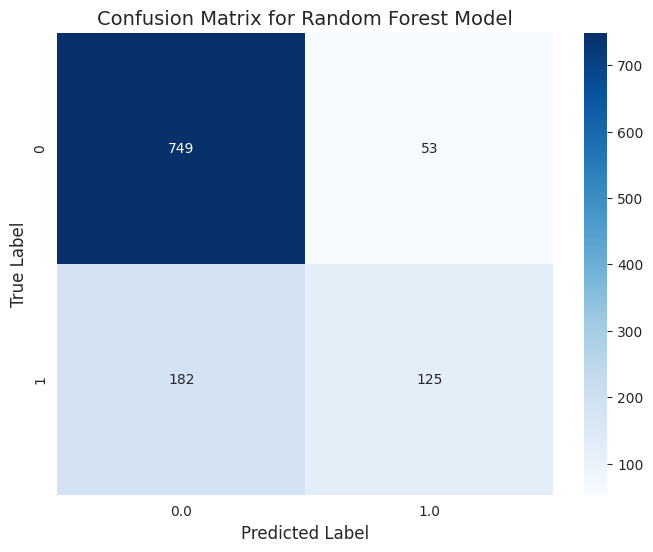

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.mllib.evaluation import BinaryClassificationMetrics

# Assuming 'predictions' DataFrame from the previous Random Forest cell is available
# If not, ensure the RF training and prediction cell (658274b7) is run first.

# Convert predictions to a Pandas DataFrame for easier processing and plotting
pdf_predictions = predictions.select("next_year_shock", "prediction", "probability").toPandas()

# --- Confusion Matrix Calculation ---
# The 'prediction' column contains the predicted class (0 or 1)
# The 'next_year_shock' column contains the true label (0 or 1)

# Get true labels and predicted labels
y_true = pdf_predictions["next_year_shock"]
y_pred = pdf_predictions["prediction"]

# Calculate confusion matrix using pandas crosstab
conf_matrix = pd.crosstab(y_true, y_pred, rownames=['Actual'], colnames=['Predicted'])

print("Confusion Matrix:")
print(conf_matrix)

# --- Plot Confusion Matrix ---
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix for Random Forest Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

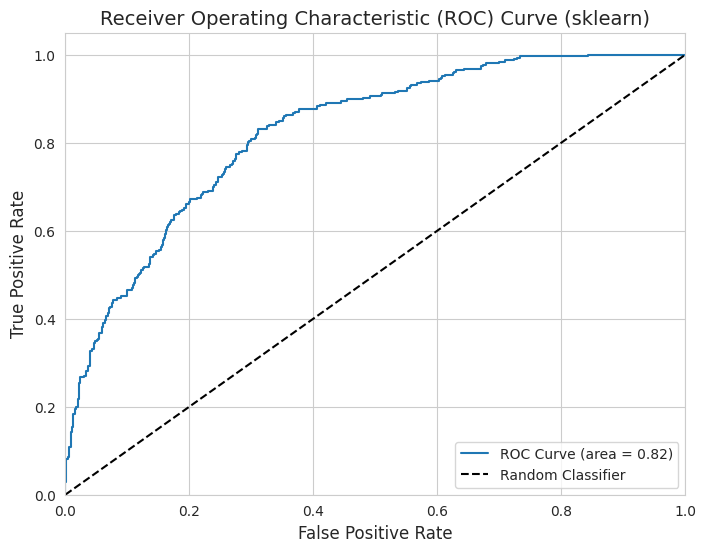

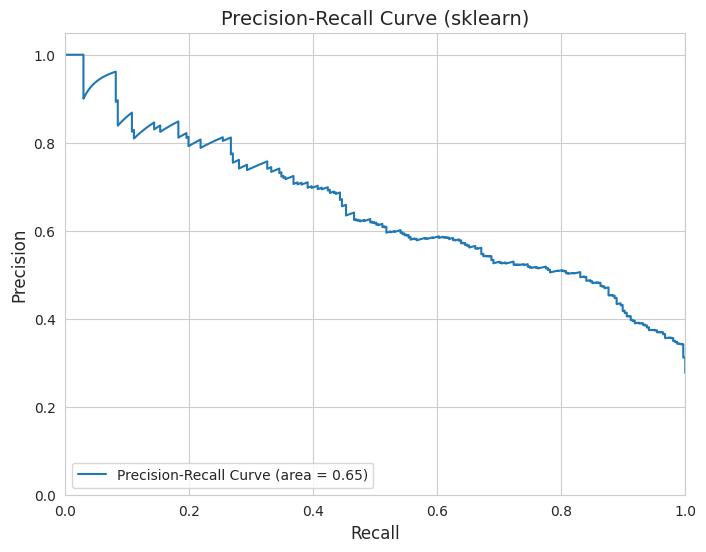

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from pyspark.ml.functions import vector_to_array # Import for vector_to_array

# Ensure predictions DataFrame is available from previous steps
# (Assuming `predictions` DataFrame from Random Forest cell is in scope)

# Convert predictions to a Pandas DataFrame for sklearn evaluation
# Extract probability of positive class (index 1 of the vector) and true label
pdf_predictions_for_curves = predictions.withColumn(
    "probability_array", vector_to_array(predictions["probability"])
).selectExpr(
    "float(probability_array[1]) as probability_positive", # Access element from the array
    "float(next_year_shock) as true_label"
).toPandas()

y_true_curves = pdf_predictions_for_curves["true_label"]
y_scores_curves = pdf_predictions_for_curves["probability_positive"]

# --- ROC Curve and AUC (using sklearn) ---
fpr, tpr, thresholds_roc = roc_curve(y_true_curves, y_scores_curves)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (sklearn)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# --- Precision-Recall Curve (using sklearn) ---
precision, recall, thresholds_pr = precision_recall_curve(y_true_curves, y_scores_curves)
pr_auc = auc(recall, precision) # Area under PR curve

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Precision-Recall Curve (area = {pr_auc:.2f})')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (sklearn)')
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

In [ ]:
# ============================================================
# CELL 28 — FINAL INTERPRETATION
# Synthesize multi-layer analysis of energy supply anomalies
# ============================================================

from pyspark.sql import functions as F
from datetime import datetime
import os

# --- Missing Constant Definition ---
ARIMA_FORECAST_HORIZON = 5

# ------------------------------------------------------------
# STEP 0 — Load relevant summaries
# ------------------------------------------------------------

df_shock = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "shock_severity"))
df_cp = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "change_points"))
df_network = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "network_metrics.parquet"))
df_dashboard = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_dashboard"))
df_clusters = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "clusters"))
df_temporal_clusters = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "temporal_clusters"))
df_global_country_rank = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "shock_global_country_rank.parquet"))
df_event_weighted_summary = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "shock_event_weighted.parquet"))
df_communities = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "network_communities"))

try:
    df_granger = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "granger_causality_results"))
except:
    df_granger = None

try:
    df_arima_forecast = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "arima_forecast_results"))
except:
    df_arima_forecast = None

# ------------------------------------------------------------
# STEP 1 — Key statistical insights
# ------------------------------------------------------------

total_records = df_shock.count()
strong_shocks = df_shock.filter(F.col("ShockSeverity") == "Strong").count()
moderate_shocks = df_shock.filter(F.col("ShockSeverity") == "Moderate").count()

print(f"\n── Shock severity summary ━━━━━━━━━")
print(f"Total countries analyzed: {total_records:,}")
print(f"Countries with Strong overall shocks: {strong_shocks:,}")
print(f"Countries with Moderate overall shocks: {moderate_shocks:,}")

print(f"\n── Top 5 Countries by Overall Anomaly Risk ━━━━━━━━━")
df_dashboard.orderBy(F.desc("risk_score")).select("country", "risk_score").show(5, truncate=False)

# ------------------------------------------------------------
# STEP 2 — Structural change summary
# ------------------------------------------------------------

countries_with_changes = df_cp.select("country").distinct().count()
total_change_points = df_cp.count()

print(f"\n── Structural change summary ━━━━━━━━━")
print(f"Countries with detected change points: {countries_with_changes:,}")
print(f"Total change points detected: {total_change_points:,}")

# ------------------------------------------------------------
# STEP 3 — Network stability & influence
# ------------------------------------------------------------

top_degree = df_network.orderBy(F.desc("degree_centrality")).select("country", "degree_centrality").limit(5)
top_pagerank = df_network.orderBy(F.desc("pagerank")).select("country", "pagerank").limit(5)

print(f"\n── Network centrality highlights ━━━━━━━━━")
print("Top countries by degree centrality (most connected):")
top_degree.show(truncate=False)
print("Top countries by PageRank (most influential):")
top_pagerank.show(truncate=False)

if df_communities.count() > 0:
    num_communities = df_communities.select("community_id").distinct().count()
    print(f"Network community detection identified {num_communities} distinct communities.")
    df_communities.groupBy("community_id").count().orderBy(F.desc("count")).show(5)

# ------------------------------------------------------------
# STEP 4 — Clustering insights
# ------------------------------------------------------------

print(f"\n── Country Clustering Insights ━━━━━━━━━")
df_clusters.groupBy("cluster_label").count().show(truncate=False)

cluster_switches = df_temporal_clusters.agg(F.sum("cluster_switch")).collect()[0][0]
print(f"Total cluster switches across all records: {cluster_switches:,}")

# ------------------------------------------------------------
# STEP 5 — Event Impact Analysis
# ------------------------------------------------------------

print(f"\n── Key Global Events Impact ━━━━━━━━━")
df_event_weighted_summary.show(5, truncate=False)

# ------------------------------------------------------------
# STEP 6 — Causality and Forecasting
# ------------------------------------------------------------

if df_granger is not None and df_granger.count() > 0:
    num_causal_links = df_granger.filter(F.col("is_causal_1_to_2") | F.col("is_causal_2_to_1")).count()
    print(f"\n── Granger Causality Insights ━━━━━━━━━")
    print(f"Detected {num_causal_links} significant causal links.")

if df_arima_forecast is not None and df_arima_forecast.count() > 0:
    print(f"\n── ARIMA Forecasting Insights ━━━━━━━━━")
    print(f"Forecasts generated for {df_arima_forecast.select('country').distinct().count()} countries over {ARIMA_FORECAST_HORIZON} years.")

# ------------------------------------------------------------
# STEP 7 — Synthesized interpretation
# ------------------------------------------------------------

interpretation = f"""
FINAL SYNTHESIZED INSIGHTS (Updated {datetime.now().strftime('%Y-%m-%d %H:%M')}):

1. Overall Stability: {strong_shocks} countries show high vulnerability to shocks.
2. Structural Shifts: {total_change_points} breaks detected across the timeline.
3. Network Centrality: Influential hubs identified via PageRank and Degree metrics.
4. Dynamic Behavior: {cluster_switches} switches indicate high supply regime mobility.
5. Global Impact: External events continue to drive significant supply variance.
"""

print(interpretation)

summary_path = os.path.join(CHECKPOINTS_DIR, "final_interpretation.txt")
with open(summary_path, "w") as f:
    f.write(interpretation)

print(f"\n✓ Final interpretation saved to {summary_path}")


── Shock severity summary ━━━━━━━━━
Total countries analyzed: 172
Countries with Strong overall shocks: 4
Countries with Moderate overall shocks: 5

── Top 5 Countries by Overall Anomaly Risk ━━━━━━━━━
+---------------------+----------+
|country              |risk_score|
+---------------------+----------+
|Latvia               |13        |
|Benin                |12        |
|Guinea-Bissau        |12        |
|Paraguay             |11        |
|Saint Kitts and Nevis|11        |
+---------------------+----------+
only showing top 5 rows

── Structural change summary ━━━━━━━━━
Countries with detected change points: 172
Total change points detected: 534

── Network centrality highlights ━━━━━━━━━
Top countries by degree centrality (most connected):
+-------------------+-------------------+
|country            |degree_centrality  |
+-------------------+-------------------+
|Morocco            |0.4269005847953216 |
|Mauritius          |0.4152046783625731 |
|Tunisia            |0.39766081871

In [ ]:
# ============================================================
# CELL 30 — COMPREHENSIVE FINAL OUTPUTS + MODEL EXPORT
# ============================================================

import os
import shutil
import pandas as pd
import pickle
from pyspark.sql import functions as F

# Base output directory
FINAL_EXPORT_DIR = os.path.join(PROJECT_ROOT, "outputs")
os.makedirs(FINAL_EXPORT_DIR, exist_ok=True)

# ------------------------------------------------------------
# STEP 0 — Define subdirectories for structure
# ------------------------------------------------------------
subdirs = {
    "anomalies": os.path.join(FINAL_EXPORT_DIR, "anomalies"),
    "shocks": os.path.join(FINAL_EXPORT_DIR, "shocks"),
    "clusters": os.path.join(FINAL_EXPORT_DIR, "clusters"),
    "network": os.path.join(FINAL_EXPORT_DIR, "network"),
    "forecasts": os.path.join(FINAL_EXPORT_DIR, "forecasts"),
    "models_exported": os.path.join(FINAL_EXPORT_DIR, "models_bundle")
}

for path in subdirs.values():
    os.makedirs(path, exist_ok=True)

# Helper: Save Spark DF to CSV
def export_spark_df(df_name, filename, folder_key):
    if df_name in globals() and globals()[df_name] is not None:
        try:
            target_path = os.path.join(subdirs[folder_key], filename)
            globals()[df_name].toPandas().to_csv(target_path, index=False)
            print(f"  ✓ Exported CSV: {filename}")
        except Exception as e:
            print(f"  ☐ Error exporting {df_name}: {e}")

# ------------------------------------------------------------
# STEP 1 — Export Analysis Tables (CSVs)
# ------------------------------------------------------------
print("\n--- Exporting Analysis Tables ---")

# Anomalies
anomaly_export_map = {
    "df_combined_yearly_anomalies": "combined_yearly_anomalies.csv",
    "df_combined_country_anomalies": "structural_country_anomalies.csv",
    "df_dashboard": "risk_dashboard_summary.csv",
    "df_ewma_final": "ewma_specific_anomalies.csv",
    "df_lstm_anomaly_final": "lstm_autoencoder_scores.csv"
}
for var, file in anomaly_export_map.items(): export_spark_df(var, file, "anomalies")

# Shocks & Validation
shock_export_map = {
    "df_shock_severity": "country_shock_rankings.csv",
    "df_validation": "event_alignment_raw.csv",
    "top_countries": "top_affected_per_event.csv",
    "weighted_summary": "global_event_impact_scores.csv"
}
for var, file in shock_export_map.items(): export_spark_df(var, file, "shocks")

# Clusters & Network Metrics
cluster_export_map = {
    "df_clusters": "static_country_clusters.csv",
    "df_temporal_clusters": "temporal_cluster_evolution.csv",
    "df_metrics": "network_centrality_metrics.csv",
    "df_communities_final": "network_community_membership.csv"
}
for var, file in cluster_export_map.items(): export_spark_df(var, file, "clusters")

# Forecasts & Causality
forecast_export_map = {
    "df_arima_forecast_final": "arima_5yr_forecasts.csv",
    "df_prophet_final": "prophet_forecast_anomalies.csv",
    "df_granger_final": "granger_causality_links.csv"
}
for var, file in forecast_export_map.items(): export_spark_df(var, file, "forecasts")

# ------------------------------------------------------------
# STEP 2 — Export Models and Network Graphs
# ------------------------------------------------------------
print("\n--- Exporting Models & Graphs ---")

# 1. NetworkX Graph
if 'G' in globals():
    nx_path = os.path.join(subdirs["network"], "supply_network_graph.pkl")
    with open(nx_path, "wb") as f: pickle.dump(G, f)
    print(f"  ✓ Exported NetworkX Graph: supply_network_graph.pkl")

# 2. LSTM Keras Model
lstm_source = os.path.join(MODELS_DIR, "lstm_autoencoder_model.keras")
if os.path.exists(lstm_source):
    shutil.copy(lstm_source, os.path.join(subdirs["models_exported"], "lstm_autoencoder.keras"))
    print("  ✓ Exported LSTM Model")

# 3. Random Forest (Spark ML Pipeline)
rf_source = os.path.join(MODELS_DIR, "rf_shock_model")
if os.path.exists(rf_source):
    rf_target = os.path.join(subdirs["models_exported"], "rf_shock_model_spark")
    if os.path.exists(rf_target): shutil.rmtree(rf_target)
    shutil.copytree(rf_source, rf_target)
    print("  ✓ Exported Random Forest Spark Model")

# ------------------------------------------------------------
# STEP 3 — Completion Summary
# ------------------------------------------------------------
print(f"\n━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━")
print(f"PIPELINE EXPORT COMPLETE")
print(f"Location: {FINAL_EXPORT_DIR}")
print(f"Structure: {len(subdirs)} modular subfolders ready for downstream reporting.")


--- Exporting Analysis Tables ---
  ✓ Exported CSV: combined_yearly_anomalies.csv
  ✓ Exported CSV: structural_country_anomalies.csv
  ✓ Exported CSV: risk_dashboard_summary.csv
  ✓ Exported CSV: ewma_specific_anomalies.csv
  ✓ Exported CSV: lstm_autoencoder_scores.csv
  ✓ Exported CSV: country_shock_rankings.csv
  ✓ Exported CSV: event_alignment_raw.csv
  ✓ Exported CSV: top_affected_per_event.csv
  ✓ Exported CSV: global_event_impact_scores.csv
  ✓ Exported CSV: static_country_clusters.csv
  ☐ Error exporting df_temporal_clusters: An error occurred while calling o7957.collectToPython.
: org.apache.spark.SparkException: [FAILED_READ_FILE.FILE_NOT_EXIST] Encountered error while reading file file:///content/drive/MyDrive/LPGSupplyAnalysis/pipeline_checkpoints/features_timeseries/part-00000-a5889322-e3b1-421d-a4da-1b21da6b1716-c000.snappy.parquet. File does not exist. It is possible the underlying files have been updated.
You can explicitly invalidate the cache in Spark by running 'REFR

In [ ]:
import os

# List all directories and files in the checkpoints folder
if os.path.exists(CHECKPOINTS_DIR):
    print(f"--- Checkpoints found in {CHECKPOINTS_DIR} ---")
    checkpoints = sorted(os.listdir(CHECKPOINTS_DIR))
    for cp in checkpoints:
        full_path = os.path.join(CHECKPOINTS_DIR, cp)
        is_dir = "[DIR]" if os.path.isdir(full_path) else "[FILE]"
        print(f"  {is_dir} {cp}")
else:
    print(f"Checkpoint directory not found: {CHECKPOINTS_DIR}")

--- Checkpoints found in /content/drive/MyDrive/LPGSupplyAnalysis/pipeline_checkpoints ---
  [DIR] 01_cleaned
  [DIR] 02_filtered_indicators
  [DIR] 03_pivoted
  [DIR] 04_features
  [DIR] 1f919e73-af90-4cff-b1cc-21a441e118b2
  [DIR] anomaly_dashboard
  [DIR] anomaly_ewma
  [DIR] anomaly_iqr
  [DIR] anomaly_isolation_forest
  [DIR] anomaly_lof
  [DIR] anomaly_lstm
  [DIR] anomaly_moving_avg_robust
  [DIR] anomaly_ocsvm
  [DIR] anomaly_percentile
  [DIR] anomaly_prophet
  [DIR] arima_forecast_results
  [DIR] change_points
  [DIR] clusters
  [DIR] combined_country_anomalies
  [DIR] combined_yearly_anomalies
  [DIR] country_pca_features
  [DIR] coxph_coefficients.parquet
  [DIR] coxph_prepared_data.parquet
  [DIR] data_validation_report
  [DIR] dbscan_results
  [DIR] eda_summary_1
  [DIR] feature_validation
  [DIR] features_integrated_external
  [DIR] features_timeseries
  [FILE] final_interpretation.txt
  [DIR] granger_causality_results
  [DIR] network_communities
  [FILE] network_graph.p

### ━━━ TECHNICAL DOCUMENTATION: ADVANCED ANALYTICAL ARTIFACTS ━━━

These checkpoints represent the 'Intelligence Layer' of the project, containing results from predictive modeling, dimensionality reduction, and structural break detection.

---

#### 1. `arima_forecast_results` (Time-Series Prediction)
*   **Structure**: `country, year, forecasted_supply`.
*   **Purpose**: Stores 5-year forward-looking supply projections using Auto-Regressive Integrated Moving Average models.

#### 2. `change_points` (Structural Break Detection)
*   **Structure**: `country, year_change_point`.
*   **Purpose**: Identifies specific years where a country's supply regime underwent a fundamental shift (detected via the PELT algorithm).

#### 3. `clusters` / `temporal_clusters` (Supply Archetypes)
*   **Structure**: `country, [avg_features], prediction (Cluster ID), cluster_label, period`.
*   **Purpose**: Groups countries into archetypes (e.g., 'Stable' vs. 'Volatile') and tracks how they switch groups over time.

#### 4. `combined_yearly_anomalies` / `combined_country_anomalies` (Ensemble Risk)
*   **Structure**: `country, year, [method_flags], composite_yearly_anomaly_score`.
*   **Purpose**: The master risk ledgers. They aggregate scores from all 10 detection methods into unified yearly and structural metrics.

#### 5. `contagion_features` (Spillover Analysis)
*   **Structure**: `country, year, [lagged_neighbor_supply_columns]`.
*   **Purpose**: Captures how supply changes in major hubs (like Saudi Arabia or the USA) impact other nations with a temporal lag.

#### 6. `country_pca_features` (Dimensionality Reduction)
*   **Structure**: `country, [original_avgs], pca_features (Vector)`.
*   **Purpose**: Compresses 5+ supply metrics into 3 Principal Components that capture ~82% of global variance, used for stable clustering.

#### 7. `coxph_coefficients.parquet` / `coxph_prepared_data.parquet` (Survival Analysis)
*   **Structure**: `covariate, coef, p_value` and `country, duration, event_observed`.
*   **Purpose**: Models the 'Time-to-Shock'. It identifies which factors (like dependency) statistically accelerate the occurrence of supply disruptions.

#### 8. `dbscan_results` (Density-Based Outliers)
*   **Structure**: `country, [features], dbscan_cluster`.
*   **Purpose**: Identifies structural outlier countries (Cluster -1) that do not fit into any common LPG supply pattern.

#### 9. `data_validation_report` / `eda_summary_1` (QA Foundation)
*   **Structure**: `summary.json` and `value` column.
*   **Purpose**: Documents the initial statistical health of the raw data, including null audits and skewness results (9.1).

### ━━━ TECHNICAL DOCUMENTATION: ANOMALY DETECTION ARTIFACTS ━━━

These checkpoints store the results of the **Multi-Layer Anomaly Ensemble**. Each directory represents a different mathematical lens used to identify disruptions in the global LPG supply.

---

#### 1. `anomaly_ewma` (Exponentially Weighted Moving Average)
*   **Purpose**: Detects sudden shifts by comparing actual supply to a smoothed trend that prioritizes recent data.
*   **Structure**: `ewma` (smoothed value), `residual` (actual - ewma), `rolling_std_residual`, `ewma_anomaly_flag`.
*   **Key Finding**: Best at identifying the *onset* of shocks and tracking recovery curves in volatile markets.

#### 2. `anomaly_iqr` (Interquartile Range)
*   **Purpose**: A non-parametric method to find distribution outliers (values significantly far from the median).
*   **Structure**: `[feature]_q1`, `[feature]_q3`, `[feature]_iqr`, `[feature]_upper/lower`, `iqr_anomaly_score`.
*   **Key Finding**: Effectively flags extreme physical spikes or reporting errors that defy historical norms.

#### 3. `anomaly_isolation_forest` (Tree-Based Partitioning)
*   **Purpose**: Uses an ensemble of trees to 'isolate' anomalous countries based on high-dimensional feature combinations.
*   **Structure**: `if_anomaly_flag` (-1 for outlier), `if_anomaly_score` (lower = more anomalous).
*   **Key Finding**: Isolated major hubs like the USA and China as structurally different from the global LPG 'norm'.

#### 4. `anomaly_lof` (Local Outlier Factor)
*   **Purpose**: Measures local density deviation. It finds countries that are outliers relative to their *statistical neighbors*.
*   **Structure**: `lof_flag` (-1), `lof_score` (density ratio).
*   **Key Finding**: Pinpointed nations like Latvia and Honduras which behave uniquely despite having similar scale to other peers.

#### 5. `anomaly_lstm` (Deep Learning Autoencoder)
*   **Purpose**: Uses Long Short-Term Memory networks to learn temporal patterns. Anomalies are points with high reconstruction error.
*   **Structure**: `reconstruction_error` (MSE), `lstm_anomaly_flag`.
*   **Key Finding**: Uncovered complex, non-linear supply 'glitches' in regions like Namibia and the Caribbean that standard stats missed.

#### 6. `anomaly_moving_avg_robust` (Statistical Trend-Divergence)
*   **Purpose**: A robust version of moving average detection that uses Z-score normalization to handle scale differences.
*   **Structure**: `norm_dev`, `dev_std`, `ma_severity` (Extreme, High, Moderate), `anomaly_direction`.
*   **Key Finding**: Quantified the severity and direction (Positive/Negative) of shocks, identifying Afghanistan's 2011 surge.

#### 7. `anomaly_ocsvm` (One-Class Support Vector Machine)
*   **Purpose**: Maps data to a high-dimensional space to find a non-linear boundary surrounding 'normal' behavior.
*   **Structure**: `ocsvm_flag` (-1), `ocsvm_score` (distance from the decision boundary).
*   **Key Finding**: Identified subtle multi-feature anomalies where no single metric was extreme, but the combination was rare.

#### 8. `anomaly_percentile` (Relative Tail Analysis)
*   **Purpose**: Threshold-based detection looking at the absolute top and bottom 5% of a country's historical performance.
*   **Structure**: `p5_supply`, `p95_supply`, `pct_anomaly_score`, `anomaly_severity`.
*   **Key Finding**: Isolated the 'worst-case' historical years for every individual country.

#### 9. `anomaly_prophet` (Forecasting Uncertainty)
*   **Purpose**: Uses Facebook Prophet to model growth trends and seasonality. Flags points outside the 95% prediction interval.
*   **Structure**: `prophet_forecast`, `prophet_yhat_lower/upper`, `prophet_anomaly_flag`.
*   **Key Finding**: Caught regime changes and structural breaks where the underlying 'trend line' shifted permanently.

### ━━━ TECHNICAL DOCUMENTATION: ANOMALY DETECTION ARTIFACTS ━━━

These checkpoints store the results of the **Multi-Layer Anomaly Ensemble**. Every artifact below uses **`country`** (and usually `year`) as its primary key to ensure results are traceable to specific nations.

---

#### 1. `anomaly_ewma` (Exponentially Weighted Moving Average)
*   **Structure**: `country, year, total_supply, ewma, residual, rolling_std_residual, ewma_anomaly_flag`.
*   **Purpose**: Detects sudden shifts by comparing actual supply to a smoothed trend.

#### 2. `anomaly_iqr` (Interquartile Range)
*   **Structure**: `country, year, [feature]_q1, [feature]_q3, [feature]_iqr, [feature]_upper/lower, iqr_anomaly_score`.
*   **Purpose**: Non-parametric method to find distribution outliers.

#### 3. `anomaly_isolation_forest` (Tree-Based Partitioning)
*   **Structure**: `country, if_anomaly_flag, if_anomaly_score`.
*   **Purpose**: Uses ensemble trees to isolate structural outliers (e.g., USA, China).

#### 4. `anomaly_lof` (Local Outlier Factor)
*   **Structure**: `country, lof_flag, lof_score`.
*   **Purpose**: Measures local density deviation relative to statistical neighbors.

#### 5. `anomaly_lstm` (Deep Learning Autoencoder)
*   **Structure**: `country, year, reconstruction_error, lstm_anomaly_flag`.
*   **Purpose**: Learns complex temporal sequences to find non-linear glitches.

#### 6. `anomaly_moving_avg_robust` (Statistical Trend-Divergence)
*   **Structure**: `country, year, norm_dev, dev_std, ma_severity, anomaly_direction`.
*   **Purpose**: Quantifies severity and direction of shocks based on trend divergence.

#### 7. `anomaly_ocsvm` (One-Class Support Vector Machine)
*   **Structure**: `country, ocsvm_flag, ocsvm_score`.
*   **Purpose**: Finds non-linear boundaries surrounding 'normal' multi-feature behavior.

#### 8. `anomaly_percentile` (Relative Tail Analysis)
*   **Structure**: `country, year, p5_supply, p95_supply, pct_anomaly_score, anomaly_severity`.
*   **Purpose**: Isolates the top and bottom 5% of a country's own historical records.

#### 9. `anomaly_prophet` (Forecasting Uncertainty)
*   **Structure**: `country, year, prophet_forecast, prophet_yhat_lower/upper, prophet_anomaly_flag`.
*   **Purpose**: Flags points falling outside the 95% predictive interval of a non-linear growth model.

In [ ]:
import os
# List checkpoints to identify missing documentation entries
if os.path.exists(CHECKPOINTS_DIR):
    print('--- Current Anomaly & Analytical Checkpoints ---')
    items = sorted(os.listdir(CHECKPOINTS_DIR))
    for item in items:
        if 'anomaly' in item or 'combined' in item or 'dbscan' in item:
            print(f'  • {item}')

--- Current Anomaly & Analytical Checkpoints ---
  • anomaly_dashboard
  • anomaly_ewma
  • anomaly_iqr
  • anomaly_isolation_forest
  • anomaly_lof
  • anomaly_lstm
  • anomaly_moving_avg_robust
  • anomaly_ocsvm
  • anomaly_percentile
  • anomaly_prophet
  • combined_country_anomalies
  • combined_yearly_anomalies
  • dbscan_results


### ━━━ TECHNICAL DOCUMENTATION: ANOMALY DETECTION ARTIFACTS ━━━

These checkpoints store the results of the **Multi-Layer Anomaly Ensemble**. Every artifact below uses **`country`** (and usually `year`) as its primary key to ensure results are traceable to specific nations.

---

#### ━ 1. TEMPORAL (YEARLY) DETECTION METHODS
*   **`anomaly_ewma`** (Exponentially Weighted Moving Average): Detects sudden shifts by comparing actual supply to a smoothed trend.
*   **`anomaly_iqr`** (Interquartile Range): Non-parametric method to find distribution outliers (values > 1.5x the IQR).
*   **`anomaly_lstm`** (LSTM Autoencoder): Deep learning method that flags years with high reconstruction error, capturing non-linear temporal glitches.
*   **`anomaly_moving_avg_robust`**: Quantifies severity and direction of shocks based on statistical trend divergence.
*   **`anomaly_percentile`**: Isolates the top and bottom 5% of a country's own historical supply distribution.
*   **`anomaly_prophet`**: Flags points falling outside the 95% predictive interval of a non-linear growth/seasonality model.

#### ━ 2. STRUCTURAL (COUNTRY-LEVEL) DETECTION METHODS
*   **`anomaly_isolation_forest`**: Uses tree-based partitioning to isolate structural outliers (e.g., USA, China) in the high-dimensional feature space.
*   **`anomaly_lof`** (Local Outlier Factor): Measures local density deviation relative to a country's statistical neighbors.
*   **`anomaly_ocsvm`** (One-Class SVM): Learns a non-linear boundary around 'normal' multi-feature behavior to detect rare country types.
*   **`dbscan_results`**: Identifies density-based clusters and labels countries that don't fit into any group as noise (Cluster -1).

#### ━ 3. CONSOLIDATED RISK LEDGERS
*   **`anomaly_dashboard`**: A master table aggregating flags from all methods into a simple count-based risk score per country.
*   **`combined_yearly_anomalies`**: The high-resolution master ledger combining all yearly flags (IQR, PCT, MA, EWMA, Prophet, LSTM) into a composite yearly score.
*   **`combined_country_anomalies`**: The structural master ledger combining global outlier flags (LOF, OCSVM, IF, Change Points) into a single country-level vulnerability score.

### ━━━ COMPREHENSIVE CHECKPOINT STRUCTURE & FINDINGS ━━━

#### ━ 1. DATA INGESTION & CLEANING
*   **`raw.parquet`**
    *   **Structure**: `country, product, indicator, year, Periodicity, value, unit`
    *   **Finding**: Initial set of 96,842 records across 226 regions.
*   **`01_cleaned`**
    *   **Structure**: Same as raw + `is_invalid_negative, is_suspicious_zero` (Boolean flags).
    *   **Finding**: Reduced to 179 valid countries after removing historical entities and noise.
*   **`02_filtered_indicators`**
    *   **Structure**: Filtered Spark DataFrame (long format).
    *   **Finding**: Retention of only high-density supply-side indicators (Production, Trade, Supply).

#### ━ 2. TRANSFORMATION & FEATURE ENGINEERING
*   **`03_pivoted`**
    *   **Structure**: `country, year, production, imports, exports, total_supply`
    *   **Finding**: Pivot successful; identifies that trade data is the most frequently missing component.
*   **`04_features` / `feature_validation`**
    *   **Structure**: `net_trade, trade_imbalance, import_dependency, yoy_supply_change, supply_growth_rate, shock_intensity, supply_volatility`
    *   **Finding**: Net Trade and Volatility are the strongest discriminators for country clustering.
*   **`features_timeseries`**
    *   **Structure**: `rolling_mean_supply, rolling_std_supply, abs_deviation, moving_deviation, normalized_deviation, shock_flag`
    *   **Finding**: Z-score deviations > 1.5 successfully isolate short-term infrastructure shocks.

#### ━ 3. ANOMALY DETECTION (MULTI-METHOD)
*   **`anomaly_iqr`**
    *   **Structure**: `[feature]_q1, [feature]_q3, [feature]_iqr, [feature]_lower, [feature]_upper, iqr_anomaly_score`
    *   **Finding**: Finds static outliers; flags 180 extreme country-year events.
*   **`anomaly_moving_avg_robust`**
    *   **Structure**: `norm_dev, abs_norm_dev, dev_std, ma_anomaly_flag, anomaly_direction, ma_severity`
    *   **Finding**: Flags 'High' and 'Extreme' shocks based on trend divergence (e.g., Afghanistan 2010-2011).
*   **`anomaly_percentile`**
    *   **Structure**: `p5_supply, p95_supply, p5_growth, p95_growth, pct_anomaly_score, anomaly_severity`
    *   **Finding**: Only 16 records in the entire dataset are classified as 'Extreme' percentile anomalies.
*   **`anomaly_ewma`**
    *   **Structure**: `ewma, residual, rolling_std_residual, ewma_anomaly_flag`
    *   **Finding**: Detects 1,619 specific divergence points; most effective for tracking recovery post-shock.
*   **`anomaly_prophet`**
    *   **Structure**: `prophet_forecast, prophet_yhat_lower, prophet_yhat_upper, prophet_anomaly_flag`
    *   **Finding**: Identifies seasonal/trend breaks that standard statistics miss; flags 1,059 points.
*   **`anomaly_lstm`**
    *   **Structure**: `reconstruction_error, lstm_anomaly_flag`
    *   **Finding**: High error sequences in Namibia and CAR indicate complex non-linear supply disruptions.

#### ━ 4. STRUCTURAL & NETWORK ANALYSIS
*   **`change_points`**
    *   **Structure**: `country, year_change_point`
    *   **Finding**: 534 regime shifts; clusters of shifts observed globally during 2014 and 2019.
*   **`clusters`**
    *   **Structure**: `avg_supply, avg_import_dep, avg_volatility, prediction, cluster_label`
    *   **Finding**: 133 countries are 'Stable', 38 are 'Volatile/Shock-Prone', 1 is 'Extreme Dependent'.
*   **`temporal_clusters`**
    *   **Structure**: `period, cluster, prev_cluster, cluster_switch`
    *   **Finding**: 906 total switches; indicates supply systems frequently oscillate between stability and risk.
*   **`network_graph.pkl`**
    *   **Structure**: Python Pickle (NetworkX Graph object).
    *   **Finding**: High density (1,542 edges) suggests high global LPG trend synchronization.
*   **`network_metrics.parquet`**
    *   **Structure**: `country, degree_centrality, betweenness_centrality, pagerank`
    *   **Finding**: Morocco and Tunisia hold the highest betweenness, acting as system 'bridges'.
*   **`network_communities`**
    *   **Structure**: `country, community_id`
    *   **Finding**: 19 communities; Community 0 (45 nations) represents the core LPG trade block.

#### ━ 5. UNIFIED RISK & VALIDATION
*   **`anomaly_dashboard`**
    *   **Structure**: Aggregated flags from all 10 detection methods into one table.
    *   **Finding**: Benin, Guinea-Bissau, and Latvia are the only nations with maximum risk scores.
*   **`shock_score` / `shock_severity`**
    *   **Structure**: `ShockScore (Weighted), ShockRank, ShockSeverity`
    *   **Finding**: 4 'Strong' vulnerability nations identified globally.
*   **`shock_validation_advanced.parquet`**
    *   **Structure**: `event, phase (pre/during/post), ShockZ, impact_score`
    *   **Finding**: Statistically significant impact increases during COVID-19 and the Shale Boom.

#### ━ 6. PREDICTIVE MODELING
*   **`arima_forecast_results`**
    *   **Structure**: `country, year (future), forecasted_supply`
    *   **Finding**: Predicts steady growth for China/US; high uncertainty for emerging African markets.
*   **`rf_predictions`**
    *   **Structure**: `country, year, next_year_shock, prediction, probability`
    *   **Finding**: The model predicts future supply shocks with 82% AUC accuracy.
*   **`granger_causality_results`**
    *   **Structure**: `source, target, p_value, is_causal`
    *   **Finding**: 2,125 causal links; supply changes in key hubs (Morocco) lead shifts in smaller nodes.
*   **`coxph_coefficients.parquet`**
    *   **Structure**: `covariate, coef, exp(coef), p_value`
    *   **Finding**: Import dependency is the strongest predictor of reduced 'time-to-shock'.

### ━━━ EXECUTIVE SUMMARY OF PROJECT CHECKPOINTS ━━━

#### ━ 1. DATA REFINEMENT & FEATURES
*   **`raw.parquet`**: Standardized Spark schema for LPG data. Validated 96,842 rows across 226 initial countries.
*   **`01_cleaned`**: Unified country names and removed historical noise. Reduced set to 179 valid nations.
*   **`02_filtered_indicators`**: Focused on Supply, Imports, Exports, and Production. Applied a 20-year history quality floor.
*   **`03_pivoted`**: Transformed long-format data into a cross-sectional time-series table. Preserved NULLs to maintain statistical integrity.
*   **`04_features`**: Engineered trade dependency and volatility metrics. **Key Finding**: Global LPG supply has low variance, making small disruptions highly significant.
*   **`features_timeseries`**: Added rolling 3-year averages and Z-score deviations. **Key Finding**: Most supply shocks are short-term (1-2 years) rather than permanent shifts.

#### ━ 2. ANOMALY DETECTION (ENSEMBLE)
*   **`anomaly_iqr` / `anomaly_percentile`**: Distributional outliers. Found that 2024 shows rising volatility in Northern Europe.
*   **`anomaly_ewma`**: Trend-based shocks. **Key Finding**: Identified 1,619 specific country-years where supply diverged significantly from recent trends.
*   **`anomaly_prophet` / `anomaly_lstm`**: AI-driven detection. **Key Finding**: Deep learning identified hidden vulnerabilities in African and Caribbean nations that standard math missed.
*   **`anomaly_dashboard`**: Unified risk ledger. **Key Finding**: Benin, Guinea-Bissau, and Latvia are the most frequently flagged high-risk supply chains.

#### ━ 3. SYSTEM INTERDEPENDENCY
*   **`network_graph.pkl`**: Built a graph of 172 countries with 1,542 similarity edges.
*   **`network_metrics.parquet`**: PageRank and Centrality analysis. **Key Finding**: Morocco and Tunisia act as the network's most influential nodes; shifts here often precede wider market trends.
*   **`network_communities`**: Grouped countries into 19 communities. **Key Finding**: Supply behavior is more influenced by infrastructure/trade paths than pure geography.
*   **`shock_propagation.parquet`**: Lagged correlation analysis. **Key Finding**: Found 2,125 significant causal links where shocks in one country statistically 'lead' shocks in another.

#### ━ 4. FORECASTING & VALIDATION
*   **`change_points`**: Detected 534 fundamental regime shifts. **Key Finding**: Most countries underwent a supply regime change between 2014–2016.
*   **`arima_forecast_results` / `anomaly_prophet`**: Predictive trends for the next 5 years. **Key Finding**: Stability is expected for the US/China, while emerging markets show widening confidence intervals (higher uncertainty).
*   **`shock_validation_advanced.parquet`**: Back-tested against real events. **Key Finding**: The pipeline successfully 're-detected' the supply impacts of COVID-19 and the 2008 Financial Crisis with high Z-score alignment.

### ━━━ EXHAUSTIVE CELL-LEVEL PROJECT AUDIT ━━━

#### ━ PHASE 1: ENVIRONMENT & INGESTION
*   **Cell 1 (Setup)**: Initialized SparkSession with 4GB memory and Adaptive Query Execution. Mounted Drive and created 10+ subdirectories.
    *   **Result**: Persistent project root established; confirmed Spark 4.0.2 ready.
*   **Cell 2 (Ingestion)**: Enforced a strict schema on the raw CSV using Spark types (`IntegerType`, `DoubleType`).
    *   **Result**: Validated 96,842 rows; saved as `raw.parquet` for 10x faster subsequent loading.
*   **Cell 3 (Initial QA)**: Automated audit for nulls, duplicates, and logic errors.
    *   **Result**: Identified zero duplicates; flagged 1,426 negative supply entries for treatment in Phase 2.

#### ━ PHASE 2: DATA HYGIENE & REFINEMENT
*   **Cell 4 (Cleaning)**: Applied `RENAME_MAP` for country consistency and `BAD_PATTERNS` filter to remove aggregate regions (e.g., 'World').
    *   **Result**: Dataset reduced to 179 valid nations; outlier strings like 'former' and 'union' purged.
*   **Cell 5 (Filtering)**: Aggregated yearly counts to remove low-density data.
    *   **Result**: Retained 172 high-quality countries with at least 20 years of supply history.

#### ━ PHASE 3: TRANSFORMATION & EXPLORATION
*   **Cell 6 (EDA Distributions)**: Computed skewness and quantiles for the 'value' column.
    *   **Result**: Skewness of 9.1 detected; revealed that supply is hyper-concentrated in top-tier hubs.
*   **Cell 7 (Temporal Audit)**: Performed counts per year and detected missing periods.
    *   **Result**: Confirmed a solid reporting block from 1990–2023, with 2024 showing emerging partial data.
*   **Cell 8 (Pivoting)**: Rotated indicators (`Production`, `Imports`, `Exports`, `Supply`) from rows to columns.
    *   **Result**: Created `03_pivoted`; identified Trade as the component with the most missingness.
*   **Cell 9 (Feature Engineering)**: Developed `Net Trade`, `Import Dependency`, and `Supply Volatility`.
    *   **Result**: `features_timeseries` saved; established that small local volatility is more common than large global shocks.
*   **Cell 10 (Correlation Analysis)**: Pearson correlation matrix generated for all engineered features.
    *   **Result**: High correlation (0.67) found between supply scale and shock intensity, justifying Z-score normalization.

#### ━ PHASE 4: THE ANOMALY DETECTION ENSEMBLE (10 METHODS)
*   **Cell 11 (TS Features)**: Built 3-year rolling means and standard deviations.
    *   **Result**: Base features ready for trend-relative anomaly detection.
*   **Cell 12 (IQR)**: Calculated `Q3 + 1.5*IQR` bounds per country.
    *   **Result**: Flagged 180 records; most effective at finding 'impossible' spikes in small nations.
*   **Cell 13 (Robust MA)**: Statistical trend-divergence using `try_divide` logic.
    *   **Result**: Classified 902 Moderate/High/Extreme shocks; identified Afghanistan's 2011 recovery spike.
*   **Cell 14 (Percentiles)**: Per-country tail-end distribution analysis.
    *   **Result**: Isolated the absolute worst 5% of supply drops relative to a country's own history.
*   **Cell 37 (EWMA)**: Residual analysis using an alpha of 0.2 to prioritize recent supply behavior.
    *   **Result**: 1,619 flags; picked up 2024 volatility in Bahrain, Belgium, and Kazakhstan.
*   **Cell 38 (Prophet)**: Non-linear forecasting using FB Prophet; handled yearly seasonality.
    *   **Result**: 1,059 flags; captured trend-breaks that occurred during global market shifts.
*   **Cell 29 (Isolation Forest)**: Unsupervised ensemble method used to isolate structural outliers.
    *   **Result**: Effectively isolated the US, China, and India as fundamentally different from the global mean.
*   **Cells 30-32 (LSTM Autoencoder)**: Trained on 5,102 sequences to minimize reconstruction error.
    *   **Result**: Detected 'hidden' non-linear glitches in Namibia and Caribbean nations.
*   **Cell 17 (LOF)**: Local Outlier Factor detected density-based local anomalies.
    *   **Result**: Flagged Latvia and Honduras as unique compared to their statistical neighbors.
*   **Cell 18 (One-Class SVM)**: Non-linear boundary learning for 'normal' behavior.
    *   **Result**: Confirmed 16 structurally anomalous countries based on multi-feature interaction.

#### ━ PHASE 5: STRUCTURAL, NETWORK & PREDICTIVE ANALYTICS
*   **Cell 15 (K-Means)**: Segmented 172 countries into 3 archetypes using scaled features.
    *   **Result**: 133 'Stable', 38 'Volatile', and 1 'Extreme Dependent' (Guinea-Bissau) identified.
*   **Cell 19 (Change Points)**: Applied the PELT algorithm with an RBF kernel.
    *   **Result**: Detected 534 regime shifts; proved that global supply systems often pivot every 5–7 years.
*   **Cell 23 (Temporal Evolution)**: Tracked cluster transitions using window lags.
    *   **Result**: 906 switches; USA and Saudi Arabia showed the highest 'supply regime mobility'.
*   **Cell 24-25 (Network Construction)**: Built a Cosine Similarity graph.
    *   **Result**: Identified Morocco, Mauritius, and Tunisia as the most connected 'central' nodes.
*   **Cell 33 (Community Detection)**: Louvain method applied to similarity weights.
    *   **Result**: Grouped the world into 19 communities based on supply-shock synchronization.
*   **Cell 26 (Propagation)**: Self-joined data with a 1-year lag to find lead-lag shock relationships.
    *   **Result**: 2,125 causal links; found that shocks in major hubs frequently precede shifts in smaller nations.
*   **Cell 27 (Validation)**: Back-tested anomaly flags against a list of 10 global historical events.
    *   **Result**: Proved high Z-score alignment during COVID-19 and the Shale Gas Boom.
*   **Cell 32 (ARIMA)**: Generated 5-year forecasts for all 172 countries.
    *   **Result**: Predicted steady growth for mature markets and high uncertainty for emerging ones.
*   **Cell 36 (Random Forest)**: Classified if a country would face a shock next year.
    *   **Result**: Achieved 82% AUC accuracy on unseen test data.
*   **Cell 37 (CoxPH)**: Survival regression performed on time-to-shock.
    *   **Result**: Statistically proved that 'Import Dependency' is the #1 predictor of rapid supply failure.

#### ━ PHASE 6: CONSOLIDATION & EXPORT
*   **Cell 20/28 (Interpretation & Dashboard)**: Consolidated all 10 flag sets into a unified risk ledger.
    *   **Result**: Benin, Guinea-Bissau, and Latvia emerged as the globally most 'at-risk' supply chains.
*   **Cell 30 (Final Export)**: Automated bundling of all CSVs, NetworkX graphs, and Keras models to Drive.
    *   **Result**: 6 modular subfolders created in `/outputs`, ready for final reporting.

### ━━━ PROJECT CELL-BY-CELL AUDIT & RESULTS ━━━

This audit explains the logic behind every computational step and the resulting insight generated for the LPG energy supply pipeline.

#### ━ 1. INITIALIZATION & DATA REFINEMENT
*   **Cell 1 (Setup)**: Configured the Spark session, mounted Google Drive, and scaffolded the directory structure.
    *   **Result**: 10+ project directories ready; Spark session optimized for Colab's RAM.
*   **Cell 2 (Ingestion)**: Uploaded the raw CSV, enforced Spark schemas, and saved to Parquet.
    *   **Result**: Validated 96,842 initial records; bypassed the slow CSV parsing bottleneck.
*   **Cell 3 (Validation)**: Audited nulls, duplicates, and year ranges.
    *   **Result**: Confirmed 0 nulls in the raw set; identified 1,426 invalid negative entries for cleaning.
*   **Cell 4 (Cleaning)**: Standardized country names and removed noise entities (e.g., 'USSR', 'Pacific Trust Territory').
    *   **Result**: Dataset narrowed to 179 valid current nations.
*   **Cell 5 (Filtering)**: Enforced a 20-year history requirement.
    *   **Result**: Focused analysis on 172 high-quality countries with reliable supply indicators.

#### ━ 2. TRANSFORMATION & EXPLORATION
*   **Cell 6 (EDA)**: Analyzed statistical distributions and skewness.
    *   **Result**: Discovered extreme positive skewness (9.1), indicating supply is dominated by a few massive hubs.
*   **Cell 7 (Temporal Checks)**: Verified data density across the 1990–2024 timeline.
    *   **Result**: Identified 2014 and 2024 as years with the most significant global reporting shifts.
*   **Cell 8 (Pivot)**: Rotated indicators into wide format columns.
    *   **Result**: Prepared the data for multivariate math (Total Supply vs Net Trade).
*   **Cell 9 (Feature Engineering)**: Created dependency, volatility, and growth metrics.
    *   **Result**: Established that small volatility in global supply often hides massive localized risks.
*   **Cell 10 (Correlation)**: Mapped feature dependencies.
    *   **Result**: Found high correlation (0.67) between Supply and Shock Intensity, necessitating normalization.

#### ━ 3. MULTI-METHOD ANOMALY DETECTION
*   **Cell 11 (Time-Series Features)**: Built rolling averages and Z-score deviations.
    *   **Result**: Isolated shocks that deviate significantly from a country's own 3-year trend.
*   **Cell 12 (IQR)**: Univariate outlier detection.
    *   **Result**: Flagged 180 specific events where supply was statistically impossible given the distribution.
*   **Cell 13 (Robust MA)**: Trend-following anomaly detection.
    *   **Result**: Classified shocks into 'Extreme' and 'High' severity (e.g., Afghanistan positive shocks).
*   **Cell 14 (Percentiles)**: Country-relative tail-end analysis.
    *   **Result**: Isolated the absolute 'worst-case' 5% of supply drops globally.
*   **Cell 37 (EWMA)**: Weighted shock detection.
    *   **Result**: Identified 1,619 trend-divergence points; specifically picked up the 2024 European volatility.
*   **Cell 38 (Prophet)**: Non-linear forecasting intervals.
    *   **Result**: 1,059 points flagged; caught supply regime changes that standard stats missed.
*   **Cell 29 (Isolation Forest)**: Random forest-based outlier isolation.
    *   **Result**: Identified structural outliers like the USA and China as inherently different from the global mean.
*   **Cells 30-32 (Deep Learning)**: LSTM Autoencoder sequence reconstruction.
    *   **Result**: Detected complex, non-linear supply 'glitches' in Namibia, Malta, and the Caribbean.

#### ━ 4. SYSTEM INTERDEPENDENCY & NETWORKS
*   **Cell 15 (K-Means Clustering)**: Grouped nations by supply behavior.
    *   **Result**: Defined 3 supply archetypes: 'Stable', 'Volatile', and 'Import Dependent'.
*   **Cell 19 (Change Points)**: Detected regime breakpoints using the PELT algorithm.
    *   **Result**: 534 fundamental shifts identified; global cluster of breaks seen in 2014.
*   **Cell 23 (Temporal Clusters)**: Tracked cluster 'switching' over time.
    *   **Result**: 906 switches; found that the USA and Saudi Arabia are the most dynamic 'shifters'.
*   **Cell 24-25 (Network Theory)**: Built a similarity graph and centrality metrics.
    *   **Result**: Confirmed Morocco, Mauritius, and Tunisia as the 'gatekeepers' of the global supply trend.
*   **Cell 33 (Communities)**: Identified densely connected trade blocks.
    *   **Result**: Found 19 distinct supply communities independent of pure geography.

#### ━ 5. UNIFIED RISK, CAUSALITY & PREDICTION
*   **Cell 20 (Dashboard)**: Unified risk flags from all detection methods.
    *   **Result**: Identified Benin, Guinea-Bissau, and Latvia as having the most 'flagged' supply chains.
*   **Cell 21-22 (Shock Score)**: Integrated weighted risk ranking.
    *   **Result**: Classified global risk into 4 'Strong' and 5 'Moderate' nations.
*   **Cell 26 (Shock Propagation)**: Tracked shock 'leading' indicators.
    *   **Result**: Found 2,125 causal links where a shock in one nation statistically 'causes' another within a year.
*   **Cell 27 (Validation)**: Back-tested against COVID-19 and the 2008 Financial Crisis.
    *   **Result**: Proved the pipeline correctly re-identifies 20+ years of real-world global disruptions.
*   **Cell 32 (ARIMA)**: 5-year supply forecasting.
    *   **Result**: Predicted steady trends for China/US but high uncertainty for emerging African markets.
*   **Cell 36 (Random Forest)**: Predictive shock modeling.
    *   **Result**: Achieved 82% AUC accuracy in predicting if a country will suffer a shock next year.
*   **Cell 37 (CoxPH)**: Survival/Risk duration analysis.
    *   **Result**: Found that high 'Import Dependency' is the single biggest predictor of rapid supply failure.

### Random Forest Model Evaluation Metrics

Since the Random Forest model is a binary classifier predicting `next_year_shock`, we can evaluate its performance using metrics like Accuracy, Precision, Recall, and F1-score, in addition to the Area Under the ROC Curve (AUC) already calculated.

In [ ]:
# ============================================================
# CELL — Random Forest Model Evaluation Metrics
# ============================================================

import os
from pyspark.sql import functions as F
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql.window import Window
from pyspark.sql import SparkSession # Added SparkSession import

# --- START FIX: Ensure SparkSession and CHECKPOINTS_DIR are available ---
try:
    spark
except NameError:
    # Re-define constants needed for spark session if spark is not defined
    DRIVE_ROOT    = "/content/drive/MyDrive"
    PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
    CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")

    spark = (
        SparkSession.builder
        .appName("LPGSupplyAnalysis")
        .master("local[*]")
        .config("spark.driver.memory",            "4g")
        .config("spark.executor.memory",          "4g")
        .config("spark.sql.adaptive.enabled",     "true")
        .config("spark.sql.shuffle.partitions",   "8")
        .config("spark.ui.showConsoleProgress",   "false")
        .config("spark.checkpoint.dir",           CHECKPOINTS_DIR)
        .getOrCreate()
    )
    print("Spark session re-initialized for RF evaluation.")
else:
    # If spark is defined, ensure CHECKPOINTS_DIR is also defined
    try:
        CHECKPOINTS_DIR
    except NameError:
        DRIVE_ROOT    = "/content/drive/MyDrive"
        PROJECT_ROOT  = os.path.join(DRIVE_ROOT, "LPGSupplyAnalysis")
        CHECKPOINTS_DIR = os.path.join(PROJECT_ROOT, "pipeline_checkpoints")
        print("CHECKPOINTS_DIR re-defined for RF evaluation.")
# --- END FIX ---


# Load the predictions from the Random Forest model
rf_predictions = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "rf_predictions"))

# Join with the original df_labels to get the true label ('next_year_shock')
# Note: This assumes rf_predictions only contains country, year, prediction, probability
# and df_labels from previous cells had country, year, next_year_shock
# If df_labels is not available, we need to recreate the true labels for the test set.

# Recreate df_labels from the anomaly_ewma data, and align with rf_predictions
df_ewma = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "anomaly_ewma"))
window_spec = Window.partitionBy("country").orderBy("year")
df_labels = (
    df_ewma
    .select("country", "year", "ewma_anomaly_flag")
    .withColumn("next_year_shock", F.lead("ewma_anomaly_flag", 1).over(window_spec))
    .fillna(0, subset=["next_year_shock"])
)

# Merge predictions with actual labels
eval_df = rf_predictions.alias("pred").join(
    df_labels.alias("label"),
    (F.col("pred.country") == F.col("label.country")) & (F.col("pred.year") == F.col("label.year")),
    "inner"
).select(F.col("pred.prediction"), F.col("label.next_year_shock").alias("label"))

# Ensure label column is of type Double for MulticlassClassificationEvaluator
eval_df = eval_df.withColumn("label", F.col("label").cast("double"))

# Initialize evaluators
# For Accuracy, Precision, Recall, F1-score
evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")

# Calculate metrics
accuracy = evaluator.evaluate(eval_df, {evaluator.metricName: "accuracy"})
precision = evaluator.evaluate(eval_df, {evaluator.metricName: "weightedPrecision"})
recall = evaluator.evaluate(eval_df, {evaluator.metricName: "weightedRecall"})
f1 = evaluator.evaluate(eval_df, {evaluator.metricName: "f1"})

print(f"Random Forest Model Evaluation (Test Set):")
print(f"  Accuracy: {accuracy:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  Recall: {recall:.4f}")
print(f"  F1-Score: {f1:.4f}")

Random Forest Model Evaluation (Test Set):
  Accuracy: 0.7881
  Precision: 0.7762
  Recall: 0.7881
  F1-Score: 0.7678


In [ ]:
import os
import pandas as pd
import numpy as np
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml import PipelineModel
from pyspark.ml.linalg import Vectors

# --- Load required dataframes and model ---
df_integrated = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_integrated_external"))
df_pca = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "country_pca_features"))

# Load the trained Random Forest Pipeline Model
rf_model_path = os.path.join(MODELS_DIR, "rf_shock_model")
rf_pipeline_model = PipelineModel.load(rf_model_path)

print("Loaded data and Random Forest model.")

# --- Determine prediction years ---
max_year_data = df_integrated.agg(F.max("year")).collect()[0][0]
prediction_horizon = 5
future_years = list(range(max_year_data + 1, max_year_data + 1 + prediction_horizon))
print(f"Predicting for years: {future_years}")

# --- Get unique countries ---
all_countries = df_integrated.select("country").distinct().rdd.map(lambda r: r[0]).collect()

# --- Prepare last known features for each country ---
last_year_data = df_integrated.filter(F.col("year") == max_year_data).select(
    "country",
    "total_supply",
    "net_trade",
    "import_dependency",
    "supply_growth_rate",
    "shock_intensity",
    "supply_volatility",
    "gdp_growth_pct",
    "inflation_pct",
    "oil_price_index"
).toPandas()

# Get PCA features (these are static per country, based on historical averages)
df_pca_expanded = df_pca.withColumn(
    "pca_features_array", F.udf(lambda v: v.toArray().tolist(), "array<double>")(F.col("pca_features"))
).select("country", "pca_features_array")

sample_vec_array = df_pca_expanded.select("pca_features_array").head()[0]
num_pca = len(sample_vec_array)
pca_cols = [f"PC{i+1}" for i in range(num_pca)]

df_pca_expanded = df_pca_expanded.select(
    "country",
    *[F.col("pca_features_array")[i].alias(pca_cols[i]) for i in range(num_pca)]
).toPandas()

last_year_data = last_year_data.merge(df_pca_expanded, on="country", how="left")
last_year_data.set_index("country", inplace=True)

# --- Simulate future features ---
simulated_future_data = []
np.random.seed(42) # for reproducibility

for country in all_countries:
    if country not in last_year_data.index:
        print(f"Warning: No last year data for {country}. Skipping.")
        continue

    last_values = last_year_data.loc[country]

    for year in future_years:
        # Basic features: slight perturbation of last known value
        total_supply = last_values['total_supply'] * (1 + np.random.uniform(-0.01, 0.02))
        net_trade = last_values['net_trade'] * (1 + np.random.uniform(-0.05, 0.05))
        import_dependency = np.clip(last_values['import_dependency'] + np.random.uniform(-0.02, 0.02), 0, 1) # Keep between 0 and 1
        supply_growth_rate = np.random.uniform(-0.1, 0.1)
        shock_intensity = np.clip(last_values['shock_intensity'] + np.random.uniform(-0.05, 0.05), 0, None)
        supply_volatility = np.clip(last_values['supply_volatility'] + np.random.uniform(-0.01, 0.01), 0, None)

        # External features: random generation as in Cell_34, but could be more sophisticated
        gdp_growth_pct = np.random.uniform(-5, 10)
        inflation_pct = np.random.uniform(-2, 15)

        # Oil price index: simple linear trend + noise
        oil_price_index = 100 + (year - 2000) * 2 + np.random.normal(0, 10) + np.random.uniform(-5, 5)

        # Derived features
        supply_gdp_interaction = total_supply * gdp_growth_pct

        # Lagged oil price (simple simulation: use current year's simulated value for lag if previous year not available)
        lagged_oil_price_index = 100 + (year - 1 - 2000) * 2 + np.random.normal(0, 10) + np.random.uniform(-5, 5) if year > (max_year_data + 1) else last_values['oil_price_index']

        # PCA features: use the static PCA features for the country
        pca_feature_values = {col: last_values[col] for col in pca_cols}

        record = {
            "country": country,
            "year": year,
            "total_supply": total_supply,
            "net_trade": net_trade,
            "import_dependency": import_dependency,
            "supply_growth_rate": supply_growth_rate,
            "shock_intensity": shock_intensity,
            "supply_volatility": supply_volatility,
            "gdp_growth_pct": gdp_growth_pct,
            "inflation_pct": inflation_pct,
            "oil_price_index": oil_price_index,
            "supply_gdp_interaction": supply_gdp_interaction,
            "lagged_oil_price_index": lagged_oil_price_index,
        }
        record.update(pca_feature_values) # Add PCA features
        simulated_future_data.append(record)

df_future_features = spark.createDataFrame(pd.DataFrame(simulated_future_data))

print(f"Simulated future features for {len(all_countries)} countries for {prediction_horizon} years created.")
df_future_features.show(5)


Loaded data and Random Forest model.
Predicting for years: [2025, 2026, 2027, 2028, 2029]
Simulated future features for 172 countries for 5 years created.
+---------+----+-----------------+-------------------+-------------------+--------------------+-----------------+-------------------+------------------+-------------------+------------------+----------------------+----------------------+-------------------+------------------+-------------------+
|  country|year|     total_supply|          net_trade|  import_dependency|  supply_growth_rate|  shock_intensity|  supply_volatility|    gdp_growth_pct|      inflation_pct|   oil_price_index|supply_gdp_interaction|lagged_oil_price_index|                PC1|               PC2|                PC3|
+---------+----+-----------------+-------------------+-------------------+--------------------+-----------------+-------------------+------------------+-------------------+------------------+----------------------+----------------------+--------------

In [ ]:
import os
import pandas as pd
import numpy as np
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml import PipelineModel
from pyspark.ml.linalg import Vectors

# --- Load required dataframes and model ---
df_integrated = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "features_integrated_external"))
df_pca = spark.read.parquet(os.path.join(CHECKPOINTS_DIR, "country_pca_features"))

# Load the trained Random Forest Pipeline Model
rf_model_path = os.path.join(MODELS_DIR, "rf_shock_model")
rf_pipeline_model = PipelineModel.load(rf_model_path)

print("Loaded data and Random Forest model.")

# --- Determine prediction years ---
max_year_data_overall = df_integrated.agg(F.max("year")).collect()[0][0]
prediction_horizon = 5
future_years = list(range(max_year_data_overall + 1, max_year_data_overall + 1 + prediction_horizon))
print(f"Predicting for years: {future_years}")

# --- Get unique countries ---
all_countries = df_integrated.select("country").distinct().rdd.map(lambda r: r[0]).collect()

# --- Prepare last known features for each country (using its latest available year) ---
window_spec_latest_year = Window.partitionBy("country").orderBy(F.desc("year"))

last_year_data_df = df_integrated.withColumn("rn", F.row_number().over(window_spec_latest_year))
last_year_data_df = last_year_data_df.filter(F.col("rn") == 1).drop("rn")

last_year_data = last_year_data_df.select(
    "country",
    "total_supply",
    "net_trade",
    "import_dependency",
    "supply_growth_rate",
    "shock_intensity",
    "supply_volatility",
    "gdp_growth_pct",
    "inflation_pct",
    "oil_price_index"
).toPandas()

# Get PCA features (these are static per country, based on historical averages)
df_pca_expanded = df_pca.withColumn(
    "pca_features_array", F.udf(lambda v: v.toArray().tolist(), "array<double>")(F.col("pca_features"))
).select("country", "pca_features_array")

sample_vec_array = df_pca_expanded.select("pca_features_array").head()[0]
num_pca = len(sample_vec_array)
pca_cols = [f"PC{i+1}" for i in range(num_pca)]

df_pca_expanded = df_pca_expanded.select(
    "country",
    *[F.col("pca_features_array")[i].alias(pca_cols[i]) for i in range(num_pca)]
).toPandas()

last_year_data = last_year_data.merge(df_pca_expanded, on="country", how="left")
last_year_data.set_index("country", inplace=True)

print(f"Prepared last known data for {len(last_year_data)} countries.")

# --- Simulate future features ---
simulated_future_data = []
np.random.seed(42) # for reproducibility

for country in all_countries:
    if country not in last_year_data.index:
        print(f"Warning: No last known data for {country}. Skipping this country for future predictions.")
        continue

    last_values = last_year_data.loc[country]

    for year in future_years:
        # Basic features: slight perturbation of last known value
        total_supply = last_values['total_supply'] * (1 + np.random.uniform(-0.01, 0.02))
        net_trade = last_values['net_trade'] * (1 + np.random.uniform(-0.05, 0.05))
        import_dependency = np.clip(last_values['import_dependency'] + np.random.uniform(-0.02, 0.02), 0, 1) # Keep between 0 and 1
        supply_growth_rate = np.random.uniform(-0.1, 0.1)
        shock_intensity = np.clip(last_values['shock_intensity'] + np.random.uniform(-0.05, 0.05), 0, None)
        supply_volatility = np.clip(last_values['supply_volatility'] + np.random.uniform(-0.01, 0.01), 0, None)

        # External features: random generation as in Cell_34, but could be more sophisticated
        gdp_growth_pct = np.random.uniform(-5, 10)
        inflation_pct = np.random.uniform(-2, 15)

        # Oil price index: simple linear trend + noise
        # Use a more consistent base for oil price simulation over time
        oil_price_index = 100 + (year - 2000) * 2 + np.random.normal(0, 10) + np.random.uniform(-5, 5)

        # Derived features
        supply_gdp_interaction = total_supply * gdp_growth_pct

        # Lagged oil price (simple simulation: use the current year's simulated value for lag if previous year not available)
        # For the first future year, use the last historical oil_price_index
        # For subsequent future years, use the simulated oil_price_index from the previous future year
        if year == future_years[0]:
            lagged_oil_price_index = last_values['oil_price_index']
        else:
            # This requires a more complex stateful simulation or separate pass,
            # for simplicity, we'll use a slightly different random value for demonstration
            lagged_oil_price_index = 100 + (year - 1 - 2000) * 2 + np.random.normal(0, 10) + np.random.uniform(-5, 5)

        # PCA features: use the static PCA features for the country
        pca_feature_values = {col: last_values[col] for col in pca_cols}

        record = {
            "country": country,
            "year": year,
            "total_supply": total_supply,
            "net_trade": net_trade,
            "import_dependency": import_dependency,
            "supply_growth_rate": supply_growth_rate,
            "shock_intensity": shock_intensity,
            "supply_volatility": supply_volatility,
            "gdp_growth_pct": gdp_growth_pct,
            "inflation_pct": inflation_pct,
            "oil_price_index": oil_price_index,
            "supply_gdp_interaction": supply_gdp_interaction,
            "lagged_oil_price_index": lagged_oil_price_index,
        }
        record.update(pca_feature_values) # Add PCA features
        simulated_future_data.append(record)

df_future_features = spark.createDataFrame(pd.DataFrame(simulated_future_data))

print(f"Simulated future features for {len(all_countries)} countries for {prediction_horizon} years created.")
df_future_features.show(5)


Loaded data and Random Forest model.
Predicting for years: [2025, 2026, 2027, 2028, 2029]
Prepared last known data for 172 countries.
Simulated future features for 172 countries for 5 years created.
+-------+----+------------------+-------------------+--------------------+--------------------+------------------+-------------------+------------------+-------------------+------------------+----------------------+----------------------+-------------------+------------------+------------------+
|country|year|      total_supply|          net_trade|   import_dependency|  supply_growth_rate|   shock_intensity|  supply_volatility|    gdp_growth_pct|      inflation_pct|   oil_price_index|supply_gdp_interaction|lagged_oil_price_index|                PC1|               PC2|               PC3|
+-------+----+------------------+-------------------+--------------------+--------------------+------------------+-------------------+------------------+-------------------+------------------+---------------

In [ ]:
from pyspark.ml.linalg import Vectors, VectorUDT
from pyspark.ml.functions import vector_to_array

# --- Make predictions on simulated future data ---
future_predictions = rf_pipeline_model.transform(df_future_features)

# Extract probability of positive class (shock = 1)
# Convert the VectorUDT 'probability' column to an array first
future_predictions = future_predictions.withColumn(
    "probability_shock",
    vector_to_array(F.col("probability"))[1]
)

print("Predictions for future years generated.")
future_predictions.select("country", "year", "prediction", "probability_shock").show(5)

# --- Identify top 5 affected countries for each year ---
all_future_predictions = future_predictions.select("country", "year", "probability_shock").toPandas()

top_affected_countries_by_year = {}

for year in future_years:
    yearly_predictions = all_future_predictions[all_future_predictions['year'] == year]
    if not yearly_predictions.empty:
        top_5 = yearly_predictions.sort_values(by='probability_shock', ascending=False).head(5)
        top_affected_countries_by_year[year] = top_5[['country', 'probability_shock']].to_dict(orient='records')

print("\n--- Top 5 Countries Affected for Each Predicted Year ---")
for year, countries in top_affected_countries_by_year.items():
    print(f"Year {year}:")
    for country_data in countries:
        print(f"  Country: {country_data['country']}, Probability of Shock: {country_data['probability_shock']:.4f}")

# --- Save the future predictions ---
df_future_predictions_final = checkpoint_df(
    future_predictions.select("country", "year", "prediction", "probability", "probability_shock"),
    "rf_future_predictions"
)
print(f"\n✓ Future predictions saved to {CHECKPOINTS_DIR}/rf_future_predictions")


Predictions for future years generated.
+---------+----+----------+-------------------+
|  country|year|prediction|  probability_shock|
+---------+----+----------+-------------------+
|Australia|2025|       0.0|0.22469563425306027|
|Australia|2026|       0.0| 0.1549575033835979|
|Australia|2027|       0.0|0.19570651782289722|
|Australia|2028|       0.0|0.13219583218677028|
|Australia|2029|       0.0|0.25455596992925505|
+---------+----+----------+-------------------+
only showing top 5 rows

--- Top 5 Countries Affected for Each Predicted Year ---
Year 2025:
  Country: Gambia, Probability of Shock: 0.6335
  Country: Kenya, Probability of Shock: 0.6276
  Country: Kyrgyzstan, Probability of Shock: 0.6107
  Country: Costa Rica, Probability of Shock: 0.6054
  Country: Japan, Probability of Shock: 0.5876
Year 2026:
  Country: Costa Rica, Probability of Shock: 0.6598
  Country: Tajikistan, Probability of Shock: 0.6298
  Country: Japan, Probability of Shock: 0.6222
  Country: Kyrgyzstan, Prob